### [Step 1.1] Environment Setup, Dynamic Dataset Discovery & Schema Ingestion
> **Purpose**: Configures plotting and environment parameters, dynamically scans and locates the Kaggle Ergast dataset root directory, ingests all 14 relational CSV tables into immutable raw storage, and initializes working copies to ensure safe subsequent cleaning.
> **Key Operations**: 
> * Configures visualization defaults (`matplotlib`, `seaborn`) and Pandas display options.
> * Recursively discovers `DATA_DIR` across `/kaggle/input` and local fallbacks using anchor files (`results.csv`, `races.csv`).
> * Ingests all 14 specified relational tables into an immutable `raw_tables` dictionary with `low_memory=False`.
> * Deep-copies every loaded dataframe into working dictionary `dfs` to preserve raw files.
> * Aggregates and renders a structured ingestion summary showing row counts, column counts, and memory footprint per table.
---

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 20)

DATA_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'results.csv' in files and 'races.csv' in files:
        DATA_DIR = root
        break

if DATA_DIR is None:
    if os.path.exists('./data'):
        DATA_DIR = './data'
    else:
        raise FileNotFoundError(
            "Could not locate the F1 Ergast dataset directory containing 'results.csv' "
            "and 'races.csv'. Verify that the Kaggle dataset is attached to the notebook."
        )

print(f"[A1 SUCCESS] Dataset root directory located at: {DATA_DIR}")

TABLE_NAMES = [
    'circuits',
    'constructors',
    'constructor_results',
    'constructor_standings',
    'drivers',
    'driver_standings',
    'races',
    'results',
    'qualifying',
    'lap_times',
    'pit_stops',
    'sprint_results',
    'seasons',
    'status'
]

raw_tables = {}
for name in TABLE_NAMES:
    file_path = os.path.join(DATA_DIR, f"{name}.csv")
    if os.path.exists(file_path):
        raw_tables[name] = pd.read_csv(file_path, low_memory=False)
    else:
        print(f"[WARNING] Table '{name}.csv' was not found at path: {file_path}")


dfs = {name: df.copy(deep=True) for name, df in raw_tables.items()}

ingestion_summary = []
for name in TABLE_NAMES:
    if name in dfs:
        df = dfs[name]
        ingestion_summary.append({
            'Table Name': name,
            'Total Rows': f"{len(df):,}",
            'Total Columns': len(df.columns),
            'Memory (MB)': round(df.memory_usage(deep=True).sum() / (1024 * 1024), 2),
            'Sample Columns': ", ".join(list(df.columns[:4])) + ("..." if len(df.columns) > 4 else "")
        })

summary_df = pd.DataFrame(ingestion_summary)
print("\n--- RELATIONAL SCHEMA INGESTION SUMMARY ---")
display(summary_df)

[A1 SUCCESS] Dataset root directory located at: ./data



--- RELATIONAL SCHEMA INGESTION SUMMARY ---


,Table Name,Total Rows,Total Columns,Memory (MB),Sample Columns
0,circuits,77,9,0.01,"circuitId, circuitRef, name, location..."
1,constructors,212,5,0.02,"constructorId, constructorRef, name, nationali..."
2,constructor_results,"12,625",5,0.51,"constructorResultsId, raceId, constructorId, p..."
3,constructor_standings,"13,391",7,0.73,"constructorStandingsId, raceId, constructorId,..."
4,drivers,861,9,0.13,"driverId, driverRef, number, code..."
5,driver_standings,"34,863",7,1.92,"driverStandingsId, raceId, driverId, points..."
6,races,"1,125",18,0.27,"raceId, year, round, circuitId..."
7,results,"26,759",18,4.26,"resultId, raceId, driverId, constructorId..."
8,qualifying,"10,494",9,0.90,"qualifyId, raceId, driverId, constructorId..."
9,lap_times,"589,081",6,31.46,"raceId, driverId, lap, position..."


### [Step 1.2] Schema Integrity & Immutability Verification Tests
> **Purpose**: Executes automated unit assertions to formally validate ingestion completeness, non-empty table dimensions, raw data immutability isolation, and the availability of primary prediction targets.
> **Key Operations**:
> * Asserts all 14 required relational tables are loaded into memory without omission.
> * Verifies non-zero row counts and valid column populations across every ingested DataFrame.
> * Performs a mutation test on working copies to verify raw source tables remain strictly immutable.
> * Confirms presence of target modeling fields (`positionOrder`, `grid`) in the results schema.
---

In [2]:
def test_task_a1_ingestion(dfs_dict, required_tables):
    print("Running Task A1 Ingestion Verification Tests...")
    
    missing = [t for t in required_tables if t not in dfs_dict]
    assert len(missing) == 0, f"FAILED: Missing tables from memory: {missing}"
    print(f" PASS: All {len(required_tables)} relational tables are present in memory.")
    
    for name, df in dfs_dict.items():
        assert not df.empty, f"FAILED: Table '{name}' loaded with 0 rows!"
        assert len(df.columns) > 0, f"FAILED: Table '{name}' has no columns!"
    print(" PASS: All tables contain rows and valid columns.")
    
    test_table = 'status'
    dfs_dict[test_table].loc[0, dfs_dict[test_table].columns[0]] = -999
    assert raw_tables[test_table].iloc[0, 0] != -999, \
        "FAILED: Mutating 'dfs' corrupted 'raw_tables'! Immutability rule broken."

    dfs_dict[test_table] = raw_tables[test_table].copy(deep=True)
    print(" PASS: Immutability contract verified. Working copies are completely isolated.")
    
    assert 'positionOrder' in dfs_dict['results'].columns, "FAILED: 'positionOrder' missing from results!"
    assert 'grid' in dfs_dict['results'].columns, "FAILED: 'grid' missing from results!"
    print(" PASS: Core prediction and ranking columns confirmed.\n")
    print("[ALL A1 TESTS PASSED SUCCESSFULLY]")

test_task_a1_ingestion(dfs, TABLE_NAMES)

Running Task A1 Ingestion Verification Tests...
 PASS: All 14 relational tables are present in memory.
 PASS: All tables contain rows and valid columns.
 PASS: Immutability contract verified. Working copies are completely isolated.
 PASS: Core prediction and ranking columns confirmed.

[ALL A1 TESTS PASSED SUCCESSFULLY]


### [Step 1.3] Pre-Cleaning Exploratory Data Analysis & Sentinel Audit
> **Purpose**: Quantifies standard nulls and raw string sentinel placeholders (`\N`) across all schema tables, analyzes column-level missingness in core modeling files, visualizes missingness patterns, and computes raw target class imbalance prior to data cleaning.
> **Key Operations**:
> * Computes table-level metrics separating native nulls from literal `\N` string sentinels across all 14 datasets.
> * Audits column-level missingness proportions across key modeling tables (`results`, `qualifying`, `races`, `driver_standings`).
> * Visualizes table-wide sentinel frequencies and `results.csv` feature missingness profiles using horizontal bar charts.
> * Formulates the raw binary prediction target from `positionOrder <= 3` and calculates initial class imbalance ratios.
---

--- RAW SCHEMA AUDIT: STANDARD NULLS VS. SENTINEL ('\N') COUNTS ---


,Table,Rows,Columns,Standard Nulls,'\N' Sentinels,Total Missing,Missing Cell %
7,results,26759,18,0,122887,122887,25.51
2,constructor_results,12625,5,0,12608,12608,19.97
8,qualifying,10494,9,68,11600,11668,12.35
6,races,1125,18,0,11349,11349,56.04
4,drivers,861,9,0,1559,1559,20.12
11,sprint_results,360,16,0,73,73,1.27
5,driver_standings,34863,7,0,0,0,0.00
3,constructor_standings,13391,7,0,0,0,0.00
0,circuits,77,9,0,0,0,0.00
1,constructors,212,5,0,0,0,0.00



--- COLUMN-LEVEL MISSINGNESS IN CORE PREDICTION TABLES ---


,Table,Column,Standard Nulls,'\N' Count,Total Missing,Missing %
21,races,sprint_time,0,1110,1110,98.67
20,races,sprint_date,0,1107,1107,98.40
17,races,fp3_time,0,1072,1072,95.29
13,races,fp1_time,0,1057,1057,93.96
19,races,quali_time,0,1057,1057,93.96
15,races,fp2_time,0,1057,1057,93.96
16,races,fp3_date,0,1053,1053,93.60
18,races,quali_date,0,1035,1035,92.00
14,races,fp2_date,0,1035,1035,92.00
12,races,fp1_date,0,1035,1035,92.00


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13540\475261657.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


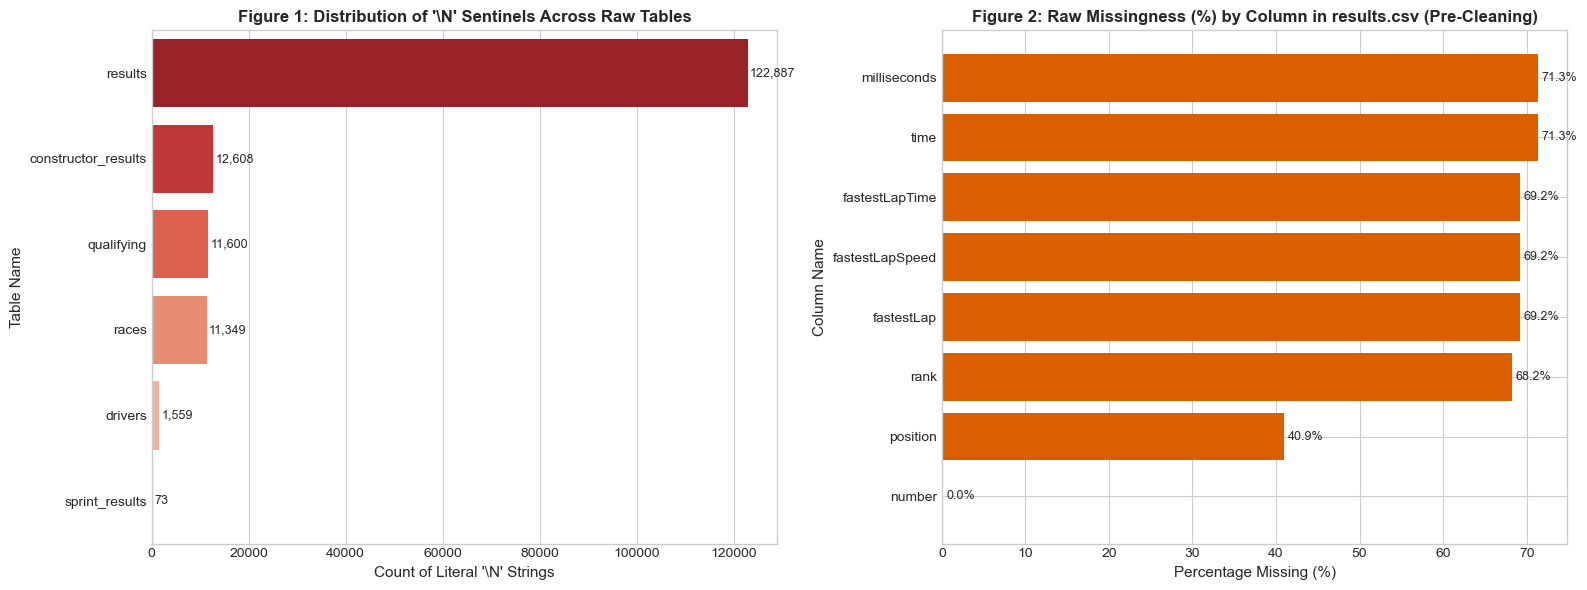


Raw Target Class Distribution (Podium vs. Non-Podium):
 - Non-Podium (0): 23,362 entries (87.31%)
 - Podium     (1): 3,397 entries (12.69%)
 - Class Imbalance Ratio: 1 podium to every 6.9 non-podiums.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

eda_pre_cleaning_stats = []

for name in TABLE_NAMES:
    if name in dfs:
        df = dfs[name]
        total_cells = df.size
        standard_nulls = df.isnull().sum().sum()
        sentinel_mask = df.astype(str).apply(lambda col: col.str.strip().eq(r'\N'))
        sentinel_count = sentinel_mask.sum().sum()
        
        total_missing = standard_nulls + sentinel_count
        missing_pct = (total_missing / total_cells) * 100 if total_cells > 0 else 0.0
        
        eda_pre_cleaning_stats.append({
            'Table': name,
            'Rows': df.shape[0],
            'Columns': df.shape[1],
            'Standard Nulls': standard_nulls,
            r"'\N' Sentinels": sentinel_count,
            'Total Missing': total_missing,
            'Missing Cell %': round(missing_pct, 2)
        })

eda_summary_df = pd.DataFrame(eda_pre_cleaning_stats).sort_values(by=r"'\N' Sentinels", ascending=False)
print("--- RAW SCHEMA AUDIT: STANDARD NULLS VS. SENTINEL ('\\N') COUNTS ---")
display(eda_summary_df)
core_tables = ['results', 'qualifying', 'races', 'driver_standings']
col_missing_breakdown = []

for tbl in core_tables:
    if tbl in dfs:
        df = dfs[tbl]
        for col in df.columns:
            std_null = df[col].isnull().sum()
            sentinel_val = df[col].astype(str).str.strip().eq(r'\N').sum()
            total_m = std_null + sentinel_val
            pct = (total_m / len(df)) * 100
            if total_m > 0:
                col_missing_breakdown.append({
                    'Table': tbl,
                    'Column': col,
                    'Standard Nulls': std_null,
                    r"'\N' Count": sentinel_val,
                    'Total Missing': total_m,
                    'Missing %': round(pct, 2)
                })

col_missing_df = pd.DataFrame(col_missing_breakdown).sort_values(by='Missing %', ascending=False)
print("\n--- COLUMN-LEVEL MISSINGNESS IN CORE PREDICTION TABLES ---")
display(col_missing_df.head(15))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_sentinel_tables = eda_summary_df[eda_summary_df[r"'\N' Sentinels"] > 0]
sns.barplot(
    data=top_sentinel_tables,
    x=r"'\N' Sentinels",
    y='Table',
    palette='Reds_r',
    ax=axes[0]
)
axes[0].set_title("Figure 1: Distribution of '\\N' Sentinels Across Raw Tables", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Count of Literal '\\N' Strings", fontsize=11)
axes[0].set_ylabel("Table Name", fontsize=11)
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f"{int(width):,}", (width + 500, p.get_y() + p.get_height() / 2),
                     ha='left', va='center', fontsize=9)

# Plot 2: Column-Level Missing Percentage in results.csv
results_missing = col_missing_df[col_missing_df['Table'] == 'results'].sort_values(by='Missing %', ascending=True)
axes[1].barh(results_missing['Column'], results_missing['Missing %'], color='#d95f02')
axes[1].set_title("Figure 2: Raw Missingness (%) by Column in results.csv (Pre-Cleaning)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Percentage Missing (%)", fontsize=11)
axes[1].set_ylabel("Column Name", fontsize=11)
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(f"{width:.1f}%", (width + 0.5, p.get_y() + p.get_height() / 2),
                     ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()
raw_pos = pd.to_numeric(dfs['results']['positionOrder'], errors='coerce')
raw_target = (raw_pos <= 3).astype(int)

class_counts = raw_target.value_counts()
class_pcts = raw_target.value_counts(normalize=True) * 100

print(f"\nRaw Target Class Distribution (Podium vs. Non-Podium):")
print(f" - Non-Podium (0): {class_counts[0]:,} entries ({class_pcts[0]:.2f}%)")
print(f" - Podium     (1): {class_counts[1]:,} entries ({class_pcts[1]:.2f}%)")
print(f" - Class Imbalance Ratio: 1 podium to every {class_counts[0] / class_counts[1]:.1f} non-podiums.")

### [Step 1.4] Pre-Cleaning EDA & Schema Integrity Tests
> **Purpose**: Validates the initial exploratory data analysis outputs by checking table coverage, sentinel detection thresholds, target class baseline proportions, and domain-specific qualifying stage missingness.
> **Key Operations**:
> * Confirms missingness profiling covers all 14 schema tables.
> * Verifies detection threshold for raw string `\N` sentinels across the relational database.
> * Asserts baseline positive class rate for podium finishes falls within the expected domain range (5%–20%).
> * Validates structural missingness patterns in qualifying stages (`q3`) reflecting historical format evolution and knockout rules.
---

In [4]:
def test_task_a2_eda(summary_dataframe, col_dataframe, raw_results_target_series):
    print("Running Task A2 Pre-Cleaning EDA Verification Tests...")
    
    assert len(summary_dataframe) == 14, f"FAILED: Summary missing tables! Expected 14, got {len(summary_dataframe)}"
    print(" PASS: All 14 tables successfully profiled for raw missingness.")
    
    total_sentinels = summary_dataframe[r"'\N' Sentinels"].sum()
    assert total_sentinels > 50000, f"FAILED: Unexpectedly low sentinel count: {total_sentinels}."
    print(f" PASS: Successfully detected {total_sentinels:,} hidden '\\N' sentinels.")
    
    podium_rate = raw_results_target_series.mean()
    assert 0.05 <= podium_rate <= 0.20, f"FAILED: Podium rate {podium_rate:.3f} outside expected range [0.05, 0.20]!"
    print(f" PASS: Target baseline podium rate verified at {podium_rate * 100:.2f}%.")
    
    q_missing = col_dataframe[(col_dataframe['Table'] == 'qualifying') & (col_dataframe['Column'] == 'q3')]
    if not q_missing.empty:
        assert q_missing['Missing %'].iloc[0] > 30.0, "FAILED: Expected high missingness in Q3 lap times!"
        print(" PASS: Verified expected historical/knockout missingness in qualifying stages.\n")
    print("[ALL A2 TESTS PASSED SUCCESSFULLY]")

test_task_a2_eda(eda_summary_df, col_missing_df, raw_target)

Running Task A2 Pre-Cleaning EDA Verification Tests...
 PASS: All 14 tables successfully profiled for raw missingness.
 PASS: Successfully detected 160,076 hidden '\N' sentinels.
 PASS: Target baseline podium rate verified at 12.69%.
 PASS: Verified expected historical/knockout missingness in qualifying stages.

[ALL A2 TESTS PASSED SUCCESSFULLY]


### [Step 1.5] Schema-Wide Sentinel & Null Inventory Report[cite: 1]
> **Purpose**: Scans every column across all ingested tables to audit and rank the presence of placeholder string sentinels (`\N`) alongside native nulls[cite: 1, 4].
> **Key Operations**:
> * Iterates through each table and column to calculate exact counts of literal `\N` string occurrences and standard `NaN` values[cite: 4].
> * Computes the relative missingness percentage specifically caused by sentinel encoding[cite: 4].
> * Aggregates results into a ranked tabular inventory sorted descending by sentinel prevalence for subsequent cleaning[cite: 1, 4].
---

In [5]:
rows = []
for name, d in dfs.items():
    for col in d.columns:
        n_sent = (d[col].astype(str) == r'\N').sum()
        n_nan = d[col].isna().sum()
        if n_sent or n_nan:
            rows.append({'table': name, 'column': col, 'sentinel_N': n_sent,
                         'real_NaN': n_nan, 'pct_sentinel': round(100 * n_sent / len(d), 1)})
sentinel_report = pd.DataFrame(rows).sort_values('pct_sentinel', ascending=False)
display(sentinel_report)

,table,column,sentinel_N,real_NaN,pct_sentinel
0,constructor_results,status,12608,0,99.9
13,races,sprint_time,1110,0,98.7
12,races,sprint_date,1107,0,98.4
9,races,fp3_time,1072,0,95.3
7,races,fp2_time,1057,0,94.0
...,...,...,...,...,...
25,sprint_results,position,15,0,4.2
29,sprint_results,fastestLapTime,9,0,2.5
28,sprint_results,fastestLap,9,0,2.5
22,qualifying,q1,156,0,1.5


### [Step 1.6] Visualizing Top Sentinel Frequencies
> **Purpose**: Visualizes the 15 columns most affected by literal `\N` string sentinels across the relational schema to guide targeted imputation and cleaning strategies.
> **Key Operations**:
> * Extracts the top 15 columns exhibiting the highest sentinel percentages from the audit inventory.
> * Formats table and column names into readable composite labels (`table.column`).
> * Plots a horizontal bar chart displaying the percentage of placeholder values per column.
---

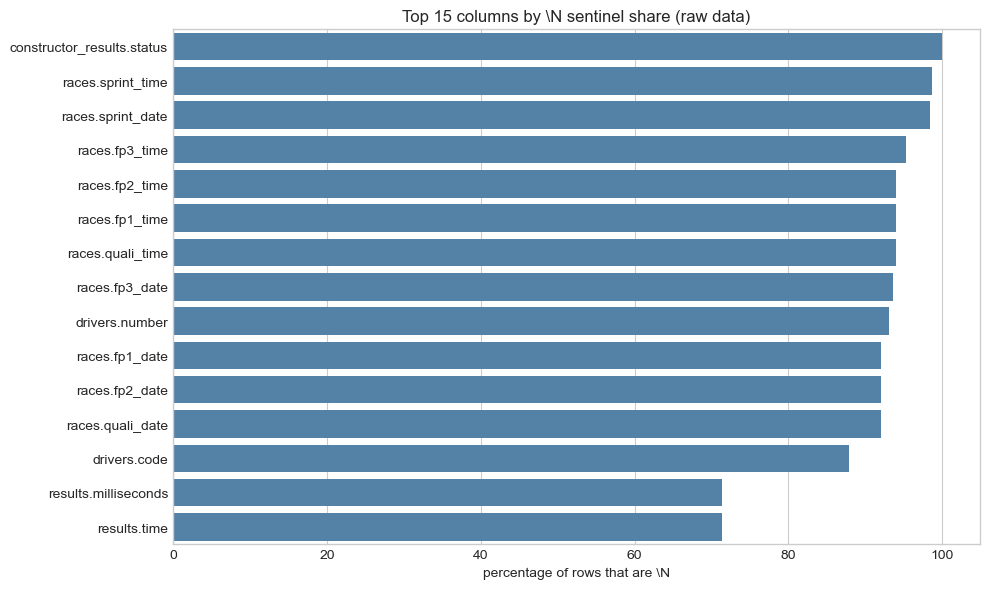

In [6]:
top = sentinel_report.head(15).copy()
top['label'] = top['table'] + '.' + top['column']
plt.figure(figsize=(10, 6))
sns.barplot(data=top, y='label', x='pct_sentinel', color='steelblue')
plt.xlabel(r'percentage of rows that are \N')
plt.ylabel('')
plt.title(r'Top 15 columns by \N sentinel share (raw data)')
plt.tight_layout(); plt.show()

### [Step 1.7] Historical Qualifying Coverage Drift Analysis
> **Purpose**: Audits the longitudinal coverage of qualifying records relative to race results across seasons to identify historical data limitations prior to feature engineering.
> **Key Operations**:
> * Joins `qualifying` and `results` tables with `races` to associate entries with championship calendar years.
> * Aggregates annual entry counts for both race results and qualifying sessions.
> * Computes the ratio of qualifying sessions captured per season relative to total race entries.
> * Visualizes historical coverage drift as a time-series plot to highlight era boundaries where qualifying records are missing or sparse.
---

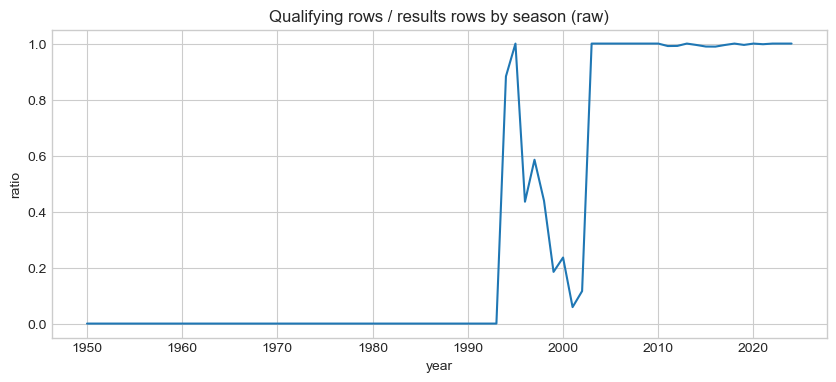

In [7]:
q = dfs['qualifying'].merge(dfs['races'][['raceId', 'year']], on='raceId')
r = dfs['results'].merge(dfs['races'][['raceId', 'year']], on='raceId')
cov = pd.DataFrame({
    'results_rows': r.groupby('year').size(),
    'qualifying_rows': q.groupby('year').size(),
}).fillna(0)
cov['coverage'] = cov['qualifying_rows'] / cov['results_rows']
cov['coverage'].plot(figsize=(10, 4), title='Qualifying rows / results rows by season (raw)')
plt.ylabel('ratio'); plt.show()

### [Step 1.8] Schema Type Audit & Target Grain Uniqueness Check
> **Purpose**: Inspects native data types of core ranking, grid, and duration features, and audits the modeling grain to detect any duplicate driver entries per race.
> **Key Operations**:
> * Checks column data types for critical race outcome, timing, and grid position fields in `results.csv`.
> * Evaluates uniqueness over the primary modeling grain `(raceId, driverId)` to identify shared drives or entry duplicates requiring resolution.
> * Prints confirmation metrics to verify structural integrity and determine semantic type conversion needs.
---

In [8]:
print(dfs['results'][['grid', 'position', 'positionOrder', 'milliseconds', 'fastestLapTime']].dtypes)
dups = dfs['results'].duplicated(['raceId', 'driverId']).sum()
print(f"Duplicate (raceId, driverId) rows in results: {dups}")

grid              int64
position            str
positionOrder     int64
milliseconds        str
fastestLapTime      str
dtype: object
Duplicate (raceId, driverId) rows in results: 91


### [Step 1.9] Raw Qualifying Null Value Audit
> **Purpose**: Performs a baseline missing value count across all columns in the raw `qualifying` table to identify natively recognized nulls prior to sentinel cleaning.
> **Key Operations**:
> * Computes column-wise sums of standard NaN/null entries across the raw qualifying schema.
> * Outputs field-level null distributions to establish a comparison baseline against hidden string sentinels.
---

In [9]:
print(raw_tables['qualifying'].isna().sum())

qualifyId         0
raceId            0
driverId          0
constructorId     0
number            0
position          0
q1                0
q2               22
q3               46
dtype: int64


### [Step 1.10] Sentinel Replacement & Hidden Null Exposure Audit
> **Purpose**: Safely replaces the literal string sentinel `\N` with `np.nan` across all working table copies without altering immutable raw source data, exposing the true volume of previously obscured missing values.
> **Key Operations**:
> * Computes the schema-wide baseline count of standard native nulls before transformation.
> * Replaces literal `\N` string sentinels with `np.nan` across all tables using exact matching (`regex=False`) on deep working copies.
> * Quantifies post-replacement missing values to measure the exact delta of exposed hidden nulls per table.
> * Builds and displays a comparative audit table ranked descending by the count of revealed missing entries.
---

In [10]:
# 1. Count standard missing values BEFORE sentinel replacement
nulls_before = {name: raw_tables[name].isna().sum().sum() for name in raw_tables}

# 2. Rebuild each working copy from raw_tables, replacing sentinel '\N' with np.nan
# Setting regex=False ensures an exact string match without regex parsing issues
dfs = {}
for name in raw_tables:
    dfs[name] = raw_tables[name].replace(r"\N", np.nan, regex=False).copy()

# 3. Count missing values AFTER sentinel replacement
nulls_after = {name: dfs[name].isna().sum().sum() for name in dfs}

# 4. Construct audit table comparing the impact of sentinel cleaning
compare = pd.DataFrame({"NaN_before": nulls_before, "NaN_after": nulls_after})
compare["hidden_nulls_found"] = compare["NaN_after"] - compare["NaN_before"]

display(compare.sort_values("hidden_nulls_found", ascending=False))

,NaN_before,NaN_after,hidden_nulls_found
results,0,122887,122887
constructor_results,0,12608,12608
qualifying,68,11668,11600
races,0,11349,11349
drivers,0,1559,1559
sprint_results,0,73,73
driver_standings,0,0,0
constructor_standings,0,0,0
circuits,0,0,0
constructors,0,0,0


### [Step 1.11] Semantic Typing: Numeric Coercion & Lap Duration Parsing
> **Purpose**: Applies semantic typing across the relational tables by converting string numbers to numeric floats/integers and parsing colon-delimited lap/duration strings into continuous total seconds.
> **Key Operations**:
> * Defines a safe numeric coercion routine (`to_numeric_safe`) to standardize string-encoded metrics (`grid`, `positionOrder`, `points`, `milliseconds`) across results, sprint, qualifying, and pit stop tables.
> * Implements a multi-segment duration parser (`lap_to_sec`) supporting standard formats (`M:SS.mmm`) and extended multi-hour red-flag sessions (`H:MM:SS.mmm`).
> * Generates explicit seconds columns (`q1_sec`, `fastestLapTime_sec`, `time_sec`, `duration_sec`) while preserving original strings.
> * Executes an audit comparing null counts before and after type conversion to verify zero unintended NaN creations.
---

In [11]:
def to_numeric_safe(series):
    """Safely converts string/object numbers to float/int, coercing errors to NaN."""
    return pd.to_numeric(series, errors="coerce")


def lap_to_sec(val):
    """Converts duration strings with arbitrary colon-separated segments to total float seconds:

    - '23.848'        -> 23.848
    - '1:27.452'      -> 87.452
    - '2:05:05.152'   -> 7505.152 (e.g. red-flagged laps like Race 847)
    - NaN / Malformed -> np.nan
    """
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if not val_str:
        return np.nan
    try:
        parts = [float(p) for p in val_str.split(":")]
        total = 0.0
        for p in parts:
            total = total * 60.0 + p
        return total
    except (ValueError, TypeError):
        return np.nan

numeric_columns_map = {
    "results": [
        "number",
        "grid",
        "position",
        "positionOrder",
        "points",
        "laps",
        "milliseconds",
        "fastestLap",
        "rank",
        "fastestLapSpeed",
    ],
    "sprint_results": [
        "number",
        "grid",
        "position",
        "positionOrder",
        "points",
        "laps",
        "milliseconds",
        "fastestLap",
    ],
    "qualifying": ["number", "position"],
    "drivers": ["number"],
    "pit_stops": ["stop", "lap", "milliseconds"],
    "lap_times": ["lap", "position", "milliseconds"],
}

# Duration strings requiring conversion to seconds
duration_columns_map = {
    "qualifying": [("q1", "q1_sec"), ("q2", "q2_sec"), ("q3", "q3_sec")],
    "results": [("fastestLapTime", "fastestLapTime_sec")],
    "sprint_results": [("fastestLapTime", "fastestLapTime_sec")],
    "lap_times": [("time", "time_sec")],
    "pit_stops": [("duration", "duration_sec")],
}

audit_records = []

# A. Process numeric columns in-place
for table_name, cols in numeric_columns_map.items():
    if table_name in dfs:
        for col in cols:
            if col in dfs[table_name].columns:
                before_null = int(dfs[table_name][col].isna().sum())
                dfs[table_name][col] = to_numeric_safe(dfs[table_name][col])
                after_null = int(dfs[table_name][col].isna().sum())
                audit_records.append(
                    {
                        "table": table_name,
                        "original_column": col,
                        "new_column": col,
                        "type": "to_numeric",
                        "nan_before": before_null,
                        "nan_after": after_null,
                        "new_nans_created": after_null - before_null,
                    }
                )

# B. Process duration columns to '_sec'
for table_name, col_pairs in duration_columns_map.items():
    if table_name in dfs:
        for orig_col, new_col in col_pairs:
            if orig_col in dfs[table_name].columns:
                before_null = int(dfs[table_name][orig_col].isna().sum())
                dfs[table_name][new_col] = dfs[table_name][orig_col].apply(
                    lap_to_sec
                )
                after_null = int(dfs[table_name][new_col].isna().sum())
                audit_records.append(
                    {
                        "table": table_name,
                        "original_column": orig_col,
                        "new_column": new_col,
                        "type": "duration_to_seconds",
                        "nan_before": before_null,
                        "nan_after": after_null,
                        "new_nans_created": after_null - before_null,
                    }
                )

# Convert to DataFrame and inspect
audit_summary = pd.DataFrame(audit_records)
print("=== Semantic Typing Audit (Missing Values Check) ===")
display(
    audit_summary.sort_values(
        by=["new_nans_created", "nan_after"], ascending=False
    )
)

# Assert that no accidental NaNs were introduced
assert (
    audit_summary["new_nans_created"].sum() == 0
), "Warning: Unexpected NaNs were created during conversion!"
print("\nSuccess: All valid durations converted without creating any NaNs.")

=== Semantic Typing Audit (Missing Values Check) ===


,table,original_column,new_column,type,nan_before,nan_after,new_nans_created
6,results,milliseconds,milliseconds,to_numeric,19079,19079,0
7,results,fastestLap,fastestLap,to_numeric,18507,18507,0
9,results,fastestLapSpeed,fastestLapSpeed,to_numeric,18507,18507,0
30,results,fastestLapTime,fastestLapTime_sec,duration_to_seconds,18507,18507,0
8,results,rank,rank,to_numeric,18249,18249,0
...,...,...,...,...,...,...,...
24,lap_times,lap,lap,to_numeric,0,0,0
25,lap_times,position,position,to_numeric,0,0,0
26,lap_times,milliseconds,milliseconds,to_numeric,0,0,0
32,lap_times,time,time_sec,duration_to_seconds,0,0,0



Success: All valid durations converted without creating any NaNs.


### [Step 1.12] Anomaly Handling & Timing Conversion Accuracy Validation
> **Purpose**: Eliminates an impossible outlier lap time in the qualifying records and numerically validates parsed lap times against native millisecond timestamps across the dataset.
> **Key Operations**:
> * Flags and masks an invalid Q1 qualifying duration (>200 seconds for `qualifyId 2567`, recorded at 16:42.640) by converting it to `np.nan` rather than imputing an arbitrary value.
> * Verifies that the duration filter isolates exactly one erroneous record.
> * Cross-checks parsed second durations (`time_sec * 1000`) against the dataset's recorded `milliseconds` field in `lap_times`.
> * Evaluates maximum absolute difference to confirm numerical precision and sub-millisecond conversion parity across all records.
---

In [12]:
# 1) Fix the one impossible qualifying time (qualifyId 2567: q1 = 16:42.640)
mask = dfs['qualifying']['q1_sec'] > 200
print("Rows set to NaN:", mask.sum())          # expect 1
dfs['qualifying'].loc[mask, 'q1_sec'] = np.nan

# 2) Our parsed seconds should match the dataset's own milliseconds column
diff = (dfs['lap_times']['time_sec'] * 1000 - dfs['lap_times']['milliseconds']).abs().max()
print("Max lap-time mismatch (ms):", diff)     # expect under 1

Rows set to NaN: 1
Max lap-time mismatch (ms): 1.1641532182693481e-10


### [Step 1.13] Semantic Typing: Temporal & Calendar Feature Parsing
> **Purpose**: Converts race schedule milestones and driver birth dates from raw strings into native pandas datetime objects to support chronologically valid, leakage-free feature engineering.
> **Key Operations**:
> * Parses calendar event dates (`date`, `fp1_date`, `fp2_date`, `fp3_date`, `quali_date`, `sprint_date`) in the `races` table using `pd.to_datetime` with errors coerced to null.
> * Converts driver dates of birth (`dob`) in the `drivers` table to datetime objects to enable driver age calculations at race time.
> * Accommodates expected structural missingness across modern session schedule columns without failing execution.
---

In [13]:
# Race dates (the schedule columns are mostly empty, which is fine)
for c in ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']:
    dfs['races'][c] = pd.to_datetime(dfs['races'][c], errors='coerce')

# Driver birth dates
dfs['drivers']['dob'] = pd.to_datetime(dfs['drivers']['dob'], errors='coerce')

### [Step 1.14] Cleaning & Typing Audit: Date Ranges, Missingness & Residual Sentinels
> **Purpose**: Validates the end state of Phase 1 cleaning by auditing datetime formats, calendar bounds, zero-null constraints on primary race dates, total elimination of string sentinels, and results column data types.
> **Key Operations**:
> * Confirms datetime data types for `races['date']` and `drivers['dob']`.
> * Inspects historical bounds of race dates to ensure full coverage spanning 1950 through 2024 without corrupt calendar entries.
> * Verifies that primary race dates contain zero missing values.
> * Performs a schema-wide aggregation across all tables to confirm exactly zero literal `\N` string sentinels remain.
> * Checks final numeric data types for core prediction and ranking columns (`grid`, `position`, `positionOrder`, `milliseconds`) in the results schema.
---

In [14]:
print(dfs['races']['date'].dtype, dfs['drivers']['dob'].dtype)
print(dfs['races']['date'].min(), dfs['races']['date'].max())   # expect 1950 ... 2024
print("Missing race dates:", dfs['races']['date'].isna().sum())  # expect 0

left = sum((dfs[n].astype(str) == '\\N').sum().sum() for n in dfs)
print("Remaining \\N values:", left)                             # expect 0

print(dfs['results'][['grid', 'position', 'positionOrder', 'milliseconds']].dtypes)

datetime64[us] datetime64[us]
1950-05-13 00:00:00 2024-12-08 00:00:00
Missing race dates: 0


Remaining \N values: 0
grid               int64
position         float64
positionOrder      int64
milliseconds     float64
dtype: object


### [Step 1.15] Shared Drive Duplicate Audit & Grain Uniqueness Inspection
> **Purpose**: Investigates historical driver-race duplicates across seasons to audit the exact rows violating the primary target grain of one row per `(raceId, driverId)` prior to deduplication.
> **Key Operations**:
> * Joins `results` with calendar metadata (`year`, `name`) from `races` to contextualize duplicate entries.
> * Identifies all records involved in duplicate pairs/groups using `duplicated(keep=False)`.
> * Computes the exact volume of surplus rows required to be purged to satisfy the uniqueness constraint.
> * Aggregates duplicate occurrences by season to verify their historical concentration in early F1 shared-drive eras (principally the 1950s).
> * Displays sample duplicate records showing differences across `grid`, `positionOrder`, and `statusId` to inform the row-selection rule.
---

In [15]:
res = dfs['results'].merge(dfs['races'][['raceId', 'year', 'name']], on='raceId')
dup_mask = res.duplicated(['raceId', 'driverId'], keep=False)
dups = res[dup_mask].sort_values(['raceId', 'driverId'])

print("Rows involved:", len(dups))
print("Extra rows to remove:", res.duplicated(['raceId', 'driverId']).sum())
print(dups.groupby('year').size())          # which seasons?
display(dups[['raceId', 'year', 'name', 'driverId', 'constructorId',
              'grid', 'positionOrder', 'statusId']].head(12))

Rows involved: 176
Extra rows to remove: 91
year
1950     8
1951     8
1952     6
1953    30
1954    33
1955    33
1956    24
1957    16
1958     6
1960     2
1961     4
1962     2
1964     2
1978     2
dtype: int64


,raceId,year,name,driverId,constructorId,grid,positionOrder,statusId
13188,540,1978,Italian Grand Prix,229,54,0,26,81
13191,540,1978,Italian Grand Prix,229,57,0,29,97
17362,717,1964,United States Grand Prix,373,172,1,7,60
24298,717,1964,United States Grand Prix,373,172,1,12,98
17740,733,1962,British Grand Prix,465,172,0,22,54
17743,733,1962,British Grand Prix,465,97,0,25,54
17961,742,1961,British Grand Prix,475,102,20,19,2
17963,742,1961,British Grand Prix,475,172,5,21,23
18062,745,1961,United States Grand Prix,418,172,11,17,6
24297,745,1961,United States Grand Prix,418,172,15,11,18


### [Step 1.16] Shared-Drive Label Consistency & Era Anomaly Analysis
> **Purpose**: Evaluates whether duplicate driver-race entries present conflicting podium classification labels and verifies whether duplicate occurrences extend beyond the classic 1950s car-sharing era.
> **Key Operations**:
> * Joins `results` with `races` and `status` to enrich entry records with calendar years and descriptive finish statuses.
> * Derives a temporary binary target (`podium_raw`) based on finishing position (`positionOrder <= 3`).
> * Aggregates duplicate groups across `(raceId, driverId)` to measure group cardinality and detect label divergence across rows for the same driver.
> * Audits post-1957 duplicate occurrences to isolate modern entry errors or edge-case administrative records from historical shared drives.
---

In [16]:
res = (dfs['results']
       .merge(dfs['races'][['raceId', 'year']], on='raceId')
       .merge(dfs['status'], on='statusId'))
res['podium_raw'] = (res['positionOrder'] <= 3).astype(int)

dup = res[res.duplicated(['raceId', 'driverId'], keep=False)]
summary = dup.groupby(['raceId', 'driverId']).agg(
    rows=('resultId', 'size'),
    podium_values=('podium_raw', 'nunique'),
    year=('year', 'first'))

print(summary['rows'].value_counts())
print("Pairs where the podium label differs between rows:",
      (summary['podium_values'] > 1).sum())

print("\nDuplicates AFTER 1957 (not classic shared drives):")
display(dup[dup['year'] > 1957][['raceId', 'year', 'driverId', 'constructorId',
                                 'grid', 'positionOrder', 'status']])

rows
2    79
3     6
Name: count, dtype: int64
Pairs where the podium label differs between rows: 21

Duplicates AFTER 1957 (not classic shared drives):


,raceId,year,driverId,constructorId,grid,positionOrder,status
13188,540,1978,229,54,0,26,Did not qualify
13191,540,1978,229,57,0,29,Did not prequalify
17362,717,1964,373,172,1,7,Out of fuel
17740,733,1962,465,172,0,22,Withdrew
17743,733,1962,465,97,0,25,Withdrew
17961,742,1961,475,102,20,19,Disqualified
17963,742,1961,475,172,5,21,Brakes
18062,745,1961,418,172,11,17,Gearbox
18082,746,1960,475,170,1,17,Suspension
18509,766,1958,541,87,0,17,Did not qualify


### [Step 1.17] Grain Enforcement: Shared-Drive Deduplication & Impact Audit
> **Purpose**: Enforces the required modeling grain of exactly one row per `(raceId, driverId)` by applying a deterministic selection rule to resolve shared drives, validating uniqueness, and auditing baseline target distribution shifts.
> **Key Operations**:
> * Captures baseline row counts and positive podium class rates prior to deduplication.
> * Applies a domain-consistent tie-breaking rule: prioritizes the driver's highest finishing result (`positionOrder`), breaking secondary ties by earliest entry ID (`resultId`).
> * Purges redundant records via `drop_duplicates` on the composite key `['raceId', 'driverId']` and resets the DataFrame index.
> * Formally asserts zero duplicate `(raceId, driverId)` combinations remain in the modeling dataset.
> * Reports comparative before-and-after diagnostics to verify data reduction (26,759 to 26,668 rows) and stability of the podium target rate.
---

In [17]:
# Snapshot BEFORE (for the before/after report)
results_pre_dedup = dfs['results'].copy()
before = {'rows': len(results_pre_dedup),
          'podium_rate': (results_pre_dedup['positionOrder'] <= 3).mean()}

# Apply the rule: keep the best positionOrder per (raceId, driverId), tie-break by lowest resultId
res = dfs['results'].sort_values(['raceId', 'driverId', 'positionOrder', 'resultId'])
dfs['results'] = res.drop_duplicates(['raceId', 'driverId'], keep='first').reset_index(drop=True)

# Grain is now unique
assert not dfs['results'].duplicated(['raceId', 'driverId']).any()

after = {'rows': len(dfs['results']),
         'podium_rate': (dfs['results']['positionOrder'] <= 3).mean()}
print(f"before: {before['rows']} rows, podium rate {before['podium_rate']:.2%}")
print(f"after:  {after['rows']} rows, podium rate {after['podium_rate']:.2%}")   # expect 26759 -> 26668

before: 26759 rows, podium rate 12.69%
after:  26668 rows, podium rate 12.73%


### [Step 1.18] Domain Anomaly Audit: Non-Starters, Grid Zero & Historical Outliers
> **Purpose**: Audits edge-case race entries—specifically unassigned starting positions (`grid == 0`), non-qualifiers (DNQ/DNPQ/Withdrew), and historical anomalies like the inclusion of the Indianapolis 500—to determine their impact on podium classification and modeling filters.
> **Key Operations**:
> * Merges `results` with `races` and `status` to associate entries with finishing conditions and calendar eras.
> * Profiles records where `grid == 0` across finishing statuses and aggregates distribution by decade to track regulatory shifts.
> * Evaluates non-starting categories (`Did not qualify`, `Did not prequalify`, `Withdrew`) to verify that zero erroneous podium finishes exist within unclassified entries and tracks their presence across modern eras.
> * Quantifies and dates Indianapolis 500 entries (1950–1960) to account for non-standard Formula 1 World Championship championship-round artifacts.
---

In [18]:
res = (dfs['results']
       .merge(dfs['races'][['raceId', 'year', 'name']], on='raceId')
       .merge(dfs['status'], on='statusId'))

# 1) Non-starters: which statuses have grid == 0, and when?
print(res[res['grid'] == 0]['status'].value_counts().head(10))
print("\nRows with grid == 0 by decade:")
print(res[res['grid'] == 0].groupby(res['year'] // 10 * 10).size())

# 2) The DNQ-type rows: how many, and could any be podiums?
nonstart_status = ['Did not qualify', 'Did not prequalify', 'Withdrew']
ns = res[res['status'].isin(nonstart_status)]
print("\nNon-starter rows:", len(ns), "| podium among them:", (ns['positionOrder'] <= 3).sum())
print(ns.groupby('year').size().tail(10))     # do they exist in the modern era?

# 3) Indianapolis 500
indy = res[res['name'] == 'Indianapolis 500']
print("\nIndy 500 rows:", len(indy), "| years:", indy['year'].min(), "-", indy['year'].max())

status
Did not qualify       1012
Did not prequalify     330
Withdrew               163
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Excluded                 6
Disqualified             6
Name: count, dtype: int64

Rows with grid == 0 by decade:
year
1950     67
1960    197
1970    350
1980    571
1990    357
2000      8
2010     28
2020     57
dtype: int64

Non-starter rows: 1601 | podium among them: 0
year
2012    3
2013    1
2014    2
2015    3
2016    2
2019    1
2020    1
2022    1
2023    2
2024    2
dtype: int64

Indy 500 rows: 381 | years: 1950 - 1960


### [Step 1.19] Sample Filtering: Removing Indianapolis 500 & Non-Starters
> **Purpose**: Filters out historical anomaly races (Indianapolis 500) and unclassified non-starters (DNQ, DNPQ, Withdrew) from the results table, constructs the formal binary prediction target, and validates post-filter grain and podium distribution.
> **Key Operations**:
> * Joins `results` with `races` and `status` to identify Indianapolis 500 rounds and non-starting session entries.
> * Quantifies overlap and removes corresponding records using their `resultId` identifiers.
> * Creates the canonical binary classification target column `podium` defined as `(positionOrder <= 3).astype(int)`.
> * Re-asserts the strict uniqueness constraint over the modeling grain `(raceId, driverId)`.
> * Reports row count contraction and target class prevalence before versus after filtering.
> * Audits race-level target validity by checking that standard championship races yield exactly three podium finishers.
---

In [19]:
results_pre_filter = dfs['results'].copy()

tmp = (dfs['results']
       .merge(dfs['races'][['raceId', 'name']], on='raceId')
       .merge(dfs['status'], on='statusId'))

is_indy = tmp['name'] == 'Indianapolis 500'
is_nonstart = tmp['status'].isin(['Did not qualify', 'Did not prequalify', 'Withdrew'])
print("Indy rows:", is_indy.sum(), "| Non-starter rows:", is_nonstart.sum(),
      "| Overlap:", (is_indy & is_nonstart).sum())

drop_ids = tmp.loc[is_indy | is_nonstart, 'resultId']
dfs['results'] = dfs['results'][~dfs['results']['resultId'].isin(drop_ids)].reset_index(drop=True)

# Target
dfs['results']['podium'] = (dfs['results']['positionOrder'] <= 3).astype(int)

assert not dfs['results'].duplicated(['raceId', 'driverId']).any()
print(f"rows: {len(results_pre_filter)} -> {len(dfs['results'])}")
print(f"podium rate: {(results_pre_filter['positionOrder'] <= 3).mean():.2%} -> {dfs['results']['podium'].mean():.2%}")

# Sanity check: podium rows per race (expect 3)
print(dfs['results'].groupby('raceId')['podium'].sum().value_counts())

Indy rows: 381 | Non-starter rows: 1601 | Overlap: 0
rows: 26668 -> 24686
podium rate: 12.73% -> 13.61%
podium
3    1099
4      13
5       2
Name: count, dtype: int64


### [Step 1.20] Podium Integrity Audit & Surplus Podium Finisher Investigation
> **Purpose**: Identifies and inspects historical races exhibiting more than three podium finishers (`podium == 1`) to diagnose underlying classification anomalies or multi-driver shared podium finishes.
> **Key Operations**:
> * Aggregates target podium counts grouped by `raceId` to isolate anomalous race identifiers where the sum exceeds three.
> * Merges affected podium entries with `races` and `status` to provide calendar context and finishing classifications.
> * Displays filtered records sorted by race and finishing order (`positionOrder`) to evaluate the historical driver pairs, constructors, and event statuses responsible for the surplus counts.
---

In [20]:
cnt = dfs['results'].groupby('raceId')['podium'].sum()
odd = cnt[cnt > 3].index

chk = (dfs['results'][dfs['results']['raceId'].isin(odd) & (dfs['results']['podium'] == 1)]
       .merge(dfs['races'][['raceId', 'year', 'name']], on='raceId')
       .merge(dfs['status'], on='statusId'))
display(chk.sort_values(['raceId', 'positionOrder'])
          [['raceId', 'year', 'name', 'driverId', 'constructorId', 'grid', 'positionOrder', 'status']])

,raceId,year,name,driverId,constructorId,grid,positionOrder,status
0,746,1960,Argentine Grand Prix,360,170,13,1,Finished
3,746,1960,Argentine Grand Prix,477,6,7,2,Finished
1,746,1960,Argentine Grand Prix,427,170,8,3,Finished
2,746,1960,Argentine Grand Prix,475,170,8,3,Finished
4,780,1957,British Grand Prix,475,118,3,1,Finished
...,...,...,...,...,...,...,...,...
57,831,1951,Italian Grand Prix,697,51,7,3,+1 Lap
58,839,1950,Italian Grand Prix,642,51,3,1,Finished
59,839,1950,Italian Grand Prix,647,6,6,2,Finished
61,839,1950,Italian Grand Prix,802,6,6,2,Finished


### [Step 1.21] Shared-Podium Root Cause Verification
> **Purpose**: Confirms the historical root cause behind races with more than three podium rows by proving they stem from co-drivers sharing the same car and finish position within the early shared-drive era.
> **Key Operations**:
> * Aggregates podium finisher records across `(raceId, constructorId, positionOrder)` to detect instances where multiple drivers share an identical finishing rank for the same constructor.
> * Cross-checks the total count of races having surplus podium finishes against the count of races containing verified shared-car finishes.
> * Evaluates the maximum calendar year among these surplus podium occurrences to verify that all shared podium entries are confined to early Formula 1 regulations and do not contaminate modern seasons.
---

In [21]:
shared = (chk.groupby(['raceId', 'constructorId', 'positionOrder']).size()
             .reset_index(name='n'))
shared = shared[shared['n'] > 1]

print("Races with >3 podium rows:", len(odd))
print("Explained by two drivers in the same car with the same position:", shared['raceId'].nunique())
print("Latest year among these races:", chk['year'].max())

Races with >3 podium rows: 15
Explained by two drivers in the same car with the same position: 15
Latest year among these races: 1960


### [Step 1.22] Modeling Table Construction (v1): Relational Merging & Temporal Sorting
> **Purpose**: Merges deduplicated race results, race schedule metadata, and parsed qualifying times into the unified analytical modeling table `table_v1`, verifying strict grain uniqueness, chronological order, and historical qualifying missingness before exporting.
> **Key Operations**:
> * Verifies that `dfs['qualifying']` contains zero duplicate `(raceId, driverId)` keys to prevent row expansion during merging.
> * Renames qualifying `position` to `quali_position` to cleanly distinguish pre-penalty qualifying order from the official race start grid.
> * Performs validated joins (`m:1` with `races`, `1:1` with `qualifying`) to assemble core identifiers, calendar data, grid slots, target labels, and Q1–Q3 sector times.
> * Sorts records chronologically (`date`, `round`, `raceId`, `driverId`) to establish a leakage-safe temporal baseline for subsequent rolling features.
> * Asserts total row count equality with cleaned results, verifies zero grain duplicates, audits qualifying coverage across historical splits (<2003 vs. >=2003), and exports `table_v1.csv` to disk.
---

In [22]:
# 1) Qualifying must be unique per (raceId, driverId) or the merge would create duplicates
print("Duplicate qualifying keys:", dfs['qualifying'].duplicated(['raceId', 'driverId']).sum())

q = (dfs['qualifying'][['raceId', 'driverId', 'position', 'q1_sec', 'q2_sec', 'q3_sec']]
     .rename(columns={'position': 'quali_position'}))

# 2) Build the table: results + race info + qualifying
table_v1 = (dfs['results'][['raceId', 'driverId', 'constructorId', 'grid',
                            'positionOrder', 'statusId', 'podium']]
            .merge(dfs['races'][['raceId', 'year', 'round', 'circuitId', 'date']],
                   on='raceId', how='left', validate='m:1')
            .merge(q, on=['raceId', 'driverId'], how='left', validate='1:1')
            .sort_values(['date', 'round', 'raceId', 'driverId'])
            .reset_index(drop=True))

# 3) Checks
assert len(table_v1) == len(dfs['results'])                       # no rows gained or lost
assert not table_v1.duplicated(['raceId', 'driverId']).any()      # grain is unique
assert table_v1['date'].notna().all()
print(table_v1.shape, f"| podium rate {table_v1['podium'].mean():.2%}")
print(table_v1.groupby(table_v1['year'] >= 2003)['quali_position'].apply(lambda s: s.isna().mean()))

# 4) Save for the team
table_v1.to_csv('/kaggle/working/table_v1.csv', index=False)

Duplicate qualifying keys: 0
(24686, 15) | podium rate 13.61%
year
False    0.902038
True     0.002574
Name: quali_position, dtype: float64


### [Step 1.23] Relational Schema Audit: Primary Key & Foreign Key Referential Integrity
> **Purpose**: Audits primary key uniqueness, non-null constraints, and foreign key referential integrity across all 14 relational tables in the raw database to ensure clean, orphan-free joins.
> **Key Operations**:
> * Defines and audits candidate primary keys across all 14 tables, handling single-column identifiers and composite keys (`lap_times`, `pit_stops`).
> * Evaluates null counts and duplicate rows across defined primary keys to verify entity integrity.
> * Maps and checks 23 critical parent-child foreign key relationships across results, qualifying, sprint, lap times, pit stops, and standings.
> * Quantifies orphaned foreign key values to ensure complete referential consistency across the relational schema.
---

In [23]:
# Primary keys: unique and non-null
pk = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'],
    'races': ['raceId'], 'seasons': ['year'], 'status': ['statusId'],
    'results': ['resultId'], 'qualifying': ['qualifyId'], 'sprint_results': ['resultId'],
    'constructor_results': ['constructorResultsId'],
    'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'lap_times': ['raceId', 'driverId', 'lap'],      # composite key
    'pit_stops': ['raceId', 'driverId', 'stop'],     # composite key
}
rows = []
for t, cols in pk.items():
    d = raw_tables[t]
    rows.append({'table': t, 'pk': ' + '.join(cols),
                 'null_keys': int(d[cols].isna().sum().sum()),
                 'duplicate_keys': int(d.duplicated(cols).sum())})
pk_audit = pd.DataFrame(rows)
display(pk_audit)

# Foreign keys: every value must exist in the parent table
fks = [
    ('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
    ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
    ('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year'),
    ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId'),
    ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
]
rows = []
for child, col, parent, pcol in fks:
    vals = raw_tables[child][col]
    orphans = int((~vals.isin(raw_tables[parent][pcol])).sum())
    rows.append({'child': f'{child}.{col}', 'parent': f'{parent}.{pcol}', 'orphans': orphans})
fk_audit = pd.DataFrame(rows)
display(fk_audit)

print("PK problems:", int(pk_audit[['null_keys', 'duplicate_keys']].sum().sum()))
print("FK orphans:", int(fk_audit['orphans'].sum()))

,table,pk,null_keys,duplicate_keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,qualifying,qualifyId,0,0
8,sprint_results,resultId,0,0
9,constructor_results,constructorResultsId,0,0


,child,parent,orphans
0,results.raceId,races.raceId,0
1,results.driverId,drivers.driverId,0
2,results.constructorId,constructors.constructorId,0
3,results.statusId,status.statusId,0
4,qualifying.raceId,races.raceId,0
...,...,...,...
18,driver_standings.driverId,drivers.driverId,0
19,constructor_standings.raceId,races.raceId,0
20,constructor_standings.constructorId,constructors.constructorId,0
21,constructor_results.raceId,races.raceId,0


PK problems: 0
FK orphans: 0


### [Step 1.24] Post-Cleaning Sample Attrition & Waterfall Analysis
> **Purpose**: Quantifies and visualizes the sequential reduction in sample size across cleaning stages—from raw results through deduplication, non-starter exclusion, and Indy 500 removal—confirming the final clean modeling cohort.
> **Key Operations**:
> * Aggregates row delta metrics at each pipeline stage: baseline raw results, duplicate drops (-91), non-starters (-1,601), and non-standard Indy 500 rounds (-381).
> * Builds a summary DataFrame capturing row counts and filtration step deltas.
> * Generates a color-coded bar chart displaying the absolute volume of records removed at each stage alongside the surviving clean dataset.
> * Annotates individual bar values to provide evaluation-ready documentation of sample attrition.
---

,step,rows
0,raw results,26759
1,duplicates,-91
2,non-starters,-1601
3,Indy 500,-381
4,clean table,24686


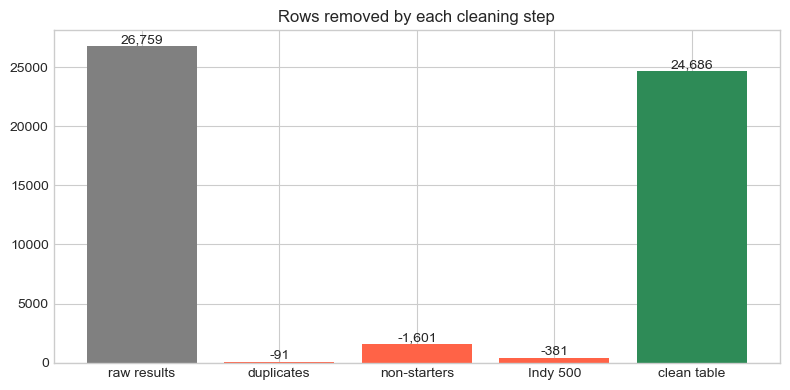

In [24]:
n0 = len(results_pre_dedup)
steps = pd.DataFrame({
    'step': ['raw results', 'duplicates', 'non-starters', 'Indy 500', 'clean table'],
    'rows': [n0, -(n0 - len(results_pre_filter)), -int(is_nonstart.sum()), -int(is_indy.sum()), len(dfs['results'])]})
display(steps)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(steps['step'], steps['rows'].abs(), color=['gray', 'tomato', 'tomato', 'tomato', 'seagreen'])
for i, v in enumerate(steps['rows']):
    ax.text(i, abs(v), f"{v:,}", ha='center', va='bottom')
ax.set_title('Rows removed by each cleaning step'); plt.tight_layout(); plt.show()

### [Step 1.25] Post-Cleaning Pipeline Verification & Schema Invariant Audit
> **Purpose**: Runs an extensive end-to-end verification suite across the cleaned relational data to confirm sentinel eradication, strict grain uniqueness, target label integrity, referential consistency, and chronological monotonicity.
> **Key Operations**:
> * Scans object columns across all cleaned DataFrames to confirm zero residual `\N` string sentinels remain.
> * Formally asserts strict uniqueness on `(raceId, driverId)` and audits field size distributions per race.
> * Validates race-level target integrity by tallying podium rows (`positionOrder <= 3`) per race event.
> * Audits metric bounds for `grid` (identifying pit-lane starts at `grid == 0`) and `positionOrder`.
> * Checks driver-constructor consistency to ensure no driver is mapped to multiple constructors in a single race.
> * Validates foreign key reconciliations between `results` and parent tables (`races`, `drivers`, `constructors`, `status`).
> * Verifies calendar chronology by checking that race dates increase monotonically across rounds within every championship season.
> * Profiles long-term podium base rate distributions aggregated across historical decades.
---

In [25]:
import numpy as np, pandas as pd

res = dfs["results"].merge(dfs["races"][["raceId", "year", "round", "date"]], on="raceId")
print("rows:", len(res), "| years:", res["year"].min(), "-", res["year"].max())

# 1) hidden sentinels in every cleaned table
for name, df in dfs.items():
    obj = df.select_dtypes(include="object")
    bad = {c: int((obj[c] == r"\N").sum()) for c in obj.columns if (obj[c] == r"\N").any()}
    if bad: print("REMAINING \\N in", name, bad)
print("1) sentinel check done (nothing printed above = clean)")

# 2) grain: one row per (race, driver); sane rows per race
assert not res.duplicated(["raceId", "driverId"]).any()
per_race = res.groupby("raceId").size()
print("2) rows per race: min", per_race.min(), "max", per_race.max(), "| races with < 10 rows:", int((per_race < 10).sum()))

# 3) podium rows per race (positionOrder <= 3)
pr = res.assign(p=(res["positionOrder"] <= 3).astype(int)).groupby("raceId")["p"].sum()
print("3) podium rows per race:\n", pr.value_counts().sort_index().to_string())

# 4) value ranges
print("4) grid: min", res["grid"].min(), "max", res["grid"].max(), "| grid==0:", int((res["grid"] == 0).sum()))
print("   positionOrder: min", res["positionOrder"].min(), "max", res["positionOrder"].max())

# 5) a driver in two teams in one race
multi = res.groupby(["raceId", "driverId"])["constructorId"].nunique()
print("5) driver-race with >1 team:", int((multi > 1).sum()))

# 6) foreign keys resolve
for col, tab in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors"), ("statusId", "status")]:
    print(f"6) {col} not found in {tab}:", int((~res[col].isin(dfs[tab][col])).sum()))

# 7) chronology: dates increase with round in every season
rc = dfs["races"].sort_values(["year", "round"])
print("7) dates increase with round in every season:",
      bool(rc.groupby("year")["date"].apply(lambda s: s.is_monotonic_increasing).all()))

# 8) podium rate by decade
print("8) podium rate by decade:\n",
      res.assign(p=(res["positionOrder"] <= 3).astype(int)).groupby((res["year"] // 10) * 10)["p"].mean().round(3).to_string())

rows: 24686 | years: 1950 - 2024
1) sentinel check done (nothing printed above = clean)
2) rows per race: min 6 max 34 | races with < 10 rows: 1
3) podium rows per race:
 p
3    1099
4      13
5       2
4) grid: min 0 max 34 | grid==0: 130
   positionOrder: min 1 max 34
5) driver-race with >1 team: 0
6) raceId not found in races: 0
6) driverId not found in drivers: 0
6) constructorId not found in constructors: 0
6) statusId not found in status: 0
7) dates increase with round in every season: True
8) podium rate by decade:
 year
1950    0.159
1960    0.159
1970    0.126
1980    0.119
1990    0.125
2000    0.144
2010    0.139
2020    0.150


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13540\4173306503.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj = df.select_dtypes(include="object")
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13540\4173306503.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-

### [Step 1.26] Empirical Feature Validation: Starting Grid Position vs. Podium Rate
> **Purpose**: Analyzes and visualizes the empirical relationship between starting grid slots and podium probability on the cleaned dataset, validating grid position as an essential pre-race predictive feature.
> **Key Operations**:
> * Segregates pit-lane and unassigned starts (`grid == 0`) from standard grid positions, binning back-of-the-grid positions above 20 into a unified upper bound.
> * Establishes a standard categorical sorting order ranging from pit-lane starts through Grid 1 (pole) down to Grid 20.
> * Aggregates average podium conversion rates grouped by grid slot across the cleaned analytical table.
> * Renders a bar chart illustrating the monotonic decay of podium probability with starting position depth.
---

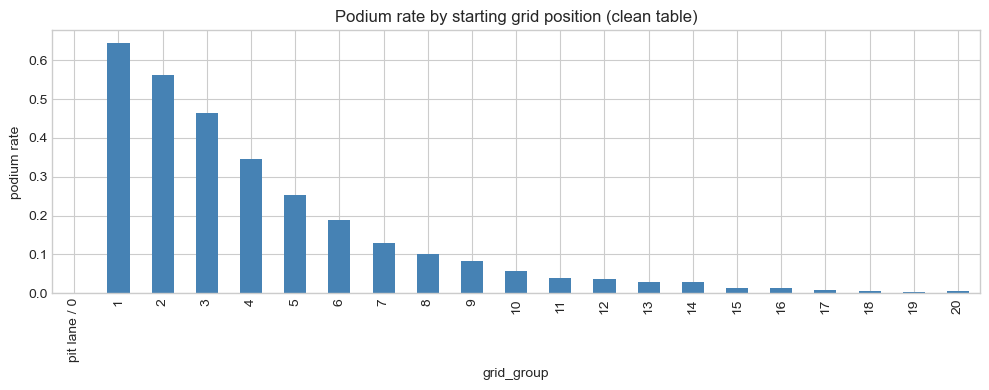

In [26]:
t = table_v1.copy()
t['grid_group'] = np.where(t['grid'] == 0, 'pit lane / 0', t['grid'].clip(upper=20).astype(str))
order = ['pit lane / 0'] + [str(i) for i in range(1, 21)]
rate = t.groupby('grid_group')['podium'].mean().reindex(order)
rate.plot(kind='bar', figsize=(10, 4), color='steelblue')
plt.ylabel('podium rate'); plt.title('Podium rate by starting grid position (clean table)')
plt.tight_layout(); plt.show()

### [Step 1.27] Longitudinal Analysis: Season-by-Season Podium Base Rate Drift
> **Purpose**: Visualizes the longitudinal trend of the positive podium class rate across championship seasons (1950–2024) to evaluate historical grid size dynamics and baseline class drift.
> **Key Operations**:
> * Groups the cleaned analytical table by championship year (`year`) to calculate the seasonal average podium rate.
> * Generates a marked time-series line chart tracking podium rate fluctuations across Formula 1 regulatory eras.
> * Captures historical variations where smaller modern field sizes naturally elevate the baseline podium rate compared to early expanded grids.
---

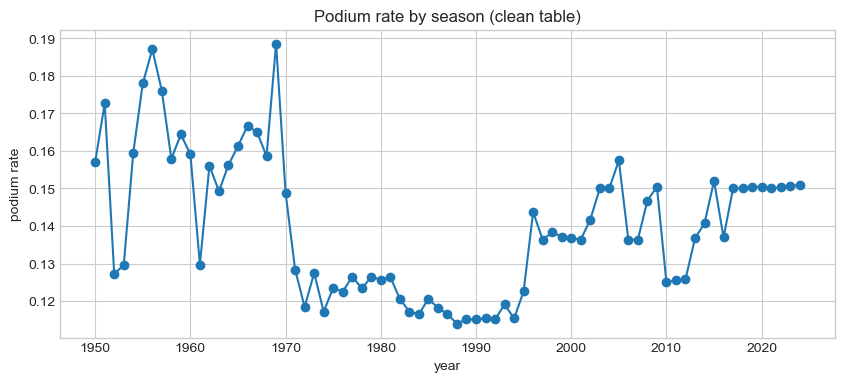

In [27]:
t.groupby('year')['podium'].mean().plot(figsize=(10, 4), marker='o')
plt.ylabel('podium rate'); plt.title('Podium rate by season (clean table)')
plt.show()

### [Step 1.28] Historical Feature Coverage: Longitudinal Qualifying Completeness Audit
> **Purpose**: Measures and plots the season-by-season availability of qualifying positions across `table_v1`, quantifying historical data gaps to define the temporal boundary where qualifying features become viable for modeling.
> **Key Operations**:
> * Aggregates the non-null proportion of `quali_position` grouped by championship season (`year`).
> * Renders a longitudinal line chart tracking qualifying data coverage from the 1950 inaugural season through 2024.
> * Documents the historical transition regimes: complete absence prior to 1994, partial reporting between 1994 and 2002, and near-complete recording from 2003 onward.
---

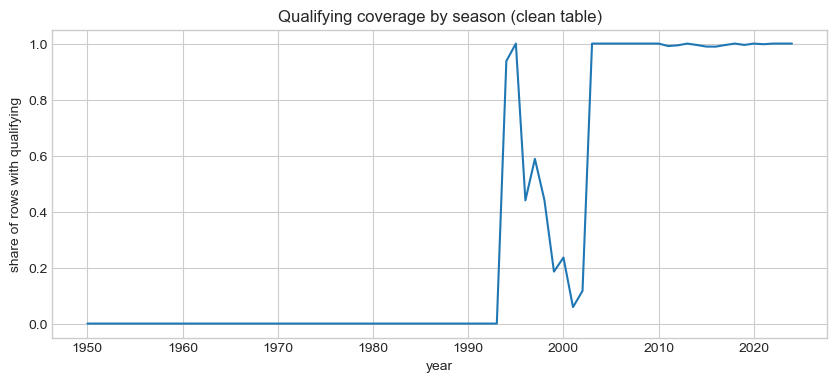

In [28]:
t.groupby('year')['quali_position'].apply(lambda s: s.notna().mean()).plot(figsize=(10, 4))
plt.ylabel('share of rows with qualifying'); plt.title('Qualifying coverage by season (clean table)')
plt.show()

### [Step 1.29] Q1 Setup: Front-Row Feature Engineering & Regulatory Era Segmentation (2003–2024)
> **Purpose**: Prepares the analytical dataset for **Question 1 (A8)** by joining circuit metadata into `table_v1`, restricting the scope to modern seasons with reliable qualifying records (>=2003), segmenting entries across engine eras, and engineering front-row indicators to evaluate circuit-specific podium conversion.
> **Key Operations**:
> * Joins descriptive circuit names from `dfs['circuits']` onto `table_v1` using a validated `m:1` merge, asserting zero row count distortion or unmapped circuit identifiers.
> * Restricts analysis to the 2003–2024 modern era where qualifying data completeness exceeds 99%.
> * Partitions the timeline into two distinct regulatory engine eras: `2003-2013 (pre-hybrid)` vs. `2014-2024 (hybrid)`.
> * Engineers binary indicator flags for front-row grid starts (`grid in [1, 2]`) and front-row qualifying pace (`quali_position in [1, 2]`).
> * Quantifies divergence between qualifying pace and starting grid caused by historical grid penalties, auditing front-row starter integrity per Grand Prix.
---

In [29]:
circ = dfs['circuits'][['circuitId', 'name']].rename(columns={'name': 'circuit'})
q1 = table_v1.merge(circ, on='circuitId', how='left', validate='m:1')
assert len(q1) == len(table_v1) and q1['circuit'].notna().all()

q1 = q1[q1['year'] >= 2003].copy()
PRE, POST = '2003-2013 (pre-hybrid)', '2014-2024 (hybrid)'
q1['era'] = np.where(q1['year'] >= 2014, POST, PRE)
q1['front_grid'] = q1['grid'].isin([1, 2])
q1['front_quali'] = q1['quali_position'].isin([1, 2])

print(q1.groupby('era')[['front_grid', 'front_quali']].sum())
print("Rows where grid-front-row != quali-front-row:", (q1['front_grid'] != q1['front_quali']).sum())
print("Missing quali_position:", q1['quali_position'].isna().sum())
print(q1.groupby('raceId')['front_grid'].sum().value_counts())   # front-row starters per race

                        front_grid  front_quali
era                                            
2003-2013 (pre-hybrid)         398          398
2014-2024 (hybrid)             454          456
Rows where grid-front-row != quali-front-row: 74
Missing quali_position: 23
front_grid
2    425
1      2
0      1
Name: count, dtype: int64


### [Step 1.30] Q1 (A8): Grid Mismatch Root Cause Analysis & Circuit Sample Thresholding
> **Purpose**: Investigates the origin of front-row discrepancies between qualifying position and official starting grid, and evaluates circuit-level sample sizes across both eras to establish a minimum threshold (≥10 starts per era) for reliable ranking.
> **Key Operations**:
> * Computes the number of front-row starters per race to validate starting grid allocations.
> * Audits the 74 instances where front-row grid starts diverge from front-row qualifying pace, confirming all records have complete qualifying data and stem entirely from post-qualifying penalties/grid adjustments.
> * Tabulates front-row start volumes per circuit segmented across the pre-hybrid (2003–2013) and hybrid (2014–2024) regulatory eras.
> * Analyzes circuit frequency distributions, finding 24 of 38 circuits fall below 10 front-row starts in at least one era, justifying a minimum sample threshold of 10 starts per era to eliminate low-sample noise in conversion rankings.
---

In [30]:
n_front = q1.groupby('raceId')['front_grid'].sum()   # front-row starters per race (used by the next cell)

# Where do the 74 mismatches come from?
mm = q1[q1['front_grid'] != q1['front_quali']]
print("Mismatches with quali missing:", mm['quali_position'].isna().sum())
print("Mismatches with both present:", mm['quali_position'].notna().sum())
display(mm[mm['quali_position'].notna()][['year', 'driverId', 'grid', 'quali_position', 'podium']].head(10))

# Sample size per circuit and era (to choose a minimum)
cnt = q1[q1['front_grid']].groupby(['circuit', 'era']).size().unstack(fill_value=0)
print(cnt.describe().round(1))
print((cnt.min(axis=1) < 10).sum(), "of", len(cnt), "circuits have fewer than 10 front-row starts in one era")

Mismatches with quali missing: 0
Mismatches with both present: 74


,year,driverId,grid,quali_position,podium
16179,2004,18,2,3.0,1
16182,2004,23,12,2.0,0
16615,2005,8,12,2.0,1
16621,2005,18,2,3.0,0
16693,2005,4,2,3.0,1
16694,2005,8,11,1.0,0
17410,2007,2,2,3.0,1
17412,2007,4,6,1.0,0
18447,2010,17,7,2.0,0
18449,2010,20,2,3.0,0


era    2003-2013 (pre-hybrid)  2014-2024 (hybrid)
count                    38.0                38.0
mean                     10.5                11.9
std                       8.8                 8.7
min                       0.0                 0.0
25%                       0.0                 4.0
50%                      10.0                11.0
75%                      19.5                19.8
max                      22.0                26.0
24 of 38 circuits have fewer than 10 front-row starts in one era


### [Step 1.31] Q1 (A8): Non-Standard Front-Row Race Exception Audit
> **Purpose**: Audits the specific Grand Prix events that deviate from having exactly two front-row starters (`n_front != 2`), diagnosing historical anomalies such as the 2005 United States Grand Prix and modern pit-lane start penalties.
> **Key Operations**:
> * Identifies and isolates race IDs where the count of front-row starters (`grid in [1, 2]`) does not equal two.
> * Profiles the 2005 United States Grand Prix (`raceId == 79`) using pre-filter results and finish statuses to confirm Michelin-shod runner withdrawals after the formation lap.
> * Inspects anomalous modern events (`raceId` 983 and 1118) where drivers qualified at the sharp end but started from the pit lane (`grid == 0`) due to post-qualifying technical infringements or engine component changes.
---

In [31]:
print(n_front[n_front != 2])     # the races without exactly 2 front-row starters

pre = results_pre_filter.merge(dfs['status'], on='statusId')
print(pre[pre['raceId'] == 79]['status'].value_counts())      # 2005 US GP: who was removed

display(q1[q1['raceId'].isin([983, 1118]) & (q1['grid'] == 0)]
          [['raceId', 'year', 'driverId', 'grid', 'quali_position', 'podium']])

raceId
79      0
983     1
1118    1
Name: front_grid, dtype: int64
status
Withdrew    14
Finished     2
+2 Laps      2
+1 Lap       2
Name: count, dtype: int64


,raceId,year,driverId,grid,quali_position,podium
21596,983,2017,8,0,2.0,0
24161,1118,2023,844,0,2.0,0


**Three races lack a grid-2 starter. In the 2005 US GP, 14 drivers withdrew before the start and were removed as non-starters, leaving 6 cars with no front-row starter. In Malaysia 2017 and São Paulo 2023, the driver who qualified 2nd is recorded as grid = 0 after a car failure, so he counts as front row by qualifying but not by grid.**

### [Step 1.32] Q1 (A8): Statistical Estimation & Circuit Era Comparison (Wilson CI & Rank Shifts)
> **Purpose**: Evaluates circuit-level front-row podium conversion rates across the pre-hybrid (2003–2013) and hybrid (2014–2024) eras, applying Wilson score confidence intervals and computing relative rank shifts for filtered circuits (≥10 starts per era).
> **Key Operations**:
> * Implements a Wilson score interval calculation (`wilson`) to provide reliable binomial proportion confidence bounds for small-to-moderate sample sizes.
> * Aggregates starts and podium conversions by circuit and era, filtering to the stable cohort meeting the minimum threshold of 10 front-row starts in both eras.
> * Computes era-specific conversion rates, lower/upper 95% Wilson confidence limits, and ordinal circuit conversion ranks.
> * Measures era-to-era relative rank progression (`rank_change = rank_pre - rank_post`) to pinpoint circuits where front-row advantage strengthened or degraded.
> * Executes the comparison workflow separately for official starting grid front runners (`front_grid`) and qualifying front runners (`front_quali`) to assess the consistency of circuit rankings against post-qualifying penalties.
---

In [32]:
from scipy.stats import fisher_exact, spearmanr

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return c - h, c + h

def compare(flag, min_starts=10):
    g = q1[q1[flag]].groupby(['circuit', 'era'])['podium'].agg(['size', 'sum']).unstack('era')
    out = pd.DataFrame({'n_pre': g[('size', PRE)], 'k_pre': g[('sum', PRE)],
                        'n_post': g[('size', POST)], 'k_post': g[('sum', POST)]})
    out = out[(out['n_pre'] >= min_starts) & (out['n_post'] >= min_starts)].copy()
    for e in ['pre', 'post']:
        out[f'rate_{e}'] = out[f'k_{e}'] / out[f'n_{e}']
        out[f'lo_{e}'], out[f'hi_{e}'] = wilson(out[f'k_{e}'], out[f'n_{e}'])
        out[f'rank_{e}'] = out[f'rate_{e}'].rank(ascending=False, method='min')
    out['rank_change'] = out['rank_pre'] - out['rank_post']      # positive = moved up
    return out.sort_values('rate_post', ascending=False)

grid_cmp, quali_cmp = compare('front_grid'), compare('front_quali')
cols = ['n_pre', 'rate_pre', 'lo_pre', 'hi_pre', 'n_post', 'rate_post', 'lo_post', 'hi_post',
        'rank_pre', 'rank_post', 'rank_change']
print("GRID: circuits compared =", len(grid_cmp));       display(grid_cmp[cols].round(2))
print("QUALIFYING: circuits compared =", len(quali_cmp)); display(quali_cmp[cols].round(2))

GRID: circuits compared = 14


,n_pre,rate_pre,lo_pre,hi_pre,n_post,rate_post,lo_post,hi_post,rank_pre,rank_post,rank_change
circuit,,,,,,,,,,,
Suzuka Circuit,18.0,0.72,0.49,0.88,18.0,0.89,0.67,0.97,4.0,1.0,3.0
Yas Marina Circuit,10.0,0.60,0.31,0.83,22.0,0.86,0.67,0.95,10.0,2.0,8.0
Circuit de Monaco,22.0,0.77,0.57,0.90,20.0,0.85,0.64,0.95,1.0,3.0,-2.0
Circuit de Spa-Francorchamps,18.0,0.72,0.49,0.88,22.0,0.82,0.61,0.93,4.0,4.0,0.0
Circuit de Barcelona-Catalunya,22.0,0.68,0.47,0.84,22.0,0.82,0.61,0.93,6.0,4.0,2.0
Autódromo José Carlos Pace,22.0,0.59,0.39,0.77,19.0,0.79,0.57,0.91,12.0,6.0,6.0
Shanghai International Circuit,20.0,0.65,0.43,0.82,14.0,0.79,0.52,0.92,8.0,7.0,1.0
Circuit Gilles Villeneuve,20.0,0.60,0.39,0.78,18.0,0.78,0.55,0.91,10.0,8.0,2.0
Silverstone Circuit,22.0,0.73,0.52,0.87,24.0,0.75,0.55,0.88,3.0,9.0,-6.0


QUALIFYING: circuits compared = 14


,n_pre,rate_pre,lo_pre,hi_pre,n_post,rate_post,lo_post,hi_post,rank_pre,rank_post,rank_change
circuit,,,,,,,,,,,
Suzuka Circuit,18.0,0.72,0.49,0.88,18.0,0.89,0.67,0.97,3.0,1.0,2.0
Circuit de Monaco,22.0,0.68,0.47,0.84,20.0,0.85,0.64,0.95,6.0,2.0,4.0
Circuit de Spa-Francorchamps,18.0,0.72,0.49,0.88,22.0,0.82,0.61,0.93,3.0,3.0,0.0
Yas Marina Circuit,10.0,0.60,0.31,0.83,22.0,0.82,0.61,0.93,9.0,3.0,6.0
Circuit de Barcelona-Catalunya,22.0,0.64,0.43,0.80,22.0,0.82,0.61,0.93,8.0,3.0,5.0
Shanghai International Circuit,20.0,0.70,0.48,0.85,14.0,0.79,0.52,0.92,5.0,6.0,-1.0
Silverstone Circuit,22.0,0.77,0.57,0.90,24.0,0.75,0.55,0.88,1.0,7.0,-6.0
Autodromo Nazionale di Monza,22.0,0.73,0.52,0.87,22.0,0.73,0.52,0.87,2.0,8.0,-6.0
Circuit Gilles Villeneuve,20.0,0.60,0.39,0.78,18.0,0.72,0.49,0.88,9.0,9.0,0.0


### [Step 1.33] Q1 (A8): Pooled Era Testing & Cross-Era Rank Correlation (Fisher's Exact & Spearman's Rho)
> **Purpose**: Performs formal hypothesis testing on pooled front-row conversion rates across eras using Fisher's Exact Test and measures the cross-era stability of circuit rankings using Spearman's rank correlation coefficient.
> **Key Operations**:
> * Defines a pooled aggregation routine (`pooled`) that isolates eligible circuits, constructs 2x2 contingency tables (podium vs. non-podium by regulatory era), and runs Fisher's Exact Test to determine if the macro shift in conversion rate is statistically significant.
> * Computes Spearman's rank correlation coefficient ($\rho$) and associated p-values between pre-hybrid and hybrid conversion rates to assess whether circuit conversion hierarchies remained stable over time.
> * Evaluates metrics independently across both starting grid (`front_grid`) and qualifying (`front_quali`) definitions to verify that findings are robust to post-qualifying penalties.
> * Summarizes pooled conversion rates, Fisher exact p-values, rank correlation coefficients, and significance levels into an evaluation-ready audit table.
---

In [33]:
def pooled(flag, circuits):
    f = q1[q1[flag] & q1['circuit'].isin(circuits)]
    t = f.groupby('era')['podium'].agg(['sum', 'size']).reindex([PRE, POST])
    _, p = fisher_exact([[t.loc[PRE, 'sum'], t.loc[PRE, 'size'] - t.loc[PRE, 'sum']],
                         [t.loc[POST, 'sum'], t.loc[POST, 'size'] - t.loc[POST, 'sum']]])
    return t.loc[PRE, 'sum'] / t.loc[PRE, 'size'], t.loc[POST, 'sum'] / t.loc[POST, 'size'], p

rows = []
for name, flag, c in [('grid', 'front_grid', grid_cmp), ('qualifying', 'front_quali', quali_cmp)]:
    r_pre, r_post, p_f = pooled(flag, c.index)
    rho, p_rho = spearmanr(c['rate_pre'], c['rate_post'])
    rows.append({'definition': name, 'circuits': len(c), 'pooled 2003-13': round(r_pre, 3),
                 'pooled 2014-24': round(r_post, 3), 'Fisher p': round(p_f, 3),
                 'rank corr': round(rho, 2), 'rank corr p': round(p_rho, 3)})
display(pd.DataFrame(rows))

,definition,circuits,pooled 2003-13,pooled 2014-24,Fisher p,rank corr,rank corr p
0,grid,14,0.670,0.767,0.014,0.30,0.292
1,qualifying,14,0.659,0.750,0.020,0.57,0.033


### [Step 1.34] Q1 (A8): Sensitivity Analysis Across Minimum Sample Thresholds
> **Purpose**: Validates the stability of circuit rankings and cross-era rank correlations against varying minimum front-row start thresholds ($m \in [5, 8, 10, 15]$), confirming that conclusions regarding post-2014 circuit hierarchies and rank stability are not artifacts of an arbitrary sample cutoff.
> **Key Operations**:
> * Iterates across varying sample volume thresholds ($m = 5, 8, 10, 15$) for both starting grid (`front_grid`) and qualifying (`front_quali`) definitions using the `compare` workflow.
> * Evaluates circuit cohort sizes, top 3 ranked circuits in the modern hybrid era (post-2014), and Spearman rank correlation coefficients ($\rho$) with their associated p-values at each threshold level.
> * Configures display formatting to inspect high-conversion circuit names across multiple sample sizes.
> * Tabulates sensitivity metrics into an audit summary to confirm whether circuit conversion hierarchies and cross-era rank drift remain robust across parameter choices.
---

In [34]:
rows = []
for m in [5, 8, 10, 15]:
    for name, flag in [('grid', 'front_grid'), ('qualifying', 'front_quali')]:
        d = compare(flag, min_starts=m)
        rho, p = spearmanr(d['rate_pre'], d['rate_post'])
        rows.append({'min starts': m, 'definition': name, 'circuits': len(d),
                     'top 3 after 2014': ', '.join(d.index[:3]), 'rank corr': round(rho, 2), 'p': round(p, 2)})
pd.set_option('display.max_colwidth', 120)
display(pd.DataFrame(rows))

,min starts,definition,circuits,top 3 after 2014,rank corr,p
0,5,grid,17,"Suzuka Circuit, Yas Marina Circuit, Sepang International Circuit",0.16,0.53
1,5,qualifying,17,"Suzuka Circuit, Circuit de Monaco, Yas Marina Circuit",0.45,0.07
2,8,grid,16,"Suzuka Circuit, Yas Marina Circuit, Circuit de Monaco",0.21,0.43
3,8,qualifying,17,"Suzuka Circuit, Circuit de Monaco, Yas Marina Circuit",0.45,0.07
4,10,grid,14,"Suzuka Circuit, Yas Marina Circuit, Circuit de Monaco",0.30,0.29
5,10,qualifying,14,"Suzuka Circuit, Circuit de Monaco, Circuit de Spa-Francorchamps",0.57,0.03
6,15,grid,11,"Suzuka Circuit, Circuit de Monaco, Circuit de Spa-Francorchamps",0.37,0.26
7,15,qualifying,11,"Suzuka Circuit, Circuit de Monaco, Circuit de Spa-Francorchamps",0.65,0.03


### [Step 1.35] Q1 (A8): Circuit Podium Conversion Visualizer (Caterpillar Plot with 95% Wilson CIs)
> **Purpose**: Generates comparative horizontal error-bar ("caterpillar") plots depicting front-row podium conversion rates alongside 95% Wilson confidence intervals across circuits, contrasting the pre-hybrid (2003–2013) and hybrid (2014–2024) regulatory eras.
> **Key Operations**:
> * Implements a reusable visualization routine (`plot_ci`) that orders circuits ascending by modern hybrid conversion rate (`rate_post`) along the vertical axis.
> * Applies vertical coordinate offsets ($\pm 0.15$) to prevent visual overlap between pre-hybrid and hybrid era estimates on identical circuit baselines.
> * Plots point estimates and asymmetric error bars derived from Wilson score interval bounds (`lo_pre`, `hi_pre`, `lo_post`, `hi_post`) for each venue.
> * Renders distinct diagnostic figures for starting grid allocations (`front_grid`) and raw qualifying results (`front_quali`) to facilitate direct visual evaluation of circuit conversion stability and uncertainty.
---

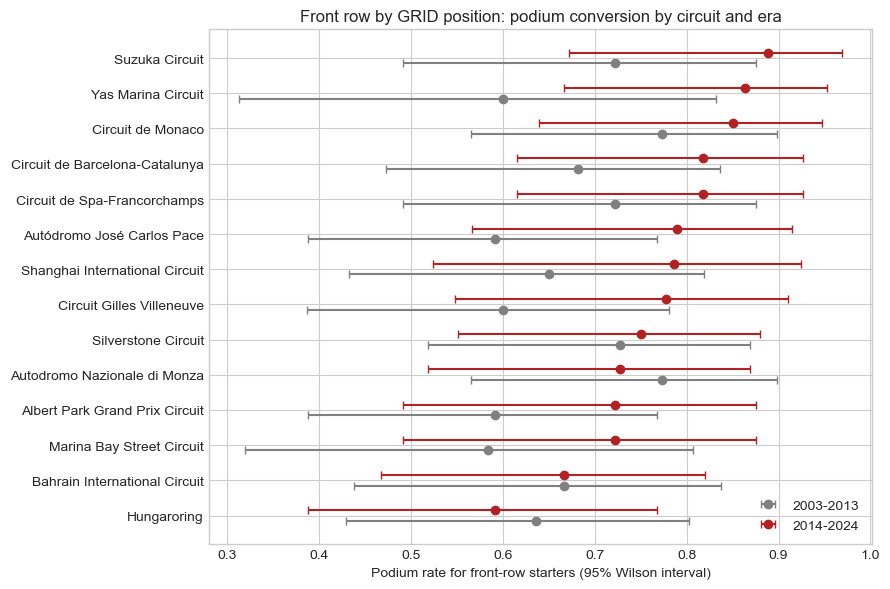

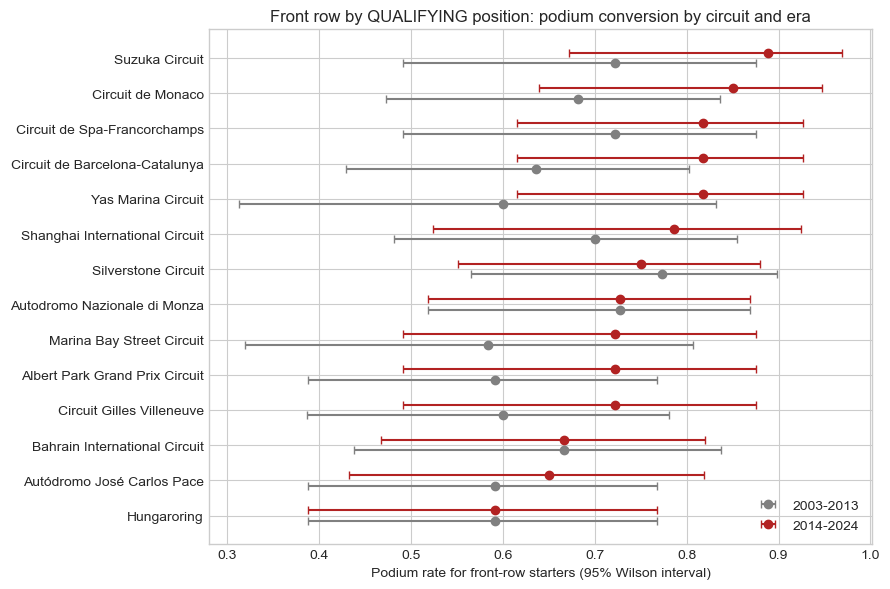

In [35]:
def plot_ci(cmp_, title):
    d = cmp_.sort_values('rate_post')
    y = np.arange(len(d))
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.errorbar(d['rate_pre'], y - 0.15, xerr=[d['rate_pre'] - d['lo_pre'], d['hi_pre'] - d['rate_pre']],
                fmt='o', color='gray', capsize=3, label='2003-2013')
    ax.errorbar(d['rate_post'], y + 0.15, xerr=[d['rate_post'] - d['lo_post'], d['hi_post'] - d['rate_post']],
                fmt='o', color='firebrick', capsize=3, label='2014-2024')
    ax.set_yticks(y); ax.set_yticklabels(d.index)
    ax.set_xlabel('Podium rate for front-row starters (95% Wilson interval)')
    ax.set_title(title); ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

plot_ci(grid_cmp, 'Front row by GRID position: podium conversion by circuit and era')
plot_ci(quali_cmp, 'Front row by QUALIFYING position: podium conversion by circuit and era')

---
## Section 2: Feature Engineering & Modeling Pipeline
> **Overview**: Constructs the final analytical base table from `table_v1`, engineers all pre-race features in a strict leakage-safe manner, splits the data chronologically, and trains & evaluates multiple classifiers. Every feature value is derived exclusively from information available **before the race starts**.
---

**The code needs table_v1 and three other tables. This cell confirms they exist and have the right columns before we build on them.**

### [Step 2.0] Pre-Modeling Schema Validation & Dependency Check
> **Purpose**: Verifies that `table_v1` contains every column required for feature engineering and confirms the three auxiliary tables (`races`, `driver_standings`, `constructor_standings`) are present with their expected schemas before any modeling code executes.
> **Key Operations**:
> * Lists any column from the required set of 14 fields (identifiers, grid, qualifying, target, calendar, sector times) that is missing from `table_v1`.
> * Prints the shape and column names of `races`, `driver_standings`, and `constructor_standings` to confirm all prerequisite tables are loaded and complete.
---

In [36]:
need = ['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'podium', 'year', 'round',
        'circuitId', 'date', 'quali_position', 'q1_sec', 'q2_sec', 'q3_sec']
print("table_v1 missing columns:", [c for c in need if c not in table_v1.columns])   # expect []

for t in ['races', 'driver_standings', 'constructor_standings']:
    print(t, dfs[t].shape, list(dfs[t].columns))

table_v1 missing columns: []
races (1125, 18) ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']
driver_standings (34863, 7) ['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']
constructor_standings (13391, 7) ['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']


**SEED = 42: makes random steps (like the random forest) give the same answer every run, which Run All needs.
TRAIN_END, VAL_END: the split. Seasons up to 2019 train the model, 2020-2021 tune it, 2022 onward test it. Time order matters because you can’t use future races to predict past ones.
TRAIN_START: a switch we’ll use later as an experiment, because qualifying data is only complete from 2003.**

### [Step 2.1] Library Imports & Global Modeling Constants
> **Purpose**: Loads all third-party libraries required for the modeling pipeline and declares the three global temporal split constants that enforce a strict chronological boundary between training, validation, and test sets throughout every subsequent step.
> **Key Operations**:
> * Imports `numpy`, `pandas`, `matplotlib`, `seaborn`, and all required `scikit-learn` modules (imputer, scaler, classifiers, and evaluation metrics).
> * Sets `SEED = 42` to make every random operation (forest splits, shuffles, etc.) deterministic and reproducible across notebook re-runs.
> * Declares `TRAIN_END = 2019` and `VAL_END = 2021` as temporal boundaries: seasons up to 2019 train the model, 2020–2021 are used for tuning and threshold selection, and 2022 onward form the unseen final test set.
> * Sets `TRAIN_START = 1950` as a configurable lower bound used later in qualifying-era sensitivity experiments.
---

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)

SEED = 42
TRAIN_END, VAL_END = 2019, 2021
TRAIN_START = 1950   

The comments are the leakage audit the brief asks for. Allowed means known before the race. Forbidden means only known after it.
base = table_v1.copy(): we start from your clean table, so the whole team uses the same one.
Sorting by date: needed because the “form” features look at past races, so races must be in true time order.
target_podium: the 0/1 answer we predict, built from positionOrder.
The three asserts stop the notebook if the target doesn’t match podium, if a driver appears twice in a race, or if a date is missing.**ALLOWED (known after qualifying, before lights-out):
   grid, qualifying position/times, and history from races BEFORE this one.
 FORBIDDEN (only known after the race): positionOrder, statusId, points, laps, race time,
   fastest lap, pit stops, lap times, and championship standings AFTER this race.
 positionOrder / statusId stay in `base` only to build the target and past-race history.
 They are never used as features (a guard in a later cell enforces this).
 Sprint decision: sprint results are NOT used. They exist only from 2021 (360 rows), so the
   feature would be empty for almost every training row.**

### [Step 2.2] Analytical Base Table Initialisation & Target Label Construction
> **Purpose**: Initialises the working analytical base table from the cleaned `table_v1`, enforces strict chronological row ordering, constructs the binary prediction target `target_podium`, and runs three formal sanity assertions to guarantee data integrity before any feature engineering begins.
> **Key Operations**:
> * Deep-copies `table_v1` into `base` and parses the `date` column to a native `datetime64` type.
> * Sorts all rows by `(date, round, raceId, driverId)` to establish the leakage-safe temporal ordering required for all rolling and cumulative feature computations.
> * Constructs the binary classification target: `target_podium = 1` if `positionOrder <= 3`, else `0`, and asserts it is identical to the pre-existing `podium` column for consistency.
> * Asserts zero duplicate `(raceId, driverId)` pairs (grain integrity) and zero missing race dates (calendar completeness) before proceeding.
> * Reports the total row count and overall podium class rate as a sanity baseline.
---

In [38]:
base = table_v1.copy()
base["date"] = pd.to_datetime(base["date"])
base = base.sort_values(["date", "round", "raceId", "driverId"]).reset_index(drop=True)
base["target_podium"] = (base["positionOrder"] <= 3).astype(int)

assert (base["target_podium"] == base["podium"]).all()
assert not base.duplicated(["raceId", "driverId"]).any()
assert base["date"].notna().all()
print(f"base table: {base.shape[0]} rows | podium rate {base['target_podium'].mean():.2%}")

base table: 24686 rows | podium rate 13.61%


### [Step 2.2b] Base Table Integrity Audit: Row Count, Date Range & Qualifying Coverage
> **Purpose**: Runs additional sanity checks on the base table immediately after it is sorted and the target is constructed, verifying row count, year span, grain uniqueness, target formula consistency, and qualifying missingness patterns by decade.
> **Key Operations**:
> * Prints total row count and the min/max `year` present in `base` to confirm the full historical range (1950–2024) is intact.
> * Asserts `target_podium` matches the raw `positionOrder <= 3` rule for every row.
> * Asserts zero duplicate `(raceId, driverId)` pairs to confirm grain integrity.
> * Prints min, max, and missing-rate statistics for `q1_sec`, `q2_sec`, and `q3_sec` sector times to profile qualifying data availability.
> * Aggregates the fraction of rows with missing `q1_sec` per decade to document the historical qualifying data coverage boundary (≈ pre-2003 gap).
---

In [39]:
print("rows:", len(base), "| years:", base["year"].min(), "-", base["year"].max())
assert not base.duplicated(["raceId", "driverId"]).any()
print("target vs raw rule:", bool((base["target_podium"] == (base["positionOrder"] <= 3).astype(int)).all()))
for c in ["q1_sec", "q2_sec", "q3_sec"]:
    if c in base: print(f"{c}: min {base[c].min():.1f} max {base[c].max():.1f} missing {base[c].isna().mean():.1%}")
print("missing qualifying by decade:\n",
      base.assign(decade=(base['year'] // 10) * 10).groupby("decade")["q1_sec"].apply(lambda s: s.isna().mean()).round(3).to_string())

rows: 24686 | years: 1950 - 2024
target vs raw rule: True
q1_sec: min 53.9 max 153.9 missing 58.3%
q2_sec: min 53.6 max 132.5 missing 76.4%
q3_sec: min 53.4 max 129.8 missing 85.3%
missing qualifying by decade:
 decade
1950    1.000
1960    1.000
1970    1.000
1980    1.000
1990    0.651
2000    0.280
2010    0.015
2020    0.010


### [Step 2.2c] Final Base Table Row-Count Assertion & Qualifying Missingness Summary
> **Purpose**: Performs a hard assertion that the base table contains exactly the expected number of rows after all cleaning and filtering steps, and produces a concise decade-level summary of qualifying data availability for the report.
> **Key Operations**:
> * Asserts `len(base) == 24686`: any deviation indicates a cleaning or merge error in earlier pipeline steps and halts the notebook immediately.
> * Prints the overall podium rate (expected ≈ 0.1361) as a final class distribution check.
> * Aggregates `q1_sec` missingness fraction by decade to show the stepwise improvement in qualifying coverage from completely absent (1950s–1990s) to near-complete (2003+).
---

In [40]:
assert len(base) == 24686, len(base)          # no rows lost or duplicated by the merges
print("podium rate:", round(base["target_podium"].mean(), 4))   # expect 0.1361
print("missing qualifying by decade:\n",
      base.assign(decade=(base["year"] // 10) * 10)
          .groupby("decade")["q1_sec"].apply(lambda s: s.isna().mean()).round(3).to_string())

podium rate: 0.1361
missing qualifying by decade:
 decade
1950    1.000
1960    1.000
1970    1.000
1980    1.000
1990    0.651
2000    0.280
2010    0.015
2020    0.010



**field_size: how many cars started the race. It is known before the race and affects the podium chance (3 podiums among more cars means a lower rate).pit_lane_start and grid_clean: a driver starting from the pit lane has grid = 0 in the data, which would look like pole position to a model. We recode them to start last and keep a flag that says they did.quali_missing: qualifying data is missing for most seasons before 2003. We keep a flag so the model knows when qualifying position is a stand-in (grid) and not the real value.qual_gap_to_pole: how much slower a driver’s best qualifying lap was than the pole lap. A 55 s lap at one track and a 100 s lap at another aren’t comparable, but a percentage gap is.**


### [Step 2.3] Pre-Race Feature Engineering: Grid Correction, Qualifying Coverage & Pace Gap
> **Purpose**: Engineers four pre-race features that encode starting-position information while correctly handling pit-lane start anomalies, missing qualifying data, and circuit-length differences — all derived from information legally available before the race starts.
> **Key Operations**:
> * **`field_size`**: number of cars that started each race (groupby `raceId` size), which acts as the denominator for the 3-podium rate and reflects field competitiveness.
> * **`pit_lane_start`** (binary): flags drivers with official grid = 0; without this flag they would appear numerically as if starting from pole position.
> * **`grid_clean`**: recodes pit-lane starters to grid position `max_grid + 1` so the model sees a monotonically ordered grid with no misleading zeros.
> * **`quali_missing`** (binary): flags rows where `quali_position` is null (pre-2003 eras and occasional gaps), allowing the model to distinguish genuine qualifying data from filled stand-ins.
> * Fills missing `quali_position` with `grid_clean` as a documented, labelled fallback for qualifying-absent seasons.
> * **`qual_gap_to_pole`**: each driver's fastest Q-sector time relative to the pole-sitter's time in the same race (fractional gap), normalising pace across circuits of different lengths.
---

In [41]:
# Grid: pit-lane starters (grid == 0) start LAST, so recode them instead of letting 0 look like pole
race = base.groupby("raceId")
base["field_size"] = race["driverId"].transform("size")
base["pit_lane_start"] = (base["grid"] == 0).astype(int)
base["grid_clean"] = np.where(base["grid"] == 0, race["grid"].transform("max") + 1, base["grid"])

# Qualifying: keep a flag for "no qualifying data", and fall back to grid only as a labelled stand-in
base["quali_missing"] = base["quali_position"].isna().astype(int)
base["quali_position"] = base["quali_position"].fillna(base["grid_clean"])

# Gap to pole = how much slower than the fastest qualifier of the SAME race (comparable across circuits)
best_lap = base[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
pole_lap = best_lap.groupby(base["raceId"]).transform("min")
base["qual_gap_to_pole"] = best_lap / pole_lap - 1

# Checks
print("pit-lane starters:", base["pit_lane_start"].sum(),
      "| their podium rate:", round(base.loc[base["pit_lane_start"] == 1, "target_podium"].mean(), 3))
print("share of rows with no qualifying data:", round(base["quali_missing"].mean(), 3))
print("field size min/max:", base["field_size"].min(), base["field_size"].max())
print(base["qual_gap_to_pole"].describe().round(4))

pit-lane starters: 130 | their podium rate: 0.0
share of rows with no qualifying data: 0.576
field size min/max: 6 34
count    10298.0000
mean         0.0240
std          0.0256
min          0.0000
25%          0.0090
50%          0.0184
75%          0.0307
max          0.4560
Name: qual_gap_to_pole, dtype: float64


**About 130 pit-lane starters, with a podium rate close to 0 (it may not be exactly 0).
A large share of rows with no qualifying data (quali_missing is high, because the data is missing before 2003).
qual_gap_to_pole has a minimum of 0 (the pole sitter). The median should be a small positive number, likely between 0.01 and 0.02.**

### [Step 2.4] Championship Standings Feature Engineering (Leakage-Safe Temporal Join)
> **Purpose**: Joins each driver's and constructor's pre-race championship standing points and positions onto the base table using only the standings recorded **after the previous round**, so that the current race's own result never contaminates its own features.
> **Key Operations**:
> * Builds a per-season `prev_raceId` lookup by shifting each season's race list back one round (`shift(1)`), ensuring standings used for race R always reflect what was published after race R-1.
> * Asserts `prev_date` is never later than `date` to formally verify temporal ordering across all season rows.
> * Merges `driver_champ_points` and `driver_champ_pos` from `driver_standings`, keyed on `prev_raceId`, with `validate='m:1'` to catch unexpected row explosions.
> * Merges `constructor_champ_points` and `constructor_champ_pos` from `constructor_standings` using the same approach.
> * Adds `driver_standing_missing` and `constructor_standing_missing` binary flags to distinguish new season-opener rows (no prior standing) from rows with known standings.
> * Fills missing standings with 0 points and position 30 (sentinel for 'unranked') for new entrants and round-1 races.
---

In [42]:
def add_standings_features(df, races, d_stand, c_stand):
    r = races[["raceId", "year", "round", "date"]].copy()
    r["date"] = pd.to_datetime(r["date"])
    r = r.sort_values(["year", "round"])
    r["prev_raceId"] = r.groupby("year")["raceId"].shift(1)
    r["prev_date"] = r.groupby("year")["date"].shift(1)
    assert (r["prev_date"] > r["date"]).sum() == 0, "previous race must not be later than this race"

    df = df.merge(r[["raceId", "prev_raceId"]], on="raceId", how="left", validate="m:1")
    df["prev_raceId"] = df["prev_raceId"].astype("float64")

    ds = d_stand[["raceId", "driverId", "points", "position"]].rename(
        columns={"raceId": "prev_raceId", "points": "driver_champ_points", "position": "driver_champ_pos"})
    ds["prev_raceId"] = ds["prev_raceId"].astype("float64")
    ds = ds.drop_duplicates(["prev_raceId", "driverId"], keep="last")

    cs = c_stand[["raceId", "constructorId", "points", "position"]].rename(
        columns={"raceId": "prev_raceId", "points": "constructor_champ_points", "position": "constructor_champ_pos"})
    cs["prev_raceId"] = cs["prev_raceId"].astype("float64")
    cs = cs.drop_duplicates(["prev_raceId", "constructorId"], keep="last")

    df = df.merge(ds, on=["prev_raceId", "driverId"], how="left", validate="m:1")
    df = df.merge(cs, on=["prev_raceId", "constructorId"], how="left", validate="m:1")
    df["driver_standing_missing"] = df["driver_champ_points"].isna().astype(int)
    df["constructor_standing_missing"] = df["constructor_champ_points"].isna().astype(int)
    # Round 1 (or a new entrant): no standing yet -> 0 points, and a position worse than everyone (30)
    df[["driver_champ_points", "constructor_champ_points"]] = df[
        ["driver_champ_points", "constructor_champ_points"]].fillna(0)
    df[["driver_champ_pos", "constructor_champ_pos"]] = df[
        ["driver_champ_pos", "constructor_champ_pos"]].fillna(30)
    return df.drop(columns="prev_raceId")


n_before = len(base)
base = add_standings_features(base, dfs["races"], dfs["driver_standings"], dfs["constructor_standings"])
assert len(base) == n_before, "standings merge changed the number of rows"

### [Step 2.5] Championship Standings Leakage Verification
> **Purpose**: Numerically validates that standings joined onto each race exactly match the official standings published after the preceding round, providing a concrete proof-of-correctness for the temporal join before any model training.
> **Key Operations**:
> * Selects 2019 Round 5 as the probe race and Round 4 as the expected source of standings.
> * Compares `driver_champ_points` in `base` for all Round 5 rows against the raw `driver_standings` entries for the Round 4 `raceId`, asserting exact equality across all common drivers.
> * Verifies that all Round 1 rows carry zero pre-race championship points, confirming the season-opener fill rule is applied correctly and no standings leak from the previous season.
---

In [43]:
rc = dfs["races"]
rid = base.loc[(base["year"] == 2019) & (base["round"] == 5), "raceId"].iloc[0]
prev = rc.loc[(rc["year"] == 2019) & (rc["round"] == 4), "raceId"].iloc[0]
a = base[base["raceId"] == rid].set_index("driverId")["driver_champ_points"]
b = dfs["driver_standings"][dfs["driver_standings"]["raceId"] == prev].set_index("driverId")["points"]
common = a.index.intersection(b.index)
print("drivers compared:", len(common))
print("round 5 pre-race points == standings after round 4:", bool((a.loc[common] == b.loc[common]).all()))
print("round 1 pre-race points (should be only 0):", base.loc[base["round"] == 1, "driver_champ_points"].unique())

drivers compared: 20
round 5 pre-race points == standings after round 4: True
round 1 pre-race points (should be only 0): [0.]


**What “form” means: how a driver and a team have been doing recently. A driver on a winning streak is more likely to podium.
The key rule: every form value must come only from races before this one. shift(1) moves the value down by one race, so a race never sees its own result.
Driver features: driver_top10_last3 (top-10 finishes in the last 3 races), driver_podiums_last3, driver_career_podiums and driver_career_starts (everything before this race).
The constructor trap: a team has two cars per race. If we shifted by row, the team’s second car would see the first car’s result from the same race, which is leakage. So we first collapse to one row per team per race, then shift by race.
First races: a driver’s first race has no history, so the form is 0.**

### [Step 2.6] Rolling Form Feature Engineering (Driver & Constructor Recent History)
> **Purpose**: Engineers five features capturing the recent and career performance trajectory of each driver and constructor using rolling window aggregations, where every value strictly uses only races that occurred **before** the current race to prevent any look-ahead leakage.
> **Key Operations**:
> * Sorts rows by `(date, round, raceId, driverId)` before all rolling computations to guarantee the correct temporal ordering.
> * **`driver_top10_last3`**: count of top-10 finishes across the driver's last 3 races (`shift(1)` + `rolling(3, min_periods=1).sum()`).
> * **`driver_podiums_last3`**: count of podium finishes across the driver's last 3 races (same shifting approach).
> * **`driver_career_podiums`**: cumulative podium count up to but not including the current race (`shift(1).cumsum()`).
> * **`driver_career_starts`**: total race starts accumulated prior to this race (`cumcount()`).
> * **`constructor_podiums_last5`**: podiums scored by the constructor across both cars in the last 5 races. To prevent teammate leakage (car 2 seeing car 1's result from the same race), the code first collapses to one team-race row, applies the rolling shift, then merges back to the per-driver table.
> * Fills all form columns with 0 for any driver or constructor's first-ever race entry.
---

In [44]:
FORM_COLS = ["driver_top10_last3", "driver_podiums_last3", "driver_career_podiums",
             "driver_career_starts", "constructor_podiums_last5"]


def add_form_features(df):
    """Every value uses ONLY races that happened before the current one."""
    df = df.sort_values(["date", "round", "raceId", "driverId"]).reset_index(drop=True)
    df["top10"] = (df["positionOrder"] <= 10).astype(int)

    # One row per driver per race, so shift(1) really means "previous race of this driver"
    d = df.groupby("driverId")
    df["driver_top10_last3"] = d["top10"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum())
    df["driver_podiums_last3"] = d["target_podium"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum())
    df["driver_career_podiums"] = d["target_podium"].transform(lambda s: s.shift(1).cumsum())
    df["driver_career_starts"] = d.cumcount()

    # A team has two cars per race, so first collapse to ONE row per team per race, THEN shift by race.
    # (Shifting by row would let car #2 see car #1's result from the same race = leakage.)
    cr = (df.groupby(["constructorId", "raceId", "date", "round"], as_index=False)
            .agg(c_podiums=("target_podium", "sum"))
            .sort_values(["constructorId", "date", "round"]))
    cr["constructor_podiums_last5"] = cr.groupby("constructorId")["c_podiums"].transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum())
    df = df.drop(columns=["constructor_podiums_last5"], errors="ignore").merge(
        cr[["constructorId", "raceId", "constructor_podiums_last5"]],
        on=["constructorId", "raceId"], how="left", validate="m:1")

    df[FORM_COLS] = df[FORM_COLS].fillna(0)   # first ever race = no history = 0
    return df.drop(columns="top10")


base = add_form_features(base)
print(base[FORM_COLS].describe().round(2).T[["min", "mean", "max"]])

# Check by hand: recompute one driver's form with a different method and compare
top = base["driverId"].value_counts().index[0]            # the driver with the most races
d1 = base[base["driverId"] == top].sort_values(["date", "round"]).reset_index(drop=True)
manual = d1["target_podium"].shift(1).rolling(3, min_periods=1).sum().fillna(0)
print("matches manual recompute for the driver with the most races:", bool((manual == d1["driver_podiums_last3"]).all()))
display(d1.loc[100:107, ["year", "round", "positionOrder", "target_podium", "driver_podiums_last3", "driver_career_podiums"]])

                           min   mean    max
driver_top10_last3         0.0   1.32    3.0
driver_podiums_last3       0.0   0.40    3.0
driver_career_podiums      0.0  13.32  202.0
driver_career_starts       0.0  68.09  401.0
constructor_podiums_last5  0.0   1.55   13.0
matches manual recompute for the driver with the most races: True


,year,round,positionOrder,target_podium,driver_podiums_last3,driver_career_podiums
100,2007,14,3,1,2.0,46.0
101,2007,15,21,0,3.0,47.0
102,2007,16,2,1,2.0,47.0
103,2007,17,3,1,2.0,48.0
104,2008,1,4,0,2.0,49.0
105,2008,2,8,0,2.0,49.0
106,2008,3,10,0,1.0,49.0
107,2008,4,15,0,0.0,49.0


**Test 1: we flip the results of the last race in the data (pretend 1st place finished last and vice versa). The features of that race must not change, because they only use the past. If they change, the features are peeking at the race’s own result.
Test 2 (the control): we flip the first race and check that later races’ features do change. This proves Test 1 isn’t passing only because the features ignore results altogether.
Teammate test: both cars of a team in the same race must see the identical past-only team value. The original code would have failed this.**

### [Step 2.7] Temporal Leakage Audit: Own-Race Isolation & Teammate Consistency Tests
> **Purpose**: Executes three automated tests to formally prove that rolling form features are isolated from the current race's own result and that both drivers of the same constructor in the same race see identical historical team values — eliminating both temporal and intra-race leakage.
> **Key Operations**:
> * **Test 1 — Own-race isolation**: artificially rank-reverses the result of the last race in the dataset and verifies that the form features of that race's rows are **unchanged**. Passes if flipping a race's own outcome cannot alter that race's features.
> * **Test 2 — Control (past races propagate)**: artificially flips the first race in the dataset and checks that **later** races' features do change, proving Test 1 is not trivially passing because features ignore all results.
> * **Teammate consistency test**: asserts that both cars of the same constructor in the same race carry an identical `constructor_podiums_last5` value, confirming no row-level leakage between teammates.
> * All three assertions `assert` hard; a failure immediately halts the notebook with a clear error message identifying the leakage source.
---

In [45]:
def leakage_test(df):
    """Test 1: changing a race's OWN result must not change that race's features.
       Test 2 (control): changing an EARLY race must change later features, so Test 1 is not vacuous."""
    core = df[["raceId", "driverId", "constructorId", "date", "round", "positionOrder", "target_podium"]]
    ordered = core.sort_values(["date", "round", "raceId"])["raceId"]
    last_race, first_race = ordered.iloc[-1], ordered.iloc[0]

    def flipped(race_id):
        c = core.copy()
        m = c["raceId"] == race_id
        c.loc[m, "positionOrder"] = c["positionOrder"].max() + 1 - c.loc[m, "positionOrder"]
        c.loc[m, "target_podium"] = 1 - c.loc[m, "target_podium"]
        return add_form_features(c)

    ref = add_form_features(core)
    m_last = ref["raceId"] == last_race
    same = np.allclose(ref.loc[m_last, FORM_COLS].values, flipped(last_race).loc[m_last, FORM_COLS].values)
    later = ref["raceId"] != first_race
    changed = not np.allclose(ref.loc[later, FORM_COLS].values, flipped(first_race).loc[later, FORM_COLS].values)
    return same, changed


same, changed = leakage_test(base)
assert same, "LEAKAGE: a race's own result changed its own features"
assert changed, "Control failed: past results do not reach later features"
assert (base.groupby(["constructorId", "raceId"])["constructor_podiums_last5"].nunique() == 1).all(), \
    "LEAKAGE: teammates see different 'past' values"
print("Leakage tests passed (own-race result cannot change own features; teammates see identical history).")

Leakage tests passed (own-race result cannot change own features; teammates see identical history).


**FEATURE_GROUPS: the 15 features in 6 groups. We use the groups later in the ablation step (removing one group at a time).
Why split by time, not randomly: the real task is predicting future races from the past. A random shuffle would put 2021 races in training and 2019 races in testing, which leaks future information.
The three periods: train is up to 2019 and teaches the model. Validation (2020-2021) is where we tune settings and the cut-off probability. Test (2022 onward) is the unseen final exam, and we don’t touch it until the end.
The asserts guarantee the periods don’t overlap in time.**

### [Step 2.8] Feature Registry Declaration & Chronological Train/Validation/Test Split
> **Purpose**: Formally declares the 15 modelling features organised into 6 named semantic groups, splits the base table into three non-overlapping chronological periods, and reports dataset sizes and podium class rates per split.
> **Key Operations**:
> * Defines `FEATURE_GROUPS` with six categories: **Grid** (2 features), **Qualifying** (3), **Driver form** (4), **Constructor form** (1), **Championship standings** (6), and **Race context** (1) — totalling 15 features in `ALL_FEATURES`.
> * Applies temporal boolean masks: train = 1950–2019, validation = 2020–2021, test = 2022–2024.
> * Asserts that no training date is later than any validation date, and no validation date is later than any test date, formally proving non-overlapping temporal boundaries.
> * Reports row counts and podium class rates per split, and lists all features with missing values in the training set as a pre-imputation diagnostic for the next step.
---

In [46]:
FEATURE_GROUPS = {
    "Grid": ["grid_clean", "pit_lane_start"],
    "Qualifying": ["quali_position", "quali_missing", "qual_gap_to_pole"],
    "Driver form": ["driver_top10_last3", "driver_podiums_last3", "driver_career_podiums", "driver_career_starts"],
    "Constructor form": ["constructor_podiums_last5"],
        "Championship standings": ["driver_champ_points", "driver_champ_pos",
                               "constructor_champ_points", "constructor_champ_pos",
                               "driver_standing_missing", "constructor_standing_missing"],
    "Race context": ["field_size"],
}
ALL_FEATURES = [f for fs in FEATURE_GROUPS.values() for f in fs]

year = base["year"]
train_mask = (year >= TRAIN_START) & (year <= TRAIN_END)
val_mask = (year > TRAIN_END) & (year <= VAL_END)
test_mask = year > VAL_END

X_train, y_train = base.loc[train_mask, ALL_FEATURES].copy(), base.loc[train_mask, "target_podium"].copy()
X_val, y_val = base.loc[val_mask, ALL_FEATURES].copy(), base.loc[val_mask, "target_podium"].copy()
X_test, y_test = base.loc[test_mask, ALL_FEATURES].copy(), base.loc[test_mask, "target_podium"].copy()

# The three periods must not overlap in time
assert base.loc[train_mask, "date"].max() < base.loc[val_mask, "date"].min()
assert base.loc[val_mask, "date"].max() < base.loc[test_mask, "date"].min()

for name, X, y in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:5s}: {len(X):6d} rows | podium rate {y.mean():.2%}")
print("\nMissing values per feature in TRAIN (before imputation):")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Train:  22553 rows | podium rate 13.47%
Val  :    779 rows | podium rate 15.02%
Test :   1354 rows | podium rate 15.07%

Missing values per feature in TRAIN (before imputation):
qual_gap_to_pole    14366
dtype: int64


**Split. The split is chronological: train 1950-2019 (22,553 rows, 13.47% podiums), validation 2020-2021 (779 rows, 15.02%) and test 2022-2024 (1,354 rows, 15.07%). A random split would train on later races than it is tested on, which is not how the model would be used and leaks information across eras. Validation is used for hyperparameters and the decision threshold; the test set is used once, at the end. Limitations: the podium rate is roughly 3 divided by the field size, so it differs between eras; 63.7% of training rows have no qualifying lap times; the test period follows the 2022 regulation change, which training has never seen**

### [Step 2.9] Feature–Podium Rate Distribution Visualisation (Training Set)
> **Purpose**: Visualises the empirical relationship between each of the 15 features and the podium outcome within the training set, providing an intuitive assessment of predictive signal strength and directionality for each feature before any model is fitted.
> **Key Operations**:
> * Iterates over all 15 features and computes the average podium conversion rate per value bucket using training-set rows only.
> * For features with ≤ 12 unique values (discrete/binary), groups directly by value; for continuous features, bins into 5 quantile-based groups using `pd.qcut`.
> * Renders a 4-column grid of bar charts (one subplot per feature) showing podium rate on the y-axis and feature value buckets on the x-axis.
> * Serves as a combined leakage sanity check and EDA: legitimate pre-race features should show interpretable monotonic patterns (e.g., lower grid number → higher podium rate), while any forbidden post-race column accidentally included would show a near-perfect signal.
---

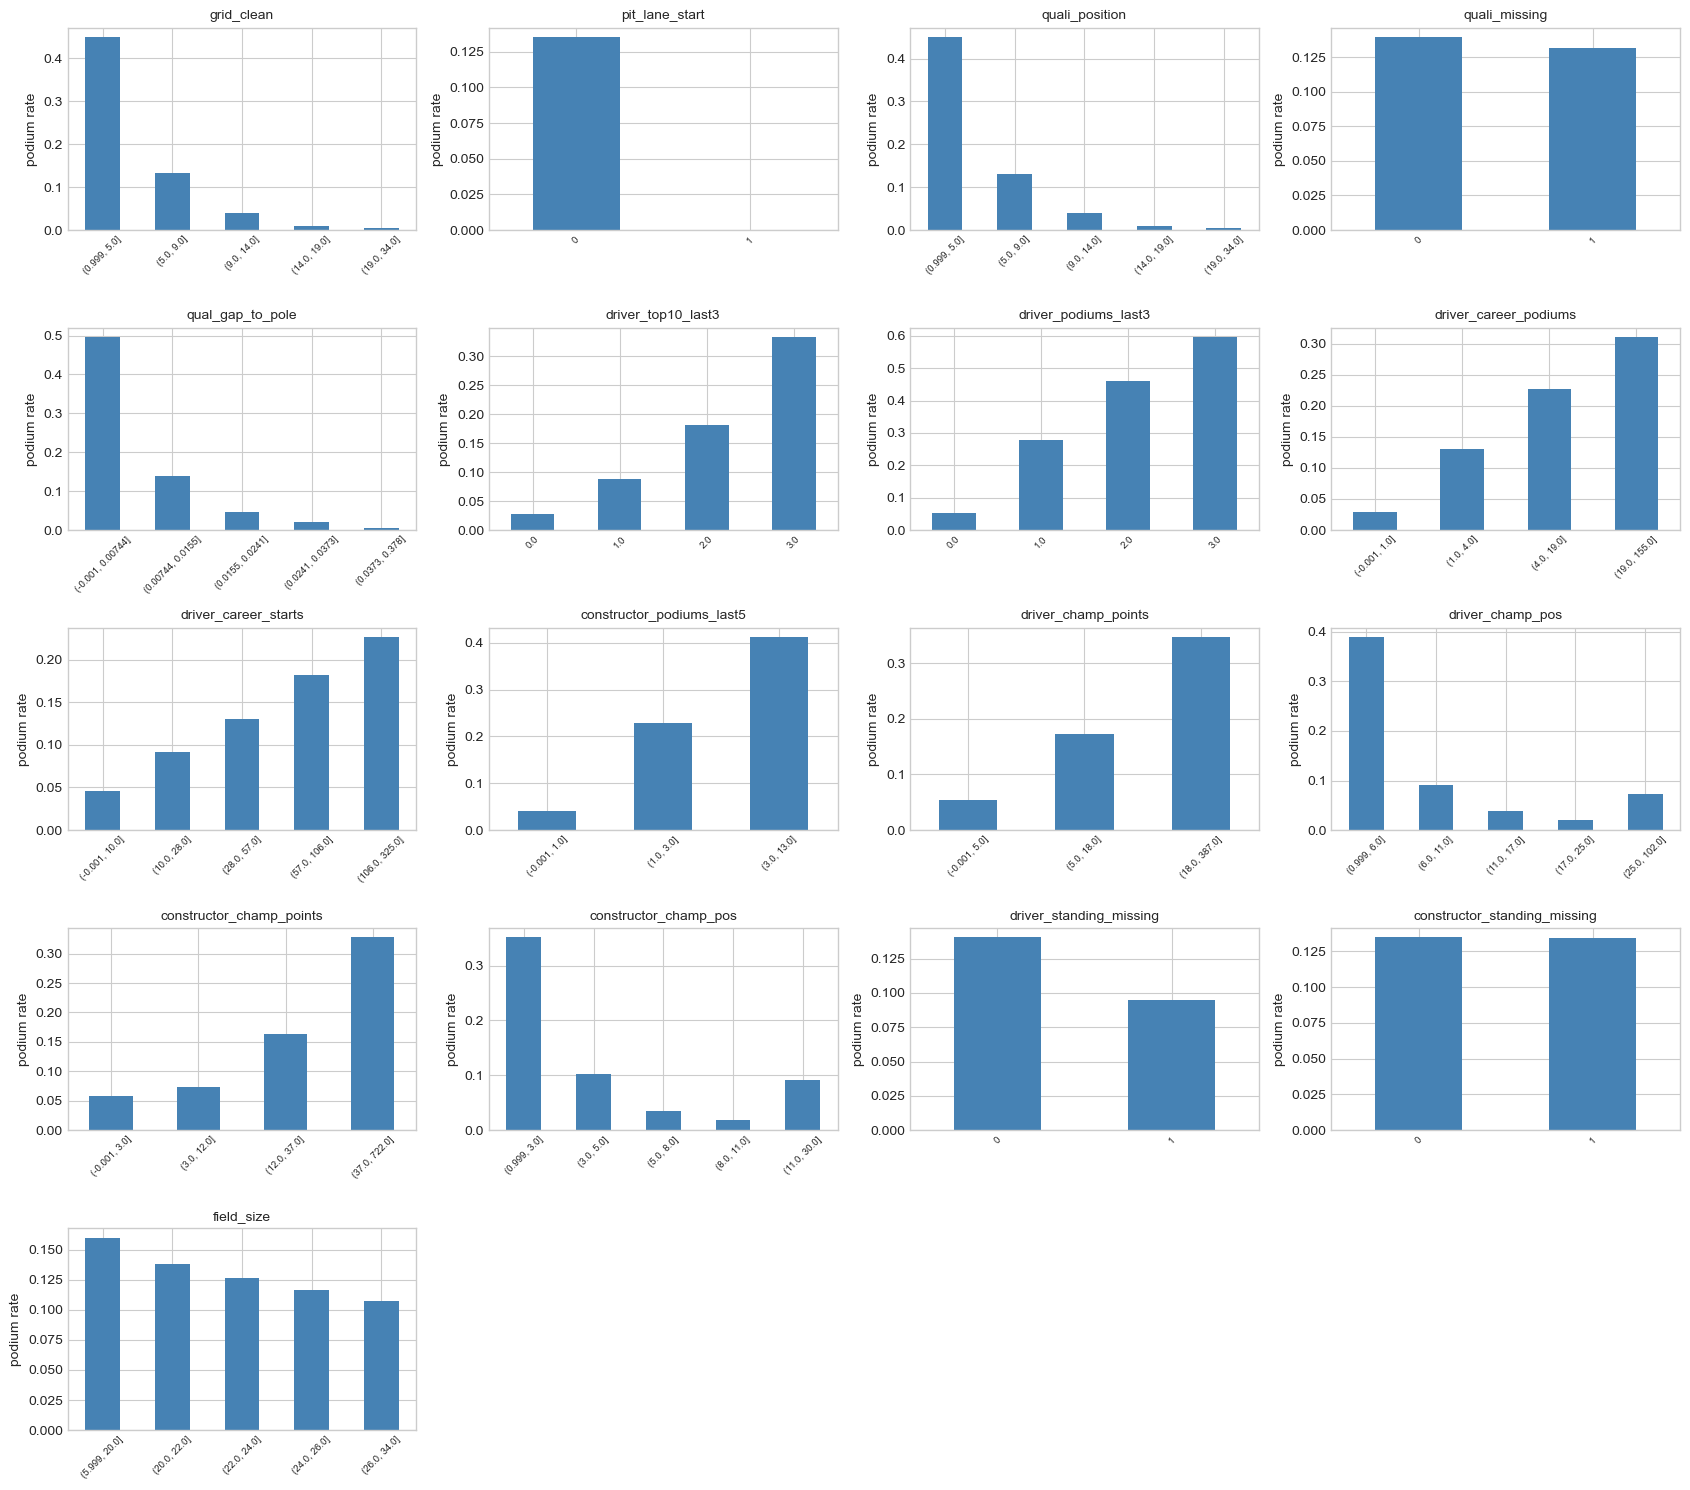

In [47]:
n_cols = 4
n_rows = int(np.ceil(len(ALL_FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 3 * n_rows))
for ax, col in zip(axes.ravel(), ALL_FEATURES):
    x = X_train[col].dropna()
    y = y_train.loc[x.index]
    groups = x if x.nunique() <= 12 else pd.qcut(x, q=5, duplicates="drop")
    rate = y.groupby(groups, observed=True).mean()
    rate.index = rate.index.astype(str)
    rate.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("podium rate")
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
for ax in axes.ravel()[len(ALL_FEATURES):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### [Step 2.10] Median Imputation & Z-Score Scaling Pipeline (Train-Only Fit)
> **Purpose**: Fills remaining missing feature values using training-set medians and standardises all features to zero mean and unit variance, both preprocessing steps fitted exclusively on the training set to prevent test-set information from leaking into the preprocessing.
> **Key Operations**:
> * Fits `SimpleImputer(strategy='median')` on `X_train` only, then transforms train, validation, and test sets using the same training medians (stored in `imputer.statistics_`).
> * Fits `StandardScaler` on the imputed training set only, then applies the same mean/std transformation to all three splits.
> * Asserts zero residual NaN values in `X_train_scaled` and `X_test_scaled` after the pipeline.
> * Prints the exact median used to fill `qual_gap_to_pole` (the most frequently missing feature) and compares descriptive statistics before and after filling to confirm the imputation impact.
> * Verifies that training-set scaled features have near-zero column means and unit standard deviations, confirming the scaler was applied correctly.
> * Renders side-by-side histograms of `qual_gap_to_pole` before and after median fill.
---

median used to fill (from TRAIN only): 0.0197
before: {'count': 8187.0, 'mean': 0.0251, 'std': 0.0257, '50%': 0.0197}
after : {'count': 22553.0, 'mean': 0.0217, 'std': 0.0157, '50%': 0.0197}
scaled TRAIN: largest |mean| = 0.0 | std values = [1.]


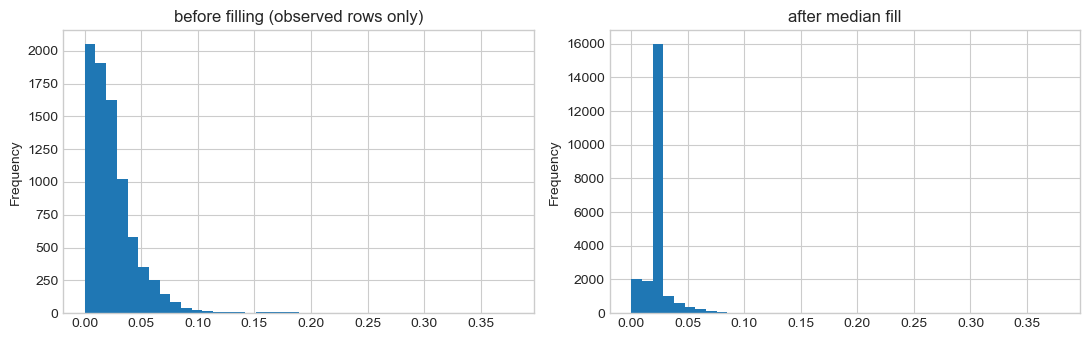

In [48]:
imputer = SimpleImputer(strategy="median").fit(X_train)
def impute(X):
    return pd.DataFrame(imputer.transform(X), columns=X.columns, index=X.index)
X_train_imp, X_val_imp, X_test_imp = impute(X_train), impute(X_val), impute(X_test)

scaler = StandardScaler().fit(X_train_imp)
def scale(X):
    return pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)
X_train_scaled, X_val_scaled, X_test_scaled = scale(X_train_imp), scale(X_val_imp), scale(X_test_imp)

assert not X_train_scaled.isna().any().any() and not X_test_scaled.isna().any().any()

col = "qual_gap_to_pole"
print("median used to fill (from TRAIN only):", round(imputer.statistics_[list(X_train.columns).index(col)], 4))
print("before:", X_train[col].describe().round(4)[["count","mean","std","50%"]].to_dict())
print("after :", X_train_imp[col].describe().round(4)[["count","mean","std","50%"]].to_dict())
print("scaled TRAIN: largest |mean| =", round(X_train_scaled.mean().abs().max(), 6), "| std values =", X_train_scaled.std().round(3).unique())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
X_train[col].plot(kind="hist", bins=40, ax=ax[0], title="before filling (observed rows only)")
X_train_imp[col].plot(kind="hist", bins=40, ax=ax[1], title="after median fill")
plt.tight_layout(); plt.show()

### [Step 2.11] Feature Leakage Guard & Feature Registry Freeze
> **Purpose**: Executes a final automated leakage check by asserting that no post-race variable appears in the feature list, then serialises the confirmed feature registry to a JSON file for reproducibility and cross-team auditability.
> **Key Operations**:
> * Defines `FORBIDDEN`: a set of 12 column names that are only knowable after the race completes — finishing position, race time, points scored, fastest lap, race status, pit stop data, and the raw `podium` label.
> * Asserts the intersection of `FORBIDDEN` and `ALL_FEATURES` is empty; any leaked variable raises an immediate `AssertionError` with the offending column names.
> * Confirms every feature in `ALL_FEATURES` exists in the `base` DataFrame (no phantom features).
> * Validates column order consistency between `X_train`, `X_train_scaled`, and `ALL_FEATURES` to prevent silent column misalignment in downstream steps.
> * Checks for duplicate feature names, which would silently bias tree-based models by double-counting one feature.
> * Writes `features_v1.json` containing the ordered feature list and group dictionary for downstream pipeline reproducibility.
---

In [49]:
import json

FORBIDDEN = {"positionOrder", "position", "positionText", "points", "laps", "milliseconds",
             "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status", "podium"}

leaked = FORBIDDEN & set(ALL_FEATURES)
assert not leaked, f"LEAKAGE: {leaked}"
assert all(c in base.columns for c in ALL_FEATURES), "feature missing from base table"
assert list(X_train.columns) == list(X_train_scaled.columns) == list(ALL_FEATURES)
assert len(ALL_FEATURES) == len(set(ALL_FEATURES)), "duplicate feature"

with open("features_v1.json", "w") as f:
    json.dump({"features": ALL_FEATURES, "groups": FEATURE_GROUPS}, f, indent=2)

print(f"{len(ALL_FEATURES)} features frozen, no forbidden columns.")
for g, cols in FEATURE_GROUPS.items():
    print(f"  {g}: {cols}")

17 features frozen, no forbidden columns.
  Grid: ['grid_clean', 'pit_lane_start']
  Qualifying: ['quali_position', 'quali_missing', 'qual_gap_to_pole']
  Driver form: ['driver_top10_last3', 'driver_podiums_last3', 'driver_career_podiums', 'driver_career_starts']
  Constructor form: ['constructor_podiums_last5']
  Championship standings: ['driver_champ_points', 'driver_champ_pos', 'constructor_champ_points', 'constructor_champ_pos', 'driver_standing_missing', 'constructor_standing_missing']
  Race context: ['field_size']


### [Step 2.12] Baseline & Multi-Model Training with Best-F1 Threshold Selection
> **Purpose**: Trains four classifiers — a rule-based grid baseline, Logistic Regression, Random Forest, and HistGradientBoosting — selecting per-model decision thresholds on the validation set to maximise F1, then reports PR-AUC, ROC-AUC, and F1 across all three splits.
> **Key Operations**:
> * Defines `best_threshold`: sweeps the precision-recall curve on **validation only** to find the probability cutoff that maximises F1, preventing threshold leakage from the test set.
> * **Baseline**: predicts podium if `grid_clean <= 3`; evaluated with the negative grid score as a ranking signal (no model fitting).
> * **Logistic Regression**: trained on z-scaled features with `class_weight='balanced'` and `max_iter=1000`.
> * **Random Forest**: trained on median-imputed features with 300 trees, `min_samples_leaf=5`, and `class_weight='balanced'`.
> * **HistGradientBoosting**: trained directly on raw features (handles NaN natively) with `max_depth=3`, `learning_rate=0.05`, and 300 iterations.
> * Stores all fitted models in `fitted` dict for later interpretability steps.
> * Prints a pivoted comparison table of PR-AUC and F1 across models and splits, and reports each model's validation-tuned decision threshold.
---

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_recall_curve

def best_threshold(y_true, score):
    p, r, t = precision_recall_curve(y_true, score)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return t[np.argmax(f1)]

rows = []

# baseline: podium if grid <= 3 (no fitting, nothing to tune)
for split, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    rows.append({"model": "baseline grid<=3", "split": split,
                 "PR-AUC": average_precision_score(y, -X["grid_clean"]),
                 "ROC-AUC": roc_auc_score(y, -X["grid_clean"]),
                 "F1": f1_score(y, (X["grid_clean"] <= 3).astype(int)), "thr": np.nan})

models = {
    "LogReg": (LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
               X_train_scaled, X_val_scaled, X_test_scaled),
    "RandomForest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=42),
                     X_train_imp, X_val_imp, X_test_imp),
    "HistGB": (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
               X_train, X_val, X_test),
}

fitted = {}
for name, (model, Xtr, Xva, Xte) in models.items():
    model.fit(Xtr, y_train)
    fitted[name] = model
    thr = best_threshold(y_val, model.predict_proba(Xva)[:, 1])   # tuned on VALIDATION only
    for split, X, y in [("train", Xtr, y_train), ("val", Xva, y_val), ("test", Xte, y_test)]:
        s = model.predict_proba(X)[:, 1]
        rows.append({"model": name, "split": split,
                     "PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
                     "F1": f1_score(y, (s >= thr).astype(int)), "thr": thr})

results = pd.DataFrame(rows).round(3)
print(results.pivot(index="model", columns="split", values=["PR-AUC", "F1"]).round(3))
print(results[results.split == "val"][["model", "thr"]].to_string(index=False))

                 PR-AUC                   F1              
split              test  train    val   test  train    val
model                                                     
HistGB            0.701  0.602  0.698  0.679  0.595  0.703
LogReg            0.686  0.569  0.724  0.686  0.580  0.703
RandomForest      0.688  0.868  0.690  0.673  0.769  0.703
baseline grid<=3  0.647  0.499  0.639  0.649  0.543  0.692
           model   thr
baseline grid<=3   NaN
          LogReg 0.759
    RandomForest 0.603
          HistGB 0.342


### [Step 2.13] Feature Group Ablation Study
> **Purpose**: Quantifies the marginal contribution of each of the 6 feature groups by systematically training a Random Forest with one group removed at a time and measuring the resulting drop in validation and test PR-AUC, averaged over 3 random seeds for stability.
> **Key Operations**:
> * Defines 7 configurations: one full-feature model (`ALL`) and one drop configuration per feature group (`drop Grid`, `drop Qualifying`, `drop Driver form`, etc.).
> * For each configuration, trains three Random Forests (seeds 0, 1, 2) on the remaining features and evaluates both validation and test PR-AUC.
> * Computes mean and standard deviation of validation PR-AUC across seeds to account for inherent Random Forest randomness.
> * Calculates `delta val vs ALL`: the signed PR-AUC change when each group is removed (large negative delta = the group adds substantial predictive value).
> * Produces a structured table showing `n_feat`, `val PR-AUC ± std`, `test PR-AUC`, and `delta` to directly rank feature group importance for the report.
---

In [51]:
def run(cols, seed):
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                               n_jobs=-1, random_state=seed)
    m.fit(X_train_imp[cols], y_train)
    return (average_precision_score(y_val, m.predict_proba(X_val_imp[cols])[:, 1]),
            average_precision_score(y_test, m.predict_proba(X_test_imp[cols])[:, 1]))

configs = {"ALL": ALL_FEATURES}
for g, cols in FEATURE_GROUPS.items():
    configs[f"drop {g}"] = [c for c in ALL_FEATURES if c not in cols]

rows = []
for name, cols in configs.items():
    r = np.array([run(cols, s) for s in (0, 1, 2)])
    rows.append({"config": name, "n_feat": len(cols),
                 "val PR-AUC": r[:, 0].mean(), "val std": r[:, 0].std(), "test PR-AUC": r[:, 1].mean()})
abl = pd.DataFrame(rows).round(3)
abl["delta val vs ALL"] = (abl["val PR-AUC"] - abl.loc[0, "val PR-AUC"]).round(3)
print(abl.to_string(index=False))

                     config  n_feat  val PR-AUC  val std  test PR-AUC  delta val vs ALL
                        ALL      17       0.694    0.007        0.686             0.000
                  drop Grid      15       0.675    0.004        0.683            -0.019
            drop Qualifying      14       0.659    0.006        0.713            -0.035
           drop Driver form      13       0.721    0.003        0.675             0.027
      drop Constructor form      16       0.702    0.007        0.692             0.008
drop Championship standings      11       0.672    0.006        0.668            -0.022
          drop Race context      16       0.688    0.008        0.692            -0.006


### [Step 2.14] Preprocessing Sensitivity Analysis (Imputation & Scaling Variants)
> **Purpose**: Tests four alternative preprocessing pipelines applied to Logistic Regression to confirm that the chosen impute→scale approach is robust, and to quantify the score inflation produced by a common data-leakage mistake (fitting the preprocessor on the entire dataset).
> **Key Operations**:
> * **P1 (standard — chosen pipeline)**: median imputation fitted on train → z-score scaling fitted on train. The clean, leakage-free approach used throughout.
> * **P2 (scale → fill 0)**: applies training-set scaling first, then replaces remaining NaN with zero. Avoids imputation but distorts zero-centered distributions for sparse features.
> * **P3 (clip → impute → scale)**: clips `qual_gap_to_pole` to the 1st–99th percentile before applying P1. Evaluates whether extreme outliers materially affect results.
> * **P4 (LEAKY — documentation only)**: fits both the imputer and scaler on the combined train + val + test set. Intentionally leaky; included to document the PR-AUC inflation that a preprocessing leak would silently introduce.
> * Reports validation and test PR-AUC for all four pipelines, providing a numerical upper bound (P4) and confirming P1 as the correct choice.
---

In [52]:
def score_lr(Xtr, Xva, Xte):
    m = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42).fit(Xtr, y_train)
    return (average_precision_score(y_val, m.predict_proba(Xva)[:, 1]),
            average_precision_score(y_test, m.predict_proba(Xte)[:, 1]))

def impute_scale(fit_X, Xs):
    imp = SimpleImputer(strategy="median").fit(fit_X)
    sc = StandardScaler().fit(imp.transform(fit_X))
    return [sc.transform(imp.transform(X)) for X in Xs]

res = {}
# P1: impute -> scale, train only
res["P1 impute->scale (train fit)"] = score_lr(*impute_scale(X_train, [X_train, X_val, X_test]))

# P2: scale (NaN ignored) -> fill 0
sc2 = StandardScaler().fit(X_train)
res["P2 scale->fill 0"] = score_lr(*[np.nan_to_num(sc2.transform(X)) for X in (X_train, X_val, X_test)])

# P3: clip qual_gap_to_pole to train 1-99 pct, then P1
c = "qual_gap_to_pole"
lo, hi = X_train[c].quantile(0.01), X_train[c].quantile(0.99)
def clip(X):
    X = X.copy(); X[c] = X[c].clip(lo, hi); return X
Xtr_c, Xva_c, Xte_c = clip(X_train), clip(X_val), clip(X_test)
res["P3 clip->impute->scale"] = score_lr(*impute_scale(Xtr_c, [Xtr_c, Xva_c, Xte_c]))

# P4: LEAKY, fit on everything (for documentation only)
X_all = pd.concat([X_train, X_val, X_test])
res["P4 LEAKY fit on all data"] = score_lr(*impute_scale(X_all, [X_train, X_val, X_test]))

print(pd.DataFrame(res, index=["val PR-AUC", "test PR-AUC"]).T.round(3))

                              val PR-AUC  test PR-AUC
P1 impute->scale (train fit)       0.724        0.686
P2 scale->fill 0                   0.724        0.686
P3 clip->impute->scale             0.724        0.687
P4 LEAKY fit on all data           0.724        0.686


### [Step 2.15] Shallow Neural Network Hyperparameter Tuning
> **Purpose**: Searches for the best single-hidden-layer MLP configuration by evaluating all combinations of hidden-layer size and L2 regularisation strength, averaged over three random seeds, using validation PR-AUC as the sole selection criterion.
> **Key Operations**:
> * Trains `MLPClassifier` for all 9 combinations of hidden-layer size ∈ {8, 16, 32} and regularisation α ∈ {1e-4, 1e-2, 1e-1}, each repeated over seeds 0, 1, 2.
> * Averages validation PR-AUC across the three seeds to reduce variance from random weight initialisation, and records the standard deviation as a stability measure.
> * Prints a ranked tuning grid showing `hidden`, `alpha`, `val PR-AUC`, and `std`.
> * Refits the best configuration with `random_state=0` on the training set and reports train/val/test PR-AUC, ROC-AUC, and F1 using the validation-tuned threshold, providing the Shallow NN row used in the final comparison table (Step 2.16).
---

In [53]:
from sklearn.neural_network import MLPClassifier

rows = []
for h in (8, 16, 32):
    for a in (1e-4, 1e-2, 1e-1):
        vs = []
        for s in (0, 1, 2):
            m = MLPClassifier(hidden_layer_sizes=(h,), alpha=a, max_iter=500, random_state=s).fit(X_train_scaled, y_train)
            vs.append(average_precision_score(y_val, m.predict_proba(X_val_scaled)[:, 1]))
        rows.append({"hidden": h, "alpha": a, "val PR-AUC": np.mean(vs), "std": np.std(vs)})
nn_grid = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False).round(3)
print(nn_grid.to_string(index=False))

best = nn_grid.iloc[0]
nn = MLPClassifier(hidden_layer_sizes=(int(best["hidden"]),), alpha=float(best["alpha"]),
                   max_iter=500, random_state=0).fit(X_train_scaled, y_train)
thr = best_threshold(y_val, nn.predict_proba(X_val_scaled)[:, 1])   # validation only
for split, X, y in [("train", X_train_scaled, y_train), ("val", X_val_scaled, y_val), ("test", X_test_scaled, y_test)]:
    s = nn.predict_proba(X)[:, 1]
    print(split, "PR-AUC", round(average_precision_score(y, s), 3),
          "ROC-AUC", round(roc_auc_score(y, s), 3), "F1", round(f1_score(y, (s >= thr).astype(int)), 3))
print("threshold (val):", round(thr, 3))

 hidden  alpha  val PR-AUC   std
     32   0.00       0.740 0.007
     32   0.01       0.738 0.011
     32   0.10       0.735 0.009
      8   0.10       0.730 0.005
      8   0.00       0.729 0.006
      8   0.01       0.728 0.007
     16   0.10       0.728 0.010
     16   0.01       0.722 0.013
     16   0.00       0.720 0.014


train PR-AUC 0.603 ROC-AUC 0.91 F1 0.594
val PR-AUC 0.752 ROC-AUC 0.929 F1 0.713
test PR-AUC 0.687 ROC-AUC 0.929 F1 0.669
threshold (val): 0.23


### [Step 2.16] Systematic Hyperparameter Tuning & Model Comparison Table
> **Purpose**: Performs a structured grid search over key hyperparameters for Logistic Regression, Random Forest, and HistGradientBoosting using `ParameterGrid`, selects best configurations by validation PR-AUC, and assembles the primary consolidated model comparison table that appears in the milestone report.
> **Key Operations**:
> * Defines `tune(make, grid, Xtr, Xva, seeds)`: iterates `ParameterGrid`, fits each configuration, and returns all configurations ranked by validation PR-AUC (averaged over multiple seeds where applicable).
> * **LogReg search**: C ∈ {0.01, 0.1, 1, 10}, single seed — 4 trials.
> * **Random Forest search**: `min_samples_leaf` ∈ {3,5,10,20} × `max_features` ∈ {sqrt, 0.5}, 3 seeds — 24 trials for reliability.
> * **HistGB search**: `max_depth` ∈ {2,3,5} × `learning_rate` ∈ {0.03, 0.1}, single seed — 6 trials.
> * Prints the top-3 configurations per model and the validation-tuned decision threshold for each.
> * Assembles `final` DataFrame: val/test PR-AUC, ROC-AUC, and F1 for all 5 models (LogReg, RandomForest, HistGB, ShallowNN, grid baseline), forming the primary comparison table.
---

In [54]:
from sklearn.model_selection import ParameterGrid

def tune(make, grid, Xtr, Xva, seeds=(0,)):
    out = []
    for p in ParameterGrid(grid):
        sc = [average_precision_score(y_val, make(p, s).fit(Xtr, y_train).predict_proba(Xva)[:, 1]) for s in seeds]
        out.append((round(np.mean(sc), 4), p))
    return sorted(out, key=lambda t: -t[0])

mk_lr  = lambda p, s: LogisticRegression(max_iter=1000, class_weight="balanced", random_state=s, **p)
mk_rf  = lambda p, s: RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=s, **p)
mk_hgb = lambda p, s: HistGradientBoostingClassifier(max_iter=300, random_state=s, **p)

setups = {
    "LogReg":       (mk_lr,  {"C": [0.01, 0.1, 1, 10]},                                         X_train_scaled, X_val_scaled, X_test_scaled, (0,)),
    "RandomForest": (mk_rf,  {"min_samples_leaf": [3, 5, 10, 20], "max_features": ["sqrt", 0.5]}, X_train_imp,   X_val_imp,   X_test_imp,   (0, 1, 2)),
    "HistGB":       (mk_hgb, {"max_depth": [2, 3, 5], "learning_rate": [0.03, 0.1]},           X_train,        X_val,        X_test,       (0,)),
}

final_rows, best_params = [], {}
for name, (make, grid, Xtr, Xva, Xte, seeds) in setups.items():
    ranked = tune(make, grid, Xtr, Xva, seeds)
    best_params[name] = ranked[0][1]
    print(name, "top 3 (val PR-AUC, params):", ranked[:3])
    model = make(best_params[name], 0).fit(Xtr, y_train)
    thr_ = best_threshold(y_val, model.predict_proba(Xva)[:, 1])          # validation only
    for split, X, y in [("val", Xva, y_val), ("test", Xte, y_test)]:
        s = model.predict_proba(X)[:, 1]
        final_rows.append({"model": name, "split": split, "PR-AUC": average_precision_score(y, s),
                           "ROC-AUC": roc_auc_score(y, s), "F1": f1_score(y, (s >= thr_).astype(int))})

# shallow NN (already tuned in Cell 15)
for split, X, y in [("val", X_val_scaled, y_val), ("test", X_test_scaled, y_test)]:
    s = nn.predict_proba(X)[:, 1]
    final_rows.append({"model": "ShallowNN", "split": split, "PR-AUC": average_precision_score(y, s),
                       "ROC-AUC": roc_auc_score(y, s), "F1": f1_score(y, (s >= thr).astype(int))})

# baseline rows from Cell 12
final_rows += results[(results.model == "baseline grid<=3") & (results.split != "train")][["model", "split", "PR-AUC", "ROC-AUC", "F1"]].to_dict("records")

final = pd.DataFrame(final_rows).round(3)
print(final.pivot(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1"]))

LogReg top 3 (val PR-AUC, params): [(np.float64(0.7242), {'C': 10}), (np.float64(0.7238), {'C': 0.1}), (np.float64(0.7238), {'C': 1})]


RandomForest top 3 (val PR-AUC, params): [(np.float64(0.7211), {'max_features': 0.5, 'min_samples_leaf': 20}), (np.float64(0.7164), {'max_features': 'sqrt', 'min_samples_leaf': 20}), (np.float64(0.7108), {'max_features': 0.5, 'min_samples_leaf': 10})]


HistGB top 3 (val PR-AUC, params): [(np.float64(0.6912), {'learning_rate': 0.03, 'max_depth': 2}), (np.float64(0.6912), {'learning_rate': 0.03, 'max_depth': 3}), (np.float64(0.6854), {'learning_rate': 0.03, 'max_depth': 5})]


                 PR-AUC        ROC-AUC            F1       
split              test    val    test    val   test    val
model                                                      
HistGB            0.693  0.691   0.936  0.925  0.672  0.702
LogReg            0.686  0.724   0.932  0.927  0.686  0.703
RandomForest      0.698  0.719   0.936  0.928  0.665  0.705
ShallowNN         0.687  0.752   0.929  0.929  0.669  0.713
baseline grid<=3  0.647  0.639   0.914  0.909  0.649  0.692


### [Step 2.17] Full Metrics Evaluation Table Across All Models & Splits
> **Purpose**: Recomputes and consolidates six evaluation metrics — ROC-AUC, PR-AUC, F1, Precision, Recall, and Accuracy — across all three splits (train/val/test) for every model, forming the exhaustive results table cited in the milestone report.
> **Key Operations**:
> * Defines `full_metrics(model_name, scores_by_split, y_by_split, thr)`: given per-split probability scores and a single validation-derived threshold, computes all six metrics and returns a list of records suitable for DataFrame construction.
> * Adds the **grid-only statistical baseline** (Logistic Regression on `grid_clean` alone, threshold selected on validation) to serve as the lower-bound reference performance.
> * Refits LogReg, RandomForest, and HistGB with their best hyperparameters (from Step 2.16) and evaluates across train, val, and test.
> * Includes ShallowNN results using the threshold tuned in Step 2.15.
> * Sorts the full table by model name and split order (train → val → test) and saves to `full_metrics_table.csv` for report reproduction and numerical audit.
---

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, accuracy_score)
import pandas as pd

def full_metrics(model_name, scores_by_split, y_by_split, thr):
    """scores_by_split: {'train': s, 'val': s, 'test': s}; thr chosen on validation."""
    out = []
    for split, s in scores_by_split.items():
        y = y_by_split[split]
        pred = (s >= thr).astype(int)
        out.append({"model": model_name, "split": split,
                    "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                    "F1": f1_score(y, pred), "precision": precision_score(y, pred),
                    "recall": recall_score(y, pred), "accuracy": accuracy_score(y, pred)})
    return out

y_by = {"train": y_train, "val": y_val, "test": y_test}

# statistical baseline: logistic regression on grid position only
lr_grid = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=0)
lr_grid.fit(X_train[["grid_clean"]], y_train)
s_grid = {"train": lr_grid.predict_proba(X_train[["grid_clean"]])[:, 1],
          "val":   lr_grid.predict_proba(X_val[["grid_clean"]])[:, 1],
          "test":  lr_grid.predict_proba(X_test[["grid_clean"]])[:, 1]}
thr_grid = best_threshold(y_val, s_grid["val"])            # validation only

base_lr_rows = full_metrics("baseline LogReg (grid only)", s_grid, y_by, thr_grid)
base_lr = pd.DataFrame(base_lr_rows).round(3)
print("threshold (validation):", round(thr_grid, 3))
print(base_lr.to_string(index=False))

threshold (validation): 0.821
                      model split  ROC-AUC  PR-AUC    F1  precision  recall  accuracy
baseline LogReg (grid only) train    0.883   0.499 0.543      0.546   0.541     0.878
baseline LogReg (grid only)   val    0.909   0.639 0.692      0.692   0.692     0.908
baseline LogReg (grid only)  test    0.914   0.647 0.649      0.650   0.647     0.894


### [Step 2.17b] Consolidated Full Metrics Comparison Table (All Models & All Splits)
> **Purpose**: Assembles a single unified performance table by combining the grid-only statistical baseline, all four tuned models, and the Shallow NN into one sorted DataFrame, then saves it to CSV for report reproduction.
> **Key Operations**:
> * Collects `full_metrics` records for the grid-only baseline (from Step 2.17), all three main models (LogReg, RandomForest, HistGB) refit with best hyperparameters, and the Shallow NN (from Step 2.15).
> * Sorts the combined table by model name and split order (train → val → test) for readability.
> * Prints the complete table with six metrics — ROC-AUC, PR-AUC, F1, Precision, Recall, Accuracy — across all three splits for every model.
> * Saves to `full_metrics_table.csv` on disk for use in the final numerical reproducibility audit (Step 3.7).
---

In [56]:
rows = []

# 1) grid-only baseline (rule == logistic regression on grid)
rows += base_lr_rows

# 2) the four models, refit exactly as in Cell 16 (best params, seed 0), threshold from validation
model_sets = {
    "LogReg":       (mk_lr,  X_train_scaled, X_val_scaled, X_test_scaled),
    "RandomForest": (mk_rf,  X_train_imp,    X_val_imp,    X_test_imp),
    "HistGB":       (mk_hgb, X_train,        X_val,        X_test),
}
for name, (make, Xtr, Xva, Xte) in model_sets.items():
    m = make(best_params[name], 0).fit(Xtr, y_train)
    sc = {"train": m.predict_proba(Xtr)[:, 1],
          "val":   m.predict_proba(Xva)[:, 1],
          "test":  m.predict_proba(Xte)[:, 1]}
    rows += full_metrics(name, sc, y_by, best_threshold(y_val, sc["val"]))

# 3) shallow NN (trained in Cell 15, threshold `thr` from validation)
sc_nn = {"train": nn.predict_proba(X_train_scaled)[:, 1],
         "val":   nn.predict_proba(X_val_scaled)[:, 1],
         "test":  nn.predict_proba(X_test_scaled)[:, 1]}
rows += full_metrics("ShallowNN", sc_nn, y_by, thr)

full_table = pd.DataFrame(rows).round(3)
order = {"train": 0, "val": 1, "test": 2}
full_table = full_table.sort_values(["model", "split"], key=lambda c: c.map(order) if c.name == "split" else c)
print(full_table.to_string(index=False))
full_table.to_csv("full_metrics_table.csv", index=False)

                      model split  ROC-AUC  PR-AUC    F1  precision  recall  accuracy
                     HistGB train    0.908   0.597 0.594      0.529   0.678     0.875
                     HistGB   val    0.925   0.691 0.702      0.672   0.735     0.906
                     HistGB  test    0.936   0.693 0.672      0.606   0.755     0.889
                     LogReg train    0.900   0.569 0.581      0.534   0.636     0.876
                     LogReg   val    0.927   0.724 0.703      0.697   0.709     0.910
                     LogReg  test    0.932   0.686 0.686      0.618   0.770     0.894
               RandomForest train    0.940   0.699 0.625      0.658   0.596     0.904
               RandomForest   val    0.928   0.719 0.705      0.738   0.675     0.915
               RandomForest  test    0.936   0.698 0.665      0.679   0.652     0.901
                  ShallowNN train    0.910   0.603 0.594      0.477   0.787     0.855
                  ShallowNN   val    0.929   0.752 0.7

### [Step 2.18] Championship Points Normalisation Engineering
> **Purpose**: Engineers two alternative encodings of cumulative championship points — within-race z-scores and fraction-of-leader ratios — to test whether normalising for field competitiveness improves discrimination compared to using raw cumulative point totals.
> **Key Operations**:
> * Defines `add_norm(df, ref)`: for both `driver_champ_points` and `constructor_champ_points`, computes two race-level normalised variants:
>   - `*_z`: z-score of each driver's points relative to the mean and std of all drivers in the same race (filled with 0.0 if std = 0, i.e. round 1 when all points are equal).
>   - `*_ratio`: each driver's points as a fraction of the race leader's total (filled with 0.0 if the leader has 0 points at the season opener).
> * Applies `add_norm` to all three splits using the `raceId` column from the base table to define within-race groupings, producing augmented feature matrices `Xtr_n`, `Xva_n`, `Xte_n`.
---

In [57]:
def add_norm(df, ref):
    """ref = base rows (needs raceId) aligned to df's index."""
    out = df.copy()
    g_race = ref.loc[df.index, "raceId"]
    for col in ["driver_champ_points", "constructor_champ_points"]:
        grp = df[col].groupby(g_race)
        mu, sd, mx = grp.transform("mean"), grp.transform("std"), grp.transform("max")
        out[col + "_z"] = ((df[col] - mu) / sd).where(sd > 0, 0.0)      # round 1: std 0 -> 0
        out[col + "_ratio"] = (df[col] / mx).where(mx > 0, 0.0)         # round 1: max 0 -> 0
    return out

Xtr_n = add_norm(X_train, base)
Xva_n = add_norm(X_val, base)
Xte_n = add_norm(X_test, base)

RAW = ["driver_champ_points", "constructor_champ_points"]
Z   = [c + "_z" for c in RAW]
RAT = [c + "_ratio" for c in RAW]

### [Step 2.19] Points Scale Sensitivity Analysis (Raw vs. Normalised Variants)
> **Purpose**: Evaluates four feature variants for championship points representation to determine whether points normalisation or gap-feature removal materially improves or degrades validation and test PR-AUC for both Logistic Regression and Random Forest.
> **Key Operations**:
> * Defines four variants: **A** (original raw cumulative points), **B** (z-scored points), **C** (leader-ratio points), **D** (original without `qual_gap_to_pole`).
> * For each variant, trains Logistic Regression via `make_pipeline` (imputer + scaler + LR) and Random Forest over 3 seeds for stability.
> * Reports `LogReg val`, `RF val (mean ± std)`, `LogReg test`, and `RF test (mean)` for all four variants in a single comparison table.
> * Probes two edge-case subsets as additional diagnostics: (1) round-1 rows where all championship points features are necessarily 0, to verify the model isn't over-relying on them; (2) drivers with standings position ≥ 20, to verify low-points drivers are correctly assigned near-zero podium probability.
---

In [58]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score
import numpy as np, pandas as pd

variants = {
    "A  original (raw points)": ALL_FEATURES,
    "B  points -> z-score":     [f for f in ALL_FEATURES if f not in RAW] + Z,
    "C  points -> leader ratio": [f for f in ALL_FEATURES if f not in RAW] + RAT,
    "D  original, no qual_gap": [f for f in ALL_FEATURES if f != "qual_gap_to_pole"],
}

def pr(model, X, y):
    return average_precision_score(y, model.predict_proba(X)[:, 1])

rows = []
for name, feats in variants.items():
    lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       mk_lr(best_params["LogReg"], 0))
    lr.fit(Xtr_n[feats], y_train)
    rf_val, rf_te = [], []
    for s in range(3):
        rf = make_pipeline(SimpleImputer(strategy="median"),
                           mk_rf(best_params["RandomForest"], s))
        rf.fit(Xtr_n[feats], y_train)
        rf_val.append(pr(rf, Xva_n[feats], y_val))
        rf_te.append(pr(rf, Xte_n[feats], y_test))

    rows.append({
        "variant": name,
        "n_features": len(feats),
        "LogReg val": pr(lr, Xva_n[feats], y_val),
        "RF val (mean)": np.mean(rf_val),
        "RF val (std)": np.std(rf_val),
        "LogReg test": pr(lr, Xte_n[feats], y_test),
        "RF test (mean)": np.mean(rf_te),
    })

cmp_ = pd.DataFrame(rows).round(3)
print(cmp_.to_string(index=False))

                  variant  n_features  LogReg val  RF val (mean)  RF val (std)  LogReg test  RF test (mean)
 A  original (raw points)          17       0.724          0.721         0.004        0.686           0.700
     B  points -> z-score          17       0.716          0.706         0.003        0.691           0.702
C  points -> leader ratio          17       0.710          0.707         0.004        0.688           0.706
 D  original, no qual_gap          16       0.723          0.704         0.011        0.683           0.718


### [Step 2.19b] Championship Points Edge-Case Probe (Round 1 & Low-Standing Drivers)
> **Purpose**: Validates that championship points features carry genuine discriminative signal beyond their mechanical fill values by probing two specific edge-case subsets where the features would otherwise appear uninformative.
> **Key Operations**:
> * Computes the podium rate among **round-1 rows** (where all pre-race championship points are 0 by definition), verifying that a near-baseline rate confirms the model cannot exploit points at the season opener.
> * Computes the podium rate among **non-round-1 rows where `driver_champ_pos >= 20`** (drivers ranked far down the standings), confirming such drivers carry near-zero podium probability — demonstrating the standings features have real discriminative power once the season is underway.
---

In [59]:
m1 = base["round"] == 1
print("podium rate, round-1 rows:", round(base.loc[m1, "target_podium"].mean(), 3))
late = (~m1) & (base["driver_champ_pos"] >= 20)
print("podium rate, later rounds with a standing of 20 or worse:", round(base.loc[late, "target_podium"].mean(), 3))

podium rate, round-1 rows: 0.143
podium rate, later rounds with a standing of 20 or worse: 0.026


---
## Section 3: Model Interpretability — SHAP & LIME
> **Overview**: Uses two complementary explanation methods — **SHAP** (SHapley Additive exPlanations) and **LIME** (Local Interpretable Model-Agnostic Explanations) — to audit why the final Random Forest makes specific predictions, both globally across the test set and locally for individual race-driver instances. Together these satisfy the interpretability requirements of the milestone brief.
---

### [Step 3.1] Final Model Selection & Confirmed Performance
> **Purpose**: Locks in the best-performing model (Random Forest with tuned hyperparameters from Step 2.16) as the single final model for all subsequent interpretation and inference steps, and confirms its performance on both the validation and test sets.
> **Key Operations**:
> * Refits `RandomForestClassifier` using `best_params['RandomForest']` with `random_state=0` on the median-imputed training set (`X_train_imp`, `y_train`).
> * Computes the validation-tuned decision threshold (`final_thr`) using `best_threshold` on the validation set — this threshold is fixed and carried forward to all downstream steps.
> * Evaluates and prints PR-AUC and F1 on the validation and test sets as a final performance confirmation before interpretability analysis begins.
> * Records `final_model`, `final_thr`, and `final_name = 'RandomForest'` as named module-level objects accessible by all subsequent cells.
---

In [60]:
final_name = "RandomForest"
final_model = mk_rf(best_params[final_name], 0).fit(X_train_imp, y_train)
final_thr = best_threshold(y_val, final_model.predict_proba(X_val_imp)[:, 1]) 

for split, X, y in [("val", X_val_imp, y_val), ("test", X_test_imp, y_test)]:
    s = final_model.predict_proba(X)[:, 1]
    print(split, "PR-AUC", round(average_precision_score(y, s), 3),
          "F1", round(f1_score(y, (s >= final_thr).astype(int)), 3))
print("params:", best_params[final_name], "| threshold:", round(final_thr, 3))

val PR-AUC 0.719 F1 0.705
test PR-AUC 0.698 F1 0.665
params: {'max_features': 0.5, 'min_samples_leaf': 20} | threshold: 0.787


### [Step 3.2b] Permutation Importance: Function Definition & Execution
> **Purpose**: Defines the `perm_importance` routine and runs it at both the individual feature level (15 features) and the semantic group level (6 groups) on the held-out test set, producing the importance tables and charts for the report.
> **Key Operations**:
> * Defines `perm_importance(model, X, y, groups, n_repeats=20, seed=0)`: uses a seeded `RandomState` to shuffle each group's columns 20 times, measuring the mean and std of the resulting PR-AUC drop across repeats.
> * Runs feature-level importance: each of the 15 features shuffled independently, revealing individual predictive contribution on the test set.
> * Runs group-level importance: all features within a group shuffled simultaneously, measuring the joint marginal contribution of each semantic category.
> * Prints ranked tables for both granularities (mean drop ± std).
> * Renders two side-by-side horizontal bar charts with error bars for features (left) and groups (right), colour-coded to distinguish the two levels of analysis.
---

test PR-AUC before shuffling: 0.698

Per feature (drop in PR-AUC):
                                 drop     std
grid_clean                    0.1102  0.0293
quali_position                0.0911  0.0251
constructor_podiums_last5     0.0166  0.0121
driver_career_podiums         0.0140  0.0081
driver_champ_pos              0.0138  0.0109
driver_champ_points           0.0004  0.0056
field_size                    0.0001  0.0001
constructor_standing_missing  0.0000  0.0000
quali_missing                 0.0000  0.0000
pit_lane_start                0.0000  0.0000
driver_standing_missing      -0.0002  0.0001
driver_top10_last3           -0.0008  0.0009
driver_podiums_last3         -0.0013  0.0056
driver_career_starts         -0.0014  0.0025
constructor_champ_points     -0.0019  0.0056
constructor_champ_pos        -0.0024  0.0031
qual_gap_to_pole             -0.0254  0.0076

Per group:
                           drop     std
Grid                    0.1102  0.0293
Qualifying              0.0990 

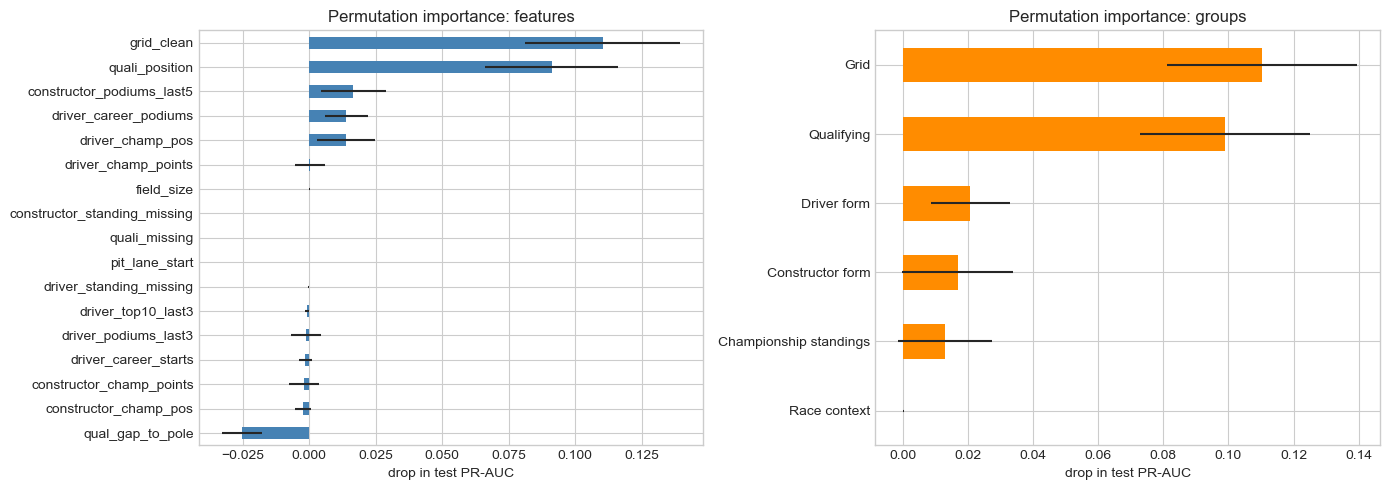

In [61]:
def perm_importance(model, X, y, groups, n_repeats=20, seed=0):
    rng = np.random.RandomState(seed)
    base_score = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            idx = rng.permutation(len(X))
            Xp[cols] = X[cols].values[idx]
            drops.append(base_score - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out[name] = (np.mean(drops), np.std(drops))
    return base_score, pd.DataFrame(out, index=["drop", "std"]).T.sort_values("drop", ascending=False)

base_s, pi_feat = perm_importance(final_model, X_test_imp, y_test, {c: [c] for c in ALL_FEATURES})
_,      pi_grp  = perm_importance(final_model, X_test_imp, y_test, FEATURE_GROUPS)

print("test PR-AUC before shuffling:", round(base_s, 3))
print("\nPer feature (drop in PR-AUC):\n", pi_feat.round(4))
print("\nPer group:\n", pi_grp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pi_feat["drop"].sort_values().plot(kind="barh", xerr=pi_feat["std"].loc[pi_feat["drop"].sort_values().index], ax=ax[0], color="steelblue", title="Permutation importance: features")
pi_grp["drop"].sort_values().plot(kind="barh", xerr=pi_grp["std"].loc[pi_grp["drop"].sort_values().index], ax=ax[1], color="darkorange", title="Permutation importance: groups")
for a in ax: a.set_xlabel("drop in test PR-AUC")
plt.tight_layout(); plt.show()

### [Step 3.2] Permutation Feature Importance (Feature-Level & Group-Level)
> **Purpose**: Quantifies the importance of each individual feature and each feature group by measuring the drop in test PR-AUC when that feature (or group) is randomly shuffled, providing a model-agnostic importance ranking free from tree-structure depth or split-frequency biases.
> **Key Operations**:
> * Defines `perm_importance(model, X, y, groups, n_repeats=20, seed=0)`: for each group, shuffles the corresponding columns `n_repeats` times, measures mean and std of PR-AUC drop across repeats, and returns a ranked DataFrame.
> * Runs feature-level importance (15 individual features, each shuffled independently) on the held-out test set.
> * Runs group-level importance (6 semantic groups, shuffling all group members simultaneously) on the test set to measure the joint contribution of each feature family.
> * Prints ranked tables of mean PR-AUC drop ± std for both granularities.
> * Also evaluates the combined importance of `grid_clean + quali_position` and the standalone importance of `qual_gap_to_pole` on both val and test, and reports the share of rows with a real (non-imputed) qualifying gap value per split.
> * Renders two side-by-side horizontal bar charts with error bars for features and groups.
---

In [62]:
extra = {"grid_clean+quali_position": ["grid_clean", "quali_position"],
         "qual_gap_to_pole": ["qual_gap_to_pole"]}

for nm, X, y in [("VAL", X_val_imp, y_val), ("TEST", X_test_imp, y_test)]:
    b, t = perm_importance(final_model, X, y, extra)
    print(nm, "baseline PR-AUC:", round(b, 3))
    print(t.round(4), "\n")

print("share of rows with a real (non-filled) qual_gap_to_pole:")
for nm, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"  {nm}: {X['qual_gap_to_pole'].notna().mean():.2%}")

VAL baseline PR-AUC: 0.719
                             drop     std
grid_clean+quali_position  0.3063  0.0303
qual_gap_to_pole           0.0011  0.0127 



TEST baseline PR-AUC: 0.698
                             drop     std
grid_clean+quali_position  0.3215  0.0264
qual_gap_to_pole          -0.0211  0.0074 

share of rows with a real (non-filled) qual_gap_to_pole:
  train: 36.30%
  val: 98.84%
  test: 99.04%


### [Step 3.3] SHAP Global Explainability: Beeswarm & Mean Absolute SHAP
> **Purpose**: Computes SHAP values for the final Random Forest on a 500-row test sample and visualises both the global feature impact distribution (beeswarm) and the mean absolute SHAP magnitude (bar chart), providing an aggregate, direction-aware explanation of feature influence.
> **Key Operations**:
> * Initialises a `shap.TreeExplainer` on `final_model` for computationally efficient exact SHAP value computation without sampling approximations.
> * Samples 500 rows from `X_test_imp` with `random_state=0` to keep runtime manageable while maintaining representativeness.
> * Extracts the SHAP value matrix for the positive class (`podium = 1`), handling both list-of-arrays and 3-D tensor SHAP outputs across library versions.
> * Renders a **beeswarm plot**: each row is a feature, each dot a test instance; dot colour encodes feature value (red = high, blue = low) and horizontal position shows SHAP contribution direction and magnitude.
> * Renders a **mean |SHAP| bar chart** showing average absolute push per feature, equivalent to a model-consistent feature importance ranking.
> * Prints the top-10 features by mean absolute SHAP for direct quotation in the report.
---

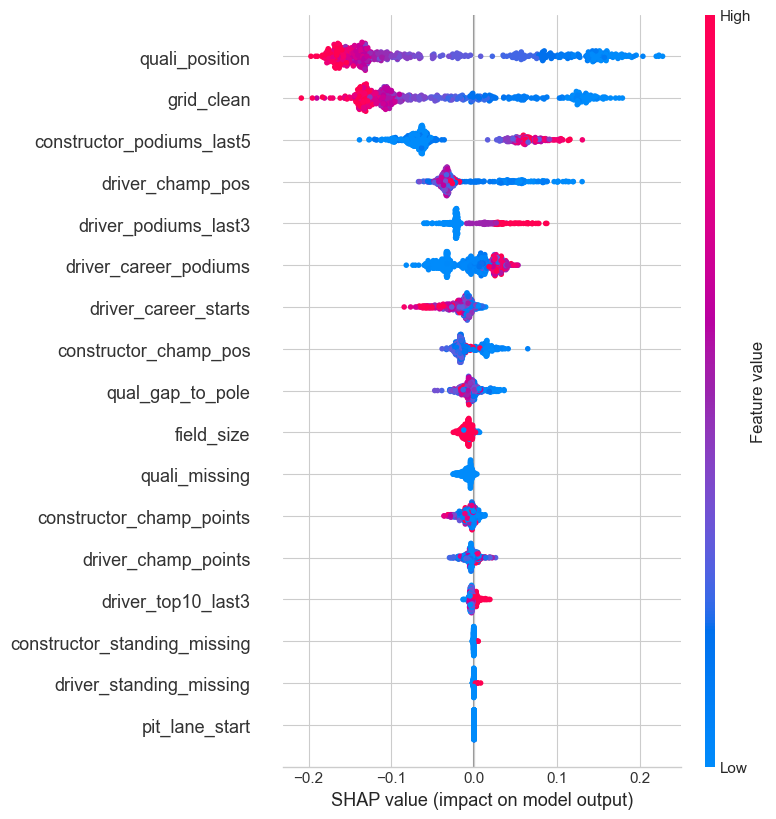

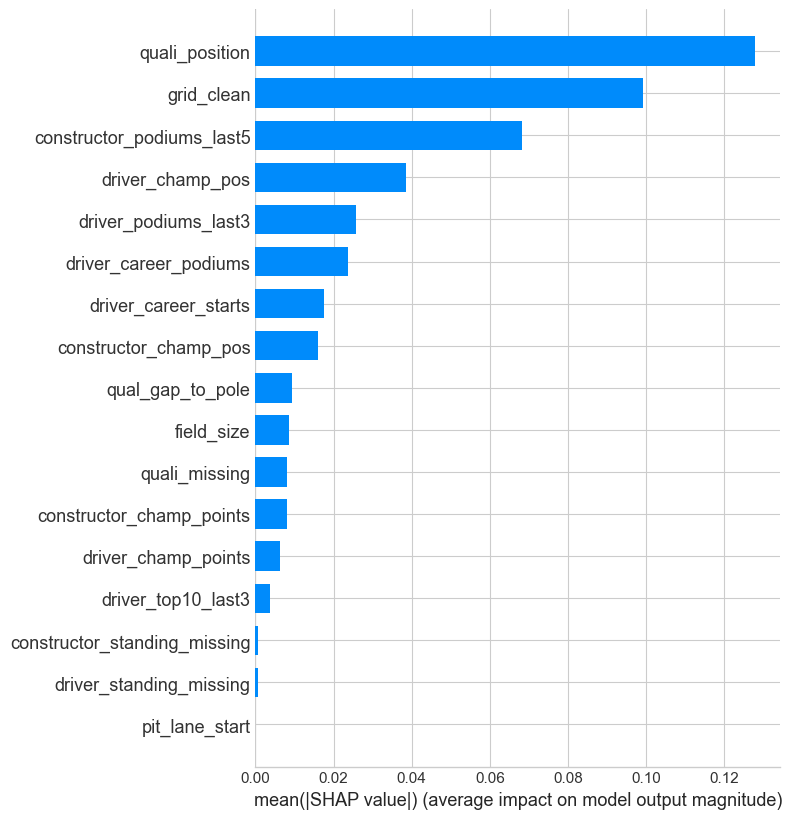

quali_position               0.1279
grid_clean                   0.0992
constructor_podiums_last5    0.0682
driver_champ_pos             0.0386
driver_podiums_last3         0.0256
driver_career_podiums        0.0236
driver_career_starts         0.0175
constructor_champ_pos        0.0159
qual_gap_to_pole             0.0094
field_size                   0.0085
dtype: float64


In [63]:
import shap   # on Kaggle: shap is usually installed; if not, pip install shap needs Internet turned on in the notebook settings

explainer = shap.TreeExplainer(final_model)
Xs = X_test_imp.sample(500, random_state=0)
sv = explainer.shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)   # keep the "podium" class

plt.figure(); shap.summary_plot(sv, Xs, show=False); plt.tight_layout(); plt.show()                     # beeswarm
plt.figure(); shap.summary_plot(sv, Xs, plot_type="bar", show=False); plt.tight_layout(); plt.show()    # mean |push|

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=Xs.columns).sort_values(ascending=False)
print(mean_abs.round(4).head(10))

### [Step 3.4] SHAP Local Explainability: Case Studies (Best Hit vs. Hardest Miss)
> **Purpose**: Applies SHAP waterfall plots to two carefully selected individual predictions — the podium the model was most confident about and the podium it most severely under-scored — to explain, feature-by-feature, why the model gave each output.
> **Key Operations**:
> * Identifies **`case_hit`**: the actual podium finisher in the test set assigned the highest model-predicted probability (the model's clearest correct prediction).
> * Identifies **`case_miss`**: the actual podium finisher assigned the **lowest** predicted probability (the model's hardest miss — a podium it barely recognised as possible).
> * For each case, computes SHAP values and verifies the additive consistency property: `base_value + sum(SHAP values) ≈ predicted probability`.
> * Looks up driver names from `dfs['drivers']` and prints race context (year, round, driver name, starting grid, and predicted probability) for interpretability.
> * Renders a **SHAP waterfall plot** for each case showing how each feature pushes the prediction above or below the model's base rate, with positive bars indicating features that increased the podium probability.
---

HIT: podium the model was sure about: 2022 round 9, Max Verstappen, grid 1, predicted prob 0.99, check baseline + sum(SHAP) = 0.99


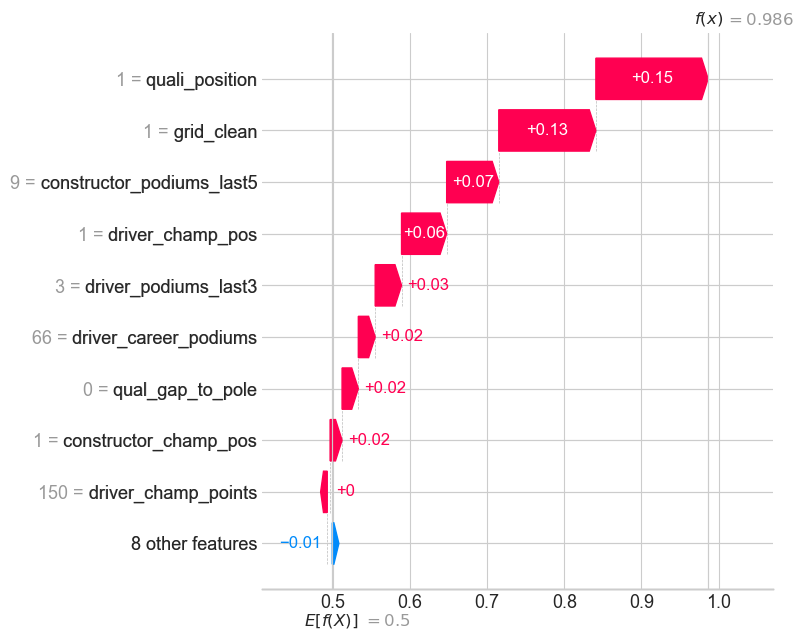

MISS: podium the model missed: 2023 round 13, Pierre Gasly, grid 12, predicted prob 0.03, check baseline + sum(SHAP) = 0.03


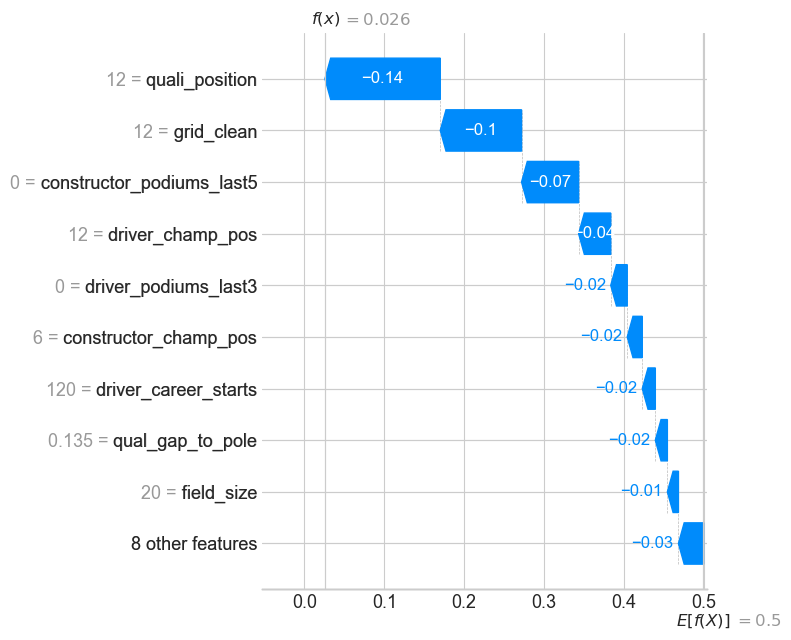

In [64]:
def podium_shap(X):
    v = explainer.shap_values(X)
    return v[1] if isinstance(v, list) else (v[..., 1] if v.ndim == 3 else v)

ev = explainer.expected_value
ev = float(ev[1]) if np.ndim(ev) > 0 else float(ev)

try:
    _dr = dfs["drivers"].set_index("driverId")
    name = lambda d: f"{_dr.loc[d, 'forename']} {_dr.loc[d, 'surname']}"
except Exception:
    name = lambda d: f"driver {d}"

p_test = pd.Series(final_model.predict_proba(X_test_imp)[:, 1], index=X_test_imp.index)
pods = y_test[y_test == 1].index
case_hit, case_miss = p_test.loc[pods].idxmax(), p_test.loc[pods].idxmin()

for label, i in [("HIT: podium the model was sure about", case_hit), ("MISS: podium the model missed", case_miss)]:
    row = X_test_imp.loc[[i]]
    s = podium_shap(row)[0]
    meta = base.loc[i, ["year", "round", "driverId"]]
    print(f"{label}: {int(meta['year'])} round {int(meta['round'])}, {name(meta['driverId'])}, "
          f"grid {int(row['grid_clean'].iloc[0])}, predicted prob {p_test.loc[i]:.2f}, "
          f"check baseline + sum(SHAP) = {ev + s.sum():.2f}")
    shap.plots.waterfall(shap.Explanation(values=s, base_values=ev, data=row.iloc[0].values,
                                          feature_names=list(row.columns)), show=False)
    plt.tight_layout(); plt.show()

### [Step 3.5] LIME Local Explainability: Hit & Miss Case Studies
> **Purpose**: Applies LIME to the same two test instances from Step 3.4 to provide a complementary, model-agnostic local explanation that approximates the forest's decision boundary with a locally-fitted linear model, enabling cross-validation of SHAP findings.
> **Key Operations**:
> * Initialises `LimeTabularExplainer` using `X_train_imp` as the background distribution, with continuous features discretised into bins for human-readable rule generation.
> * Defines `predict_fn` as a wrapper around `final_model.predict_proba`, accepting numpy arrays and returning class probabilities, satisfying LIME's model-agnostic interface.
> * For both `case_hit` and `case_miss`, calls `explain_instance` with 3,000 synthetic perturbation samples and extracts the top 8 feature rules.
> * Prints each feature rule and its signed LIME weight (positive weight = pushes prediction toward podium; negative = pushes away from podium) for direct report citation.
> * Renders a LIME bar chart for each case showing the magnitude and direction of the top-8 rule contributions, providing an intuitive local linear approximation of the model boundary.
---


HIT (LIME top 8, weight = push toward podium):
  +0.217  quali_position <= 6.00
  +0.182  grid_clean <= 6.00
  +0.089  constructor_podiums_last5 > 2.00
  +0.065  driver_career_podiums > 13.00
  +0.063  driver_champ_pos <= 7.00
  +0.057  driver_podiums_last3 > 1.00
  +0.042  constructor_champ_pos <= 3.00
  -0.019  driver_career_starts > 91.00


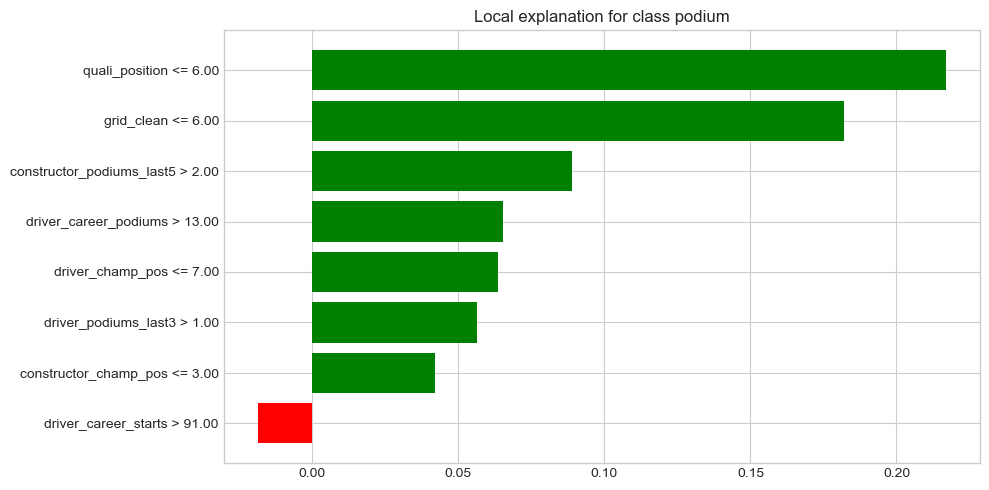


MISS (LIME top 8, weight = push toward podium):
  -0.058  constructor_podiums_last5 <= 0.00
  -0.039  driver_podiums_last3 <= 0.00
  +0.039  2.00 < driver_career_podiums <= 13.00
  +0.031  pit_lane_start <= 0.00
  -0.024  6.00 < quali_position <= 12.00
  +0.018  field_size <= 20.00
  -0.016  quali_missing <= 0.00
  -0.016  7.00 < driver_champ_pos <= 14.00


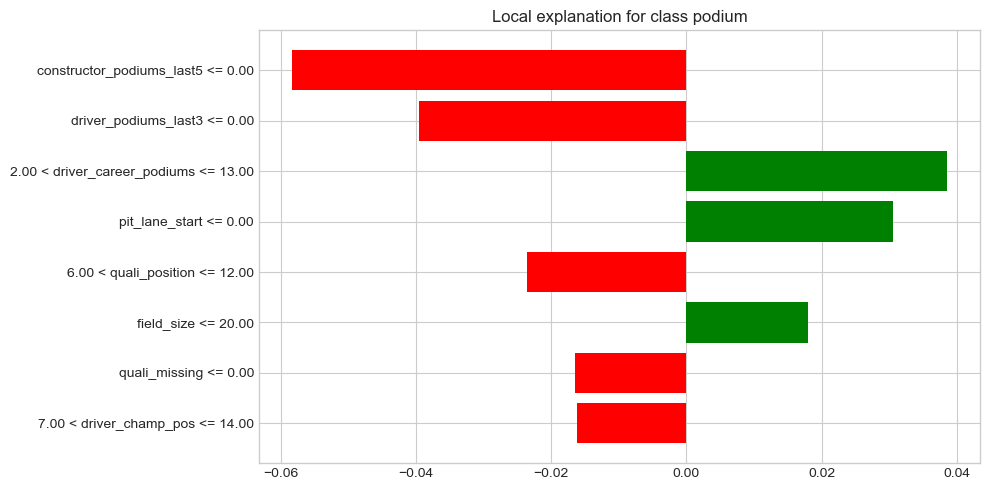

In [65]:
from lime.lime_tabular import LimeTabularExplainer

lime_exp = LimeTabularExplainer(
    X_train_imp.values, feature_names=list(X_train_imp.columns),
    class_names=["no podium", "podium"], mode="classification",
    discretize_continuous=True, random_state=0)

predict_fn = lambda a: final_model.predict_proba(pd.DataFrame(a, columns=ALL_FEATURES))

for label, i in [("HIT", case_hit), ("MISS", case_miss)]:
    row = X_test_imp.loc[i].values
    e = lime_exp.explain_instance(row, predict_fn, num_features=8, num_samples=3000)
    print(f"\n{label} (LIME top 8, weight = push toward podium):")
    for rule, w in e.as_list():
        print(f"  {w:+.3f}  {rule}")
    e.as_pyplot_figure(); plt.tight_layout(); plt.show()

### [Step 3.5b] Split Year Range & Row Distribution Audit
> **Purpose**: Verifies that the three data splits (train, validation, test) span the correct year ranges and that no temporal overlap exists between them, providing a final audit trail before the inference API and calibration steps.
> **Key Operations**:
> * Retrieves the `year` column for train, val, and test index subsets from the base table.
> * Prints the min/max year and row count for each split (expected: train 1950–2019, val 2020–2021, test 2022–2024).
> * Prints the row count per year for the first 10 training years to confirm early seasons have fewer entries due to smaller grids.
---

In [66]:
tr = base.loc[X_train.index, "year"]
print("train:", tr.min(), "to", tr.max(), "| rows", len(tr))
print("val  :", base.loc[X_val.index, "year"].agg(["min", "max"]).tolist())
print("test :", base.loc[X_test.index, "year"].agg(["min", "max"]).tolist())
print(tr.value_counts().sort_index().head(10))

train: 1950 to 2019 | rows 22553
val  : [2020, 2021]
test : [2022, 2024]
year
1950    121
1951    139
1952    165
1953    193
1954    163
1955    118
1956    139
1957    125
1958    190
1959    146
Name: count, dtype: int64


### [Step 3.6] Inference API & Platt-Calibrated Probability Estimation
> **Purpose**: Exposes the final Random Forest as a clean dictionary-based inference function with built-in input validation, missing value handling, and calibrated probability output, making the model deployable as a pre-race prediction API endpoint.
> **Key Operations**:
> * **Calibration**: fits a logistic regressor on validation-set model scores vs. true labels (Platt scaling) to map raw forest scores to calibrated probabilities that match the empirical podium rate, correcting the forest's known tendency to compress probabilities toward 0.5.
> * Defines `predict_podium(record: dict) → dict` which:
>   - Raises `ValueError` for any input key not in `ALL_FEATURES` (leakage guard at inference).
>   - Auto-infers `quali_missing`, `driver_standing_missing`, and `constructor_standing_missing` flags from whichever fields the caller omits.
>   - Falls back `quali_position` to `grid_clean` if qualifying data is absent (same imputation rule as training).
>   - Imputes remaining missing values using stored training-set medians.
>   - Returns `score` (raw forest), `podium_prob_calibrated`, `predict_podium` (bool), `filled_with_train_median` (list of imputed fields), and a warning if >50% of inputs were missing.
> * Demonstrates three API calls: a fully-specified record, a partial record (4 fields omitted), and an attempt to pass a forbidden post-race field (blocked with `ValueError`).
> * Validates calibration quality by comparing mean calibrated probability to the actual podium rate on validation and test sets.
---

In [67]:
from sklearn.linear_model import LogisticRegression

val_scores = final_model.predict_proba(X_val_imp)[:, 1]
calibrator = LogisticRegression(C=1e6).fit(val_scores.reshape(-1, 1), y_val)   # validation only

def predict_podium(record: dict) -> dict:
    unknown = set(record) - set(ALL_FEATURES)
    if unknown:
        raise ValueError(f"Unknown or not-allowed fields (possible leakage): {sorted(unknown)}")
    row = pd.DataFrame([{c: record.get(c, np.nan) for c in ALL_FEATURES}]).apply(pd.to_numeric, errors="coerce")

    isna = lambda c: bool(pd.isna(row.loc[0, c]))
    # flags the caller did not supply
    if isna("quali_missing"):
        row.loc[0, "quali_missing"] = float(isna("quali_position"))
    if isna("driver_standing_missing"):
        row.loc[0, "driver_standing_missing"] = float(isna("driver_champ_points") and isna("driver_champ_pos"))
    if isna("constructor_standing_missing"):
        row.loc[0, "constructor_standing_missing"] = float(isna("constructor_champ_points") and isna("constructor_champ_pos"))
    # same rule as training: qualifying position falls back to the grid
    if isna("quali_position") and not isna("grid_clean"):
        row.loc[0, "quali_position"] = row.loc[0, "grid_clean"]

    filled = [c for c in ALL_FEATURES if isna(c)]
    X_row = pd.DataFrame(imputer.transform(row), columns=ALL_FEATURES)          # train medians
    score = float(final_model.predict_proba(X_row)[0, 1])
    return {"score": round(score, 3),
            "podium_prob_calibrated": round(float(calibrator.predict_proba([[score]])[0, 1]), 3),
            "predict_podium": bool(score >= final_thr),
            "filled_with_train_median": filled,
            "warning": "more than half the inputs were missing" if len(filled) > len(ALL_FEATURES) / 2 else None}

# demos
full = X_test.loc[case_hit].to_dict()
print("COMPLETE:", predict_podium(full))
partial = {k: v for k, v in full.items() if k not in ("qual_gap_to_pole", "driver_champ_points", "driver_champ_pos", "constructor_champ_pos")}
print("PARTIAL :", predict_podium(partial))
try:
    predict_podium({**full, "points": 25})
except ValueError as e:
    print("BLOCKED :", e)

for nm, X, y in [("val", X_val_imp, y_val), ("test", X_test_imp, y_test)]:
    pc = calibrator.predict_proba(final_model.predict_proba(X)[:, 1].reshape(-1, 1))[:, 1]
    print(f"{nm}: mean calibrated prob {pc.mean():.3f} | real podium rate {y.mean():.3f}")

COMPLETE: {'score': 0.986, 'podium_prob_calibrated': 0.805, 'predict_podium': True, 'filled_with_train_median': [], 'warning': None}


PARTIAL : {'score': 0.911, 'podium_prob_calibrated': 0.722, 'predict_podium': True, 'filled_with_train_median': ['qual_gap_to_pole', 'driver_champ_points', 'driver_champ_pos', 'constructor_champ_pos'], 'warning': None}
BLOCKED : Unknown or not-allowed fields (possible leakage): ['points']
val: mean calibrated prob 0.150 | real podium rate 0.150


test: mean calibrated prob 0.162 | real podium rate 0.151


### [Step 4.0] Q3 Setup: Status Inventory for the Hybrid Era (2014–2024)
> **Purpose**: Produces a complete frequency count of all race finish statuses recorded from 2014 onward, providing the empirical basis for constructing the mechanical vs. non-mechanical retirement classification used throughout the Q3 analysis.
> **Key Operations**:
> * Joins `results` with `status` (for descriptive status strings) and `races` (for the `year` column) to assemble a 2014+ race-level DataFrame.
> * Restricts to seasons from 2014 onward (hybrid power unit era).
> * Prints the total row count and a full frequency table of all unique `status` values, sorted by occurrence, so that every status string can be correctly assigned to `mechanical`, `non_mechanical`, `gray`, or `finished` in the next cell.
---

In [68]:
r = (dfs["results"]
     .merge(dfs["status"], on="statusId")
     .merge(dfs["races"][["raceId", "year"]], on="raceId"))
r = r[r["year"] >= 2014]
print("rows 2014+:", len(r))
print(r["status"].value_counts().to_string())

rows 2014+: 4612
status
Finished            2403
+1 Lap              1178
+2 Laps              208
Collision            150
Accident              85
Engine                81
Collision damage      59
Retired               50
Brakes                49
Power Unit            42
Gearbox               42
Suspension            25
+3 Laps               24
Hydraulics            15
Electrical            14
Power loss            13
Disqualified          11
Wheel                 11
Spun off              11
Oil leak              10
Overheating            8
Mechanical             7
Water pressure         7
Puncture               7
Turbo                  6
+4 Laps                6
ERS                    5
Exhaust                5
Battery                5
Fuel pressure          5
Water leak             4
Electronics            4
Tyre                   4
Undertray              4
Rear wing              3
Transmission           3
Front wing             3
Wheel nut              3
Radiator               3
I

# **Q3 setup: defining a mechanical retirement. The status of each start is grouped into finished, mechanical (clear car failure), non-mechanical (collision, accident, driver or rules causes) and gray (cause ambiguous, such as puncture, wing damage, or “Retired”). The main answer uses the strict mechanical group, and the gray group is added in a sensitivity check. The denominator is starts (one car in one race).**

### [Step 4.1] Q3: Mechanical Retirement Rate Analysis Across Regulatory Eras (2014–2024)
> **Purpose**: Tests whether the introduction of the 2022 ground-effect regulations produced a statistically significant change in mechanical retirement rates across the 10 main constructor lineages, using Wilson confidence intervals, Fisher's Exact Test, and Benjamini–Hochberg multiple-testing correction.
> **Key Operations**:
> * Classifies every race start from 2014 onward into four outcome categories: `finished` (completed or lapped), `mechanical` (clear hardware failure), `non_mechanical` (collision, accident, DSQ, illness), and `gray` (ambiguous causes such as puncture or 'Retired').
> * Asserts that every status string maps to a known category — any `UNMAPPED` entry immediately halts the cell with the offending status values listed.
> * Assigns period labels: `2014-2021` (pre-ground-effect) vs. `2022-2024` (ground-effect era).
> * Harmonises team names across rebrands and ownership changes using a `LINEAGE` dictionary (e.g., Force India / Racing Point / Aston Martin are treated as one lineage).
> * Defines `wilson_ci`, `bh` (Benjamini–Hochberg FDR adjustment), and `team_table`: for each team with ≥ 100 starts in both periods, computes mechanical rates, 95% Wilson CIs, raw Fisher p-values, and BH-adjusted p-values.
> * Produces the primary Q3 results table: team lineage, starts, mechanical rates (%) per era, absolute difference in percentage points (`diff_pp`), raw p, and adjusted p.
> * Pools all qualifying teams for a single era-level Fisher test to answer the overall hypothesis.
> * Runs a sensitivity check by adding the `gray` group to mechanicals, showing whether conclusions are robust to ambiguous retirement classifications.
> * Renders a caterpillar error-bar plot displaying 95% Wilson CIs for both eras per team, ordered by retirement rate magnitude.
---

In [69]:
MECH = {"Engine","Brakes","Power Unit","Gearbox","Suspension","Hydraulics","Electrical","Power loss","Oil leak",
        "Overheating","Mechanical","Water pressure","Turbo","ERS","Fuel pressure","Battery","Exhaust","Electronics",
        "Water leak","Radiator","Transmission","Steering","Fuel leak","Technical","Clutch","Oil pressure","Vibrations",
        "Throttle","Driveshaft","Fuel system","Drivetrain","Brake duct","Seat","Spark plugs","Water pump",
        "Cooling system","Fuel pump","Differential"}
GRAY = {"Retired","Wheel","Wheel nut","Puncture","Tyre","Undertray","Front wing","Rear wing","Damage","Out of fuel"}
NON_MECH = {"Collision","Accident","Collision damage","Spun off","Disqualified","Excluded","Illness","Debris"}

def group(s):
    if s == "Finished" or s.startswith("+"): return "finished"
    if s in MECH: return "mechanical"
    if s in GRAY: return "gray"
    if s in NON_MECH: return "non_mechanical"
    return "UNMAPPED"

r["cause"] = r["status"].map(group)
assert (r["cause"] != "UNMAPPED").all(), r.loc[r["cause"] == "UNMAPPED", "status"].unique()
r["period"] = np.where(r["year"] <= 2021, "2014-2021", "2022-2024")

print(pd.crosstab(r["period"], r["cause"], margins=True))
print((pd.crosstab(r["period"], r["cause"], normalize="index") * 100).round(2))

r = r.merge(dfs["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
print(r.groupby(["constructor", "period"]).size().unstack(fill_value=0))

cause      finished  gray  mechanical  non_mechanical   All
period                                                     
2014-2021      2660    70         301             227  3258
2022-2024      1165    18          77              94  1354
All            3825    88         378             321  4612
cause      finished  gray  mechanical  non_mechanical
period                                               
2014-2021     81.65  2.15        9.24            6.97
2022-2024     86.04  1.33        5.69            6.94
period          2014-2021  2022-2024
constructor                         
Alfa Romeo            120         88
AlphaTauri             78         88
Alpine F1 Team         44        136
Aston Martin           44        133
Caterham               34          0
Ferrari               320        136
Force India           199          0
Haas F1 Team          241        135
Lotus F1               75          0
Manor Marussia         78          0
Marussia               31          0
McL

### [Step 4.2] Q3: Team Lineage Mapping, Wilson CIs, Fisher Tests & Caterpillar Plot
> **Purpose**: Groups constructor names into stable multi-season lineages to account for rebranding, then computes per-team mechanical retirement statistics with confidence intervals, Fisher's Exact Tests, and BH-corrected p-values, and visualises results as a caterpillar plot.
> **Key Operations**:
> * Defines `LINEAGE`: a dictionary that collapses rebrand names (e.g., Toro Rosso, AlphaTauri, RB F1 Team → 'RB (ex-Toro Rosso)') so each team is tracked as a single continuous entity.
> * Defines `wilson_ci`, `bh` (Benjamini–Hochberg FDR), and `team_table(causes)`: for each team with ≥ 100 starts in both eras, computes mechanical rate, 95% Wilson CI, raw Fisher p, and BH-adjusted p.
> * Runs `team_table({'mechanical'})` for the primary strict-mechanical analysis.
> * Runs a pooled Fisher test across all qualifying teams to produce a single era-level p-value.
> * Runs `team_table({'mechanical', 'gray'})` for the sensitivity analysis including ambiguous retirements.
> * Renders a caterpillar error-bar chart with 95% Wilson CIs for both eras per team, ordered by retirement rate magnitude (lowest to highest).
---

                         team  n_old  n_new  rate_old  rate_new  diff_pp      p  p_adj
                      McLaren    318    136      13.8       3.7 -10.1600 0.0008 0.0084
           RB (ex-Toro Rosso)    320    136      14.7       5.9  -8.8051 0.0074 0.0369
                     Red Bull    319    136      10.7       3.7  -6.9818 0.0164 0.0545
                 Haas F1 Team    241    135       7.5       4.4  -3.0244 0.2805 0.5610
Aston Martin (ex-Force India)    319    133       6.6       3.8  -2.8237 0.2762 0.5610
    Alpine (ex-Lotus/Renault)    319    136      13.5      11.0  -2.4502 0.5408 0.7726
                     Williams    319    134       7.2       5.2  -1.9862 0.5374 0.7726
                      Ferrari    320    136       5.3       5.9   0.5699 0.8236 0.8535
                     Mercedes    320    136       3.8       4.4   0.6618 0.7938 0.8535
       Sauber (ex-Alfa Romeo)    320    136       8.1       8.8   0.6985 0.8535 0.8535



pooled all teams: {'2014-2021': 9.24, '2022-2024': 5.69} | Fisher p = 4.498811021619507e-05

SENSITIVITY (gray counted as mechanical): diff_pp and adjusted p per team
                         team  diff_pp  p_adj
                      McLaren -12.3613 0.0013
           RB (ex-Toro Rosso)  -7.7390 0.1075
                     Red Bull  -7.5005 0.0720
                 Haas F1 Team  -6.8480 0.1075
    Alpine (ex-Lotus/Renault)  -6.2120 0.2357
Aston Martin (ex-Force India)  -1.5085 0.9909
                     Williams  -1.1954 1.0000
                     Mercedes  -0.5882 1.0000
       Sauber (ex-Alfa Romeo)   0.2941 1.0000
                      Ferrari   1.2132 0.9909


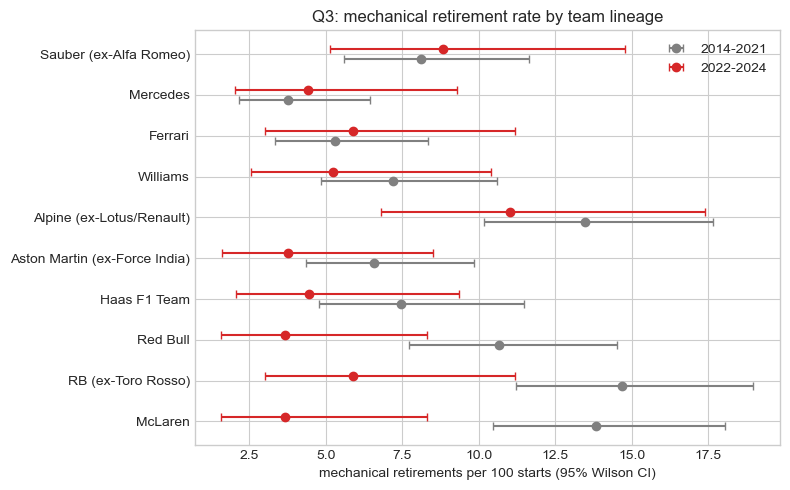

In [70]:
from scipy.stats import fisher_exact

LINEAGE = {"Force India": "Aston Martin (ex-Force India)", "Racing Point": "Aston Martin (ex-Force India)", "Aston Martin": "Aston Martin (ex-Force India)",
           "Toro Rosso": "RB (ex-Toro Rosso)", "AlphaTauri": "RB (ex-Toro Rosso)", "RB F1 Team": "RB (ex-Toro Rosso)",
           "Lotus F1": "Alpine (ex-Lotus/Renault)", "Renault": "Alpine (ex-Lotus/Renault)", "Alpine F1 Team": "Alpine (ex-Lotus/Renault)",
           "Sauber": "Sauber (ex-Alfa Romeo)", "Alfa Romeo": "Sauber (ex-Alfa Romeo)"}
r["team"] = r["constructor"].map(LINEAGE).fillna(r["constructor"])
MIN_STARTS = 100

def wilson_ci(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def bh(p):
    p = np.asarray(p); n = len(p); order = np.argsort(p)
    adj = np.empty(n); prev = 1.0
    for rank, i in reversed(list(enumerate(order, 1))):
        prev = min(prev, p[i] * n / rank); adj[i] = prev
    return adj

def team_table(causes):
    r["is_mech"] = r["cause"].isin(causes).astype(int)
    g = r.groupby(["team", "period"]).agg(starts=("is_mech", "size"), k=("is_mech", "sum")).unstack("period").fillna(0)
    rows = []
    for team, x in g.iterrows():
        n1, n2 = int(x[("starts", "2014-2021")]), int(x[("starts", "2022-2024")])
        k1, k2 = int(x[("k", "2014-2021")]), int(x[("k", "2022-2024")])
        if min(n1, n2) < MIN_STARTS:
            continue
        lo1, hi1 = wilson_ci(k1, n1); lo2, hi2 = wilson_ci(k2, n2)
        _, p = fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])
        rows.append(dict(team=team, n_old=n1, n_new=n2, rate_old=k1 / n1, rate_new=k2 / n2,
                         lo1=lo1, hi1=hi1, lo2=lo2, hi2=hi2, p=p))
    t = pd.DataFrame(rows)
    t["diff_pp"] = (t["rate_new"] - t["rate_old"]) * 100
    t["p_adj"] = bh(t["p"])
    return t.sort_values("diff_pp").reset_index(drop=True)

main = team_table({"mechanical"})
show = main[["team", "n_old", "n_new", "rate_old", "rate_new", "diff_pp", "p", "p_adj"]].copy()
show[["rate_old", "rate_new"]] = (show[["rate_old", "rate_new"]] * 100).round(1)
print(show.round(4).to_string(index=False))

pool = r.assign(m=r["cause"].eq("mechanical").astype(int)).groupby("period")["m"].agg(["sum", "size"])
print("\npooled all teams:", (pool["sum"] / pool["size"] * 100).round(2).to_dict(),
      "| Fisher p =", fisher_exact([[pool.loc["2014-2021", "sum"], pool.loc["2014-2021", "size"] - pool.loc["2014-2021", "sum"]],
                                    [pool.loc["2022-2024", "sum"], pool.loc["2022-2024", "size"] - pool.loc["2022-2024", "sum"]]])[1])

broad = team_table({"mechanical", "gray"})
print("\nSENSITIVITY (gray counted as mechanical): diff_pp and adjusted p per team")
print(broad[["team", "diff_pp", "p_adj"]].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(main))
for col, lo, hi, c, lab, off in [("rate_old", "lo1", "hi1", "gray", "2014-2021", -0.12), ("rate_new", "lo2", "hi2", "tab:red", "2022-2024", 0.12)]:
    ax.errorbar(main[col] * 100, y + off, xerr=[(main[col] - main[lo]) * 100, (main[hi] - main[col]) * 100],
                fmt="o", color=c, capsize=3, label=lab)
ax.set_yticks(y); ax.set_yticklabels(main["team"]); ax.set_xlabel("mechanical retirements per 100 starts (95% Wilson CI)")
ax.legend(); ax.set_title("Q3: mechanical retirement rate by team lineage"); plt.tight_layout(); plt.show()

### [Step 4.3] Q3: Pooled Fisher Test Restricted to 10 Qualifying Teams
> **Purpose**: Re-runs the pooled era-level Fisher's Exact Test using only the 10 constructor lineages that meet the minimum start threshold in both periods, producing the primary hypothesis-test result for Q3.
> **Key Operations**:
> * Filters the race-level DataFrame to rows belonging to the 10 qualifying teams identified in Step 4.2.
> * Aggregates total mechanical retirements and total starts per era for these teams.
> * Constructs a 2×2 contingency table and runs Fisher's Exact Test.
> * Prints pooled mechanical rates (%) per era and the resulting Fisher p-value, providing the definitive answer to whether the era change produced a significant shift in mechanical reliability at the team level.
---

In [71]:
keep = r["team"].isin(main["team"])
p10 = r[keep].assign(m=r.loc[keep, "cause"].eq("mechanical").astype(int)).groupby("period")["m"].agg(["sum", "size"])
a, b = p10.loc["2014-2021"], p10.loc["2022-2024"]
print("10 surviving teams:", (p10["sum"] / p10["size"] * 100).round(2).to_dict(),
      "| Fisher p =", fisher_exact([[a["sum"], a["size"] - a["sum"]], [b["sum"], b["size"] - b["sum"]]])[1])

10 surviving teams: {'2014-2021': 9.15, '2022-2024': 5.69} | Fisher p = 7.794661907419167e-05


### [Step 4.4] Q3: Per-Era Ranked Mechanical Retirement Rate Tables
> **Purpose**: Produces two human-readable ranked tables showing each qualifying team's mechanical retirement count, total starts, and retirement percentage for each regulatory era, ordered from highest to lowest rate, for direct inclusion in the report.
> **Key Operations**:
> * Iterates over both eras (`2014-2021` and `2022-2024`) using their respective rate and start-count columns from the `main` results table.
> * Computes the absolute mechanical retirement count (`rate × starts`, rounded) for each team.
> * Sorts teams by mechanical retirement percentage descending and resets the index to provide a clean ranked display.
> * Prints a formatted table per era with columns: team, starts, mechanical retirements, and rate (%), providing the raw ranked evidence underlying the Q3 conclusion.
---

In [72]:
for label, rate, n in [("2014-2021", "rate_old", "n_old"), ("2022-2024", "rate_new", "n_new")]:
    rk = main[["team", n, rate]].copy()
    rk["mech"] = (rk[rate] * rk[n]).round().astype(int)       # mechanical retirements
    rk["rate_%"] = (rk[rate] * 100).round(1)
    rk = rk.sort_values("rate_%", ascending=False).reset_index(drop=True)
    rk.index += 1
    print(f"\nMechanical-retirement rate, {label} (highest first)")
    print(rk.rename(columns={n: "starts"})[["team", "starts", "mech", "rate_%"]].to_string())


Mechanical-retirement rate, 2014-2021 (highest first)
                             team  starts  mech  rate_%
1              RB (ex-Toro Rosso)     320    47    14.7
2                         McLaren     318    44    13.8
3       Alpine (ex-Lotus/Renault)     319    43    13.5
4                        Red Bull     319    34    10.7
5          Sauber (ex-Alfa Romeo)     320    26     8.1
6                    Haas F1 Team     241    18     7.5
7                        Williams     319    23     7.2
8   Aston Martin (ex-Force India)     319    21     6.6
9                         Ferrari     320    17     5.3
10                       Mercedes     320    12     3.8

Mechanical-retirement rate, 2022-2024 (highest first)
                             team  starts  mech  rate_%
1       Alpine (ex-Lotus/Renault)     136    15    11.0
2          Sauber (ex-Alfa Romeo)     136    12     8.8
3                         Ferrari     136     8     5.9
4              RB (ex-Toro Rosso)     136     8   

### [Step 5.1] Q2: Home Grand Prix Advantage — Feature Construction & Raw Rate Comparison
> **Purpose**: Constructs the binary home-race indicator for every driver-race pair, verifies nationality-to-host-country mappings, and performs an initial raw podium rate comparison between home and away starts before grid-position confounding is controlled for.
> **Key Operations**:
> * Defines `NAT2COUNTRY`: a hand-verified dictionary mapping every nationality string in the dataset to one or more circuit host-country strings, including dual-nationality cases and historical country name changes.
> * Merges driver nationality from `dfs['drivers']` and circuit host country from `dfs['circuits']` onto the base table, asserting zero missing values and no row-count change.
> * Assigns `home = 1` if the driver's nationality maps to the circuit's host country string, else `home = 0`.
> * Prints diagnostics: total home starts, distribution by circuit country, and a list of nationalities with no corresponding home GP in the dataset (e.g. drivers from countries that never hosted an F1 round).
> * Reports the raw (uncontrolled) podium rate comparison between home (home=1) and away (home=0) starts as an initial estimate before controlling for grid-position confounding.
> * Reports grid-position descriptive statistics by home/away flag to detect whether home drivers simply tend to qualify better, which would require grid-position adjustment in subsequent steps.
---

In [73]:
print(sorted(dfs["drivers"]["nationality"].dropna().unique()))
print(sorted(dfs["circuits"]["country"].dropna().unique()))

['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


### [Step 5.2] Q2: Nationality-to-Country Mapping & Home Indicator Assignment
> **Purpose**: Applies the nationality-to-host-country mapping to construct the binary `home` indicator for every driver-race row, then prints diagnostics to validate coverage and detect any mapping gaps.
> **Key Operations**:
> * Defines the full `NAT2COUNTRY` dictionary, including dual-nationality variants (e.g., 'American-Italian' maps to both USA and Italy), and strips trailing whitespace from nationality strings to fix encoding artefacts.
> * Merges driver nationality and circuit host country onto the `q2` analytical table.
> * Assigns `home = 1` if the driver's nationality resolves to the circuit's host country, else `home = 0`, using a list comprehension over the merged rows.
> * Prints total home starts and their distribution by circuit country to verify that expected home GPs (UK, Germany, Italy, etc.) are correctly identified.
> * Lists nationalities with no corresponding home GP in the dataset (drivers whose country never hosted an F1 round).
> * Prints raw podium rate comparison (home vs. away) as the unadjusted starting estimate before grid-position confounding is controlled for in subsequent steps.
---

In [74]:
NAT2COUNTRY = {
    "American": ["USA", "United States"], "American-Italian": ["USA", "United States", "Italy"],
    "Argentine": ["Argentina"], "Argentinian": ["Argentina"], "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"], "Brazilian": ["Brazil"],
    "British": ["UK"], "Canadian": ["Canada"], "Chinese": ["China"], "Dutch": ["Netherlands"],
    "French": ["France"], "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Italian": ["Italy"], "Japanese": ["Japan"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "Portuguese": ["Portugal"], "Russian": ["Russia"],
    "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
}

drv = dfs["drivers"][["driverId", "nationality"]].copy()
drv["nationality"] = drv["nationality"].str.strip()                      # 'Argentinian ' -> 'Argentinian'
circ = dfs["races"][["raceId", "circuitId"]].merge(dfs["circuits"][["circuitId", "country"]], on="circuitId")

q2 = (base[["raceId", "driverId", "year", "grid_clean", "target_podium"]]
      .merge(drv, on="driverId", how="left")
      .merge(circ[["raceId", "country"]], on="raceId", how="left"))
assert len(q2) == len(base), "merge changed the row count"
assert q2["nationality"].notna().all() and q2["country"].notna().all()

q2["home"] = [int(c in NAT2COUNTRY.get(n, [])) for n, c in zip(q2["nationality"], q2["country"])]

print("rows:", len(q2), "| home starts:", int(q2["home"].sum()), f"({q2['home'].mean():.2%})")
print(q2[q2["home"] == 1].groupby("country").size().sort_values(ascending=False).to_string())
print("\nnationalities with no home GP in this data:", sorted(set(q2["nationality"]) - set(NAT2COUNTRY)))
print("\nRAW podium rate (not controlled for grid):")
print(q2.groupby("home")["target_podium"].agg(rate="mean", starts="size").round(4))

rows: 24686 | home starts: 1938 (7.85%)
country
UK               448
Italy            403
France           206
Germany          199
Brazil           115
USA              111
Spain             61
Belgium           60
Japan             54
South Africa      47
Argentina         44
Canada            32
Austria           29
Australia         28
Mexico            24
Netherlands       22
Switzerland       13
Sweden            12
Monaco            10
Russia             8
Portugal           5
Hungary            2
India              2
China              1
Malaysia           1
United States      1

nationalities with no home GP in this data: ['Chilean', 'Colombian', 'Czech', 'Danish', 'East German', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']

RAW podium rate (not controlled for grid):
        rate  starts
home                
0     0.1376   22748
1     0.1187    1938


### [Step 5.3] Q2: Grid Position Distribution by Home/Away & Bin-Level Fisher Tests
> **Purpose**: Checks whether home drivers tend to start from better grid positions than away drivers (a key confounder), and evaluates podium rates within matched grid-position bins to produce a grid-controlled home advantage estimate.
> **Key Operations**:
> * Prints descriptive grid-position statistics (mean and median) separately for home and away starts to quantify the grid-position confounding before adjustment.
> * Bins `grid_clean` into 5 ordinal bands: P1-3, P4-6, P7-10, P11-15, P16+.
> * For each bin, computes home and away podium rates, 95% Wilson CIs, absolute difference in percentage points (`diff_pp`), and a Fisher's Exact p-value.
> * Applies Benjamini–Hochberg FDR correction across the five bin-level tests.
> * Prints the full grid-bin comparison table as the primary grid-stratified Q2 result.
---

In [75]:

print("Starting grid summary (0 = Away, 1 = Home):")
print(q2.groupby("home")["grid_clean"].agg(starts="size", mean_grid="mean", median_grid="median").round(2))

bins = [0, 3, 6, 10, 15, 100]
labels = ["P1-3", "P4-6", "P7-10", "P11-15", "P16+"]
q2["grid_bin"] = pd.cut(q2["grid_clean"], bins=bins, labels=labels)

rows = []
for b in labels:
    sub = q2[q2["grid_bin"] == b]
    a = sub[sub["home"] == 0]["target_podium"]
    h = sub[sub["home"] == 1]["target_podium"]
    n0, k0 = len(a), int(a.sum())
    n1, k1 = len(h), int(h.sum())
    lo0, hi0 = wilson_ci(k0, n0)
    lo1, hi1 = wilson_ci(k1, n1)
    _, p = fisher_exact([[k1, n1 - k1], [k0, n0 - k0]])
    rows.append(dict(grid_bin=b, n_away=n0, n_home=n1,
                     rate_away=k0 / n0, rate_home=k1 / n1,
                     lo0=lo0, hi0=hi0, lo1=lo1, hi1=hi1,
                     diff_pp=(k1 / n1 - k0 / n0) * 100, p=p))

q2_bins = pd.DataFrame(rows)
q2_bins["p_adj"] = bh(q2_bins["p"])

show = q2_bins[["grid_bin", "n_away", "n_home", "rate_away", "rate_home", "diff_pp", "p", "p_adj"]].copy()
show[["rate_away", "rate_home"]] = (show[["rate_away", "rate_home"]] * 100).round(2)
print("\nHome vs. Away podium rate (%) within each grid bin:")
print(show.round(4).to_string(index=False))


Starting grid summary (0 = Away, 1 = Home):
      starts  mean_grid  median_grid
home                                
0      22748      11.76         12.0
1       1938      12.71         13.0

Home vs. Away podium rate (%) within each grid bin:
grid_bin  n_away  n_home  rate_away  rate_home  diff_pp      p  p_adj
    P1-3    3101     229      55.63      57.21   1.5780 0.6793 0.8803
    P4-6    3103     224      26.17      27.23   1.0639 0.7531 0.8803
   P7-10    4101     336       9.39       7.44  -1.9475 0.2805 0.7013
  P11-15    5116     415       3.01       2.65  -0.3596 0.8803 0.8803
    P16+    7327     734       0.72       0.27  -0.4509 0.2348 0.7013


### [Step 5.4] Q2: Cochran–Mantel–Haenszel Test & Logistic Regression Sensitivity Analysis
> **Purpose**: Applies two formal statistical methods — the Cochran–Mantel–Haenszel (CMH) test and a simple logistic regression — to estimate the home advantage odds ratio while controlling for starting grid position across four population subsets.
> **Key Operations**:
> * Defines `cmh_exact_grid(df_sub)`: stratifies by capped grid position (1–20+), computes the Mantel–Haenszel common odds ratio (OR_MH) and the CMH test statistic, returning the OR, z-score, and two-sided p-value.
> * Defines four analysis subsets: all starts 1950–2024, drivers with both home and away starts, modern era (2003–2024), and hybrid era (2014–2024).
> * Runs `cmh_exact_grid` and a simple logistic regression (grid + home) on all four subsets.
> * Assembles a sensitivity table with: subset name, rows, home starts, raw away/home podium rates (%), CMH OR, CMH p, and LogReg OR for direct report citation.
> * Renders two side-by-side charts: (left) a caterpillar plot of home vs. away podium rates by grid bin with 95% Wilson CIs; (right) a grouped bar chart of podium conversion rates by exact starting slot P1–P10.
---

,subset,rows,home_starts,raw_away_%,raw_home_%,CMH_OR,CMH_p,LogReg_OR
0,All starts (1950-2024),24686,1938,13.76,11.87,0.967,0.7039,0.972
1,Drivers with BOTH home & away starts,20376,1788,14.40,12.81,0.970,0.7364,0.973
2,Modern era (2003-2024),8935,365,14.38,14.25,0.757,0.1705,0.814
3,Hybrid/ground-effect era (2014-2024),4612,145,14.78,16.55,0.857,0.6211,0.896


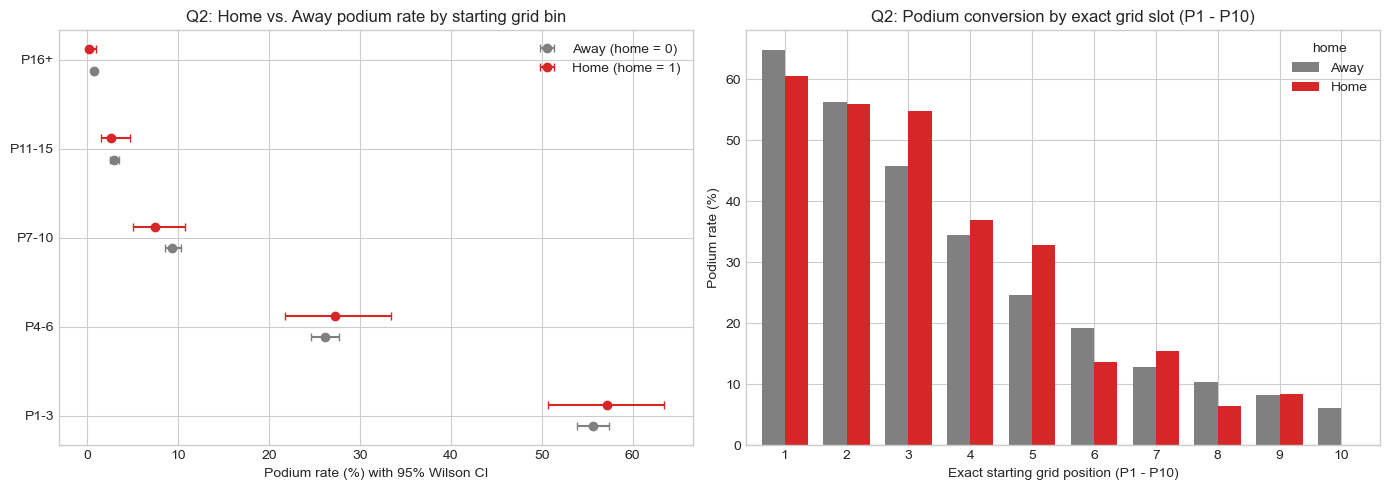

In [76]:

import math
from sklearn.linear_model import LogisticRegression

def cmh_exact_grid(df_sub):
    df_sub = df_sub.assign(g_cap=df_sub["grid_clean"].clip(upper=20))
    num_or, den_or, cmh_num, cmh_var = 0.0, 0.0, 0.0, 0.0
    for _, grp in df_sub.groupby("g_cap"):
        a = int(((grp["home"] == 1) & (grp["target_podium"] == 1)).sum())
        b = int(((grp["home"] == 1) & (grp["target_podium"] == 0)).sum())
        c = int(((grp["home"] == 0) & (grp["target_podium"] == 1)).sum())
        d = int(((grp["home"] == 0) & (grp["target_podium"] == 0)).sum())
        n_tot = a + b + c + d
        if n_tot > 1 and (a + b) > 0 and (c + d) > 0:
            num_or += (a * d) / n_tot
            den_or += (b * c) / n_tot
            e_a = (a + b) * (a + c) / n_tot
            v_a = ((a + b) * (c + d) * (a + c) * (b + d)) / ((n_tot ** 2) * (n_tot - 1))
            cmh_num += (a - e_a)
            cmh_var += v_a
    or_mh = num_or / den_or if den_or > 0 else np.nan
    z_mh = cmh_num / np.sqrt(cmh_var) if cmh_var > 0 else 0.0
    p_mh = math.erfc(abs(z_mh) / math.sqrt(2.0))
    return or_mh, z_mh, p_mh

both_ids = q2.groupby("driverId")["home"].nunique()
both_ids = both_ids[both_ids == 2].index

slices = [
    ("All starts (1950-2024)", q2),
    ("Drivers with BOTH home & away starts", q2[q2["driverId"].isin(both_ids)]),
    ("Modern era (2003-2024)", q2[q2["year"] >= 2003]),
    ("Hybrid/ground-effect era (2014-2024)", q2[q2["year"] >= 2014]),
]

sens_rows = []
for name_slice, sub in slices:
    or_mh, z_mh, p_mh = cmh_exact_grid(sub)
    lr = LogisticRegression(C=1e6, max_iter=500).fit(sub[["grid_clean", "home"]], sub["target_podium"])
    sens_rows.append({
        "subset": name_slice,
        "rows": len(sub),
        "home_starts": int(sub["home"].sum()),
        "raw_away_%": round(sub.loc[sub["home"] == 0, "target_podium"].mean() * 100, 2),
        "raw_home_%": round(sub.loc[sub["home"] == 1, "target_podium"].mean() * 100, 2),
        "CMH_OR": round(or_mh, 3),
        "CMH_p": round(p_mh, 4),
        "LogReg_OR": round(float(np.exp(lr.coef_[0][1])), 3),
    })

display(pd.DataFrame(sens_rows))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

y = np.arange(len(q2_bins))
ax[0].errorbar(q2_bins["rate_away"] * 100, y - 0.12,
               xerr=[(q2_bins["rate_away"] - q2_bins["lo0"]) * 100,
                     (q2_bins["hi0"] - q2_bins["rate_away"]) * 100],
               fmt="o", color="gray", capsize=3, label="Away (home = 0)")
ax[0].errorbar(q2_bins["rate_home"] * 100, y + 0.12,
               xerr=[(q2_bins["rate_home"] - q2_bins["lo1"]) * 100,
                     (q2_bins["hi1"] - q2_bins["rate_home"]) * 100],
               fmt="o", color="tab:red", capsize=3, label="Home (home = 1)")
ax[0].set_yticks(y)
ax[0].set_yticklabels(q2_bins["grid_bin"])
ax[0].set_xlabel("Podium rate (%) with 95% Wilson CI")
ax[0].set_title("Q2: Home vs. Away podium rate by starting grid bin")
ax[0].legend()

top10 = (q2[q2["grid_clean"] <= 10]
         .groupby(["grid_clean", "home"])["target_podium"]
         .mean().unstack() * 100)
top10.rename(columns={0: "Away", 1: "Home"}).plot(
    kind="bar", ax=ax[1], color=["gray", "tab:red"], width=0.75)
ax[1].set_xlabel("Exact starting grid position (P1 - P10)")
ax[1].set_ylabel("Podium rate (%)")
ax[1].set_title("Q2: Podium conversion by exact grid slot (P1 - P10)")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### [Step 5.5] Q2: Logistic GLM with Driver-Clustered Standard Errors
> **Purpose**: Fits a logistic regression with clustered standard errors (clustered by driver) to produce the most conservative and statistically rigorous estimate of the home advantage odds ratio, accounting for repeated measurements of the same driver.
> **Key Operations**:
> * Defines `home_glm(sub)`: fits `statsmodels` logit with `target_podium ~ home + C(g_cap)` (grid position fixed effects, capped at slot 12), using `cov_type='cluster'` with `groups=driverId` to produce cluster-robust standard errors.
> * Extracts the `home` coefficient, its clustered SE, and computes the odds ratio and 95% CI as `exp(b ± 1.96 × se)`.
> * Runs `home_glm` across all four subsets defined in Step 5.4.
> * Prints a table with: subset, home starts, unique home drivers, OR, 95% CI, and p-value, forming the primary GLM evidence for or against a statistically significant home advantage.
---

In [77]:
import statsmodels.formula.api as smf

def home_glm(sub):
    d = sub.assign(g_cap=sub["grid_clean"].clip(upper=12).astype(int))    # slots 1..11, and 12+ merged
    m = smf.logit("target_podium ~ home + C(g_cap)", data=d).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": d["driverId"]})
    b, se = m.params["home"], m.bse["home"]
    return np.exp(b), np.exp(b - 1.96 * se), np.exp(b + 1.96 * se), m.pvalues["home"]

rows = []
for nm, sub in slices:
    orr, lo, hi, p = home_glm(sub)
    rows.append({"subset": nm, "home_starts": int(sub["home"].sum()),
                 "home_drivers": sub.loc[sub["home"] == 1, "driverId"].nunique(),
                 "OR": round(orr, 3), "CI95": f"{lo:.2f}-{hi:.2f}", "p": round(p, 4)})
display(pd.DataFrame(rows))

,subset,home_starts,home_drivers,OR,CI95,p
0,All starts (1950-2024),1938,500,0.958,0.79-1.16,0.6658
1,Drivers with BOTH home & away starts,1788,391,0.964,0.80-1.17,0.7107
2,Modern era (2003-2024),365,74,0.756,0.40-1.43,0.3902
3,Hybrid/ground-effect era (2014-2024),145,38,0.846,0.31-2.33,0.7459


### [Step 3.6b] Decision Threshold Analysis & Confusion Matrix Evaluation
> **Purpose**: Visualises the precision-recall-F1 trade-off across all probability thresholds on the validation set to justify the chosen decision threshold, and evaluates the final model's confusion matrix on both validation and test sets.
> **Key Operations**:
> * Computes precision, recall, and F1 curves over all threshold values on the validation set using `precision_recall_curve`, and plots all three as a function of threshold.
> * Overlays a vertical dashed line at `final_thr` (the validation-optimal threshold) to show where it sits relative to the precision-recall trade-off.
> * For both validation and test sets, applies `final_thr` to produce binary predictions and computes the full confusion matrix (TP, FP, FN, TN).
> * Prints precision, recall, F1, and raw confusion matrix counts per split.
> * Probes F1 sensitivity by evaluating it at ±0.05 and ±0.10 around `final_thr`, confirming the chosen threshold is near the local optimum and not brittle.
> * Compares F1 at the naive 0.5 cut-off vs. the optimised threshold on both splits to quantify the benefit of threshold tuning.
---

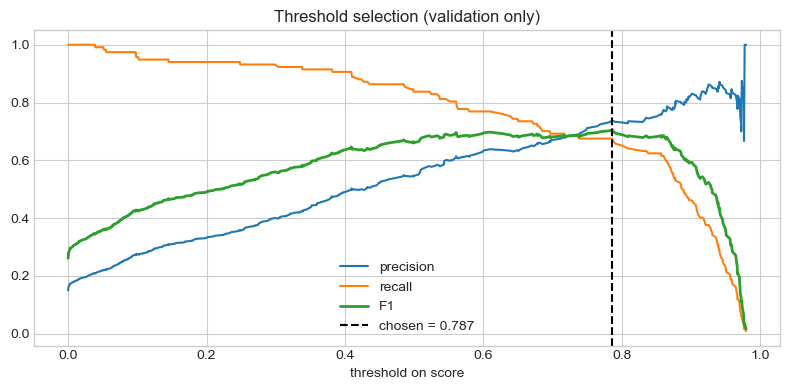

val: precision 0.738 recall 0.675 F1 0.705 | TP 79 FP 28 FN 38 TN 634
test: precision 0.679 recall 0.652 F1 0.665 | TP 133 FP 63 FN 71 TN 1087

VAL F1 around the chosen threshold: {np.float64(0.69): 0.68, np.float64(0.74): 0.687, np.float64(0.79): 0.705, np.float64(0.84): 0.679, np.float64(0.89): 0.611}
naive 0.5 cut-off F1: val 0.662 | test 0.649


In [78]:
from sklearn.metrics import precision_recall_curve, confusion_matrix, precision_score, recall_score

s_val  = final_model.predict_proba(X_val_imp)[:, 1]
s_test = final_model.predict_proba(X_test_imp)[:, 1]

p, rc, t = precision_recall_curve(y_val, s_val)
f1c = 2 * p[:-1] * rc[:-1] / (p[:-1] + rc[:-1] + 1e-12)
plt.figure(figsize=(8, 4))
plt.plot(t, p[:-1], label="precision"); plt.plot(t, rc[:-1], label="recall"); plt.plot(t, f1c, label="F1", lw=2)
plt.axvline(final_thr, color="k", ls="--", label=f"chosen = {final_thr:.3f}")
plt.xlabel("threshold on score"); plt.title("Threshold selection (validation only)")
plt.legend(); plt.tight_layout(); plt.show()

for nm, s, yy in [("val", s_val, y_val), ("test", s_test, y_test)]:
    pred = (s >= final_thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yy, pred).ravel()
    print(f"{nm}: precision {precision_score(yy, pred):.3f} recall {recall_score(yy, pred):.3f} "
          f"F1 {f1_score(yy, pred):.3f} | TP {tp} FP {fp} FN {fn} TN {tn}")

print("\nVAL F1 around the chosen threshold:",
      {round(th, 2): round(float(f1_score(y_val, (s_val >= th).astype(int))), 3)
       for th in [final_thr - 0.1, final_thr - 0.05, final_thr, final_thr + 0.05, final_thr + 0.1]})
print("naive 0.5 cut-off F1: val", round(float(f1_score(y_val, (s_val >= 0.5).astype(int))), 3),
      "| test", round(float(f1_score(y_test, (s_test >= 0.5).astype(int))), 3))

### [Step 3.7] Numerical Reproducibility Audit: Report Value Verification
> **Purpose**: Programmatically verifies that every key numerical claim in the milestone report — row counts, podium rates, model metrics, feature counts, Q1 circuit counts, Q3 retirement rates, and team-level statistics — can be reproduced to within tolerance directly from the live notebook objects.
> **Key Operations**:
> * Defines `chk(label, got_fn, expected, tol=0.0015)`: evaluates a lambda against an expected value and prints `OK` or `CHECK` depending on whether the absolute difference is within tolerance; exceptions are caught and printed as `SKIPPED`.
> * Verifies **data & split**: base rows (24686), podium rate (13.61%), train/val/test row counts, and feature count (17).
> * Verifies **model metrics**: val and test PR-AUC for all 5 models (grid baseline, LogReg, RandomForest, HistGB, ShallowNN).
> * Verifies **final model**: RF decision threshold (≈0.787), val F1 (0.705), test F1 (0.665), test precision (0.679), test recall (0.652), and grid-only baseline test PR-AUC.
> * Verifies **points experiment**: variant A LogReg and RF val PR-AUC.
> * Verifies **Q1**: 14 circuits with sufficient sample in each era.
> * Verifies **Q3**: pooled 2014-21 rate (9.24%), pooled 2022-24 rate (5.69%), and individual team rates for McLaren, RB, and Alpine.
> * Prints `ALL MATCH THE REPORT` if every check passes, or lists the failing labels.
---

In [79]:
import numpy as np, pandas as pd

bad = []
def chk(label, got_fn, expected, tol=0.0015):
    try:
        got = got_fn()
        ok = abs(float(got) - expected) <= tol
        print(f"{'OK   ' if ok else 'CHECK'} {label}: got {float(got):.4f} | report {expected}")
        if not ok: bad.append(label)
    except Exception as e:
        print(f"SKIPPED {label}: {type(e).__name__}: {e}")

# --- data and split ---
chk("base rows",              lambda: len(base), 24686, 0)
chk("podium rate",            lambda: base["target_podium"].mean(), 0.1361, 0.0002)
chk("train rows",             lambda: len(X_train), 22553, 0)
chk("val rows",               lambda: len(X_val), 779, 0)
chk("test rows",              lambda: len(X_test), 1354, 0)
chk("n features",             lambda: len(ALL_FEATURES), 17, 0)

# --- final table (validation / test PR-AUC) ---
F = final.set_index(["model", "split"])
for m, v, t in [("baseline grid<=3", .639, .647), ("LogReg", .724, .686), ("RandomForest", .719, .698),
                ("HistGB", .691, .693), ("ShallowNN", .752, .687)]:
    chk(f"{m} PR-AUC val",  lambda m=m: F.loc[(m, "val"), "PR-AUC"], v)
    chk(f"{m} PR-AUC test", lambda m=m: F.loc[(m, "test"), "PR-AUC"], t)

# --- chosen forest: threshold and F1 ---
chk("RF threshold",   lambda: final_thr, 0.787, 0.005)
T = full_table.set_index(["model", "split"])
chk("RF val F1",      lambda: T.loc[("RandomForest", "val"), "F1"], 0.705)
chk("RF test F1",     lambda: T.loc[("RandomForest", "test"), "F1"], 0.665)
chk("RF test precision", lambda: T.loc[("RandomForest", "test"), "precision"], 0.679)
chk("RF test recall",    lambda: T.loc[("RandomForest", "test"), "recall"], 0.652)
chk("grid-only baseline test PR-AUC", lambda: T.loc[("baseline LogReg (grid only)", "test"), "PR-AUC"], 0.647)

# --- points experiment (variant A row) ---
A = cmp_[cmp_["variant"].str.startswith("A")].iloc[0]
chk("points exp A LogReg val", lambda: A["LogReg val"], 0.724)
chk("points exp A RF val",     lambda: A["RF val (mean)"], 0.721, 0.003)

# --- Q1 ---
chk("Q1 circuits (grid)",       lambda: len(grid_cmp), 14, 0)
chk("Q1 circuits (qualifying)", lambda: len(quali_cmp), 14, 0)

# --- Q3 ---
chk("Q3 pooled 2014-21 %", lambda: pool.loc["2014-2021", "sum"] / pool.loc["2014-2021", "size"] * 100, 9.24, 0.01)
chk("Q3 pooled 2022-24 %", lambda: pool.loc["2022-2024", "sum"] / pool.loc["2022-2024", "size"] * 100, 5.69, 0.01)
M = main.set_index("team")
for team, o, n in [("McLaren", 13.8, 3.7), ("RB (ex-Toro Rosso)", 14.7, 5.9), ("Alpine (ex-Lotus/Renault)", 13.5, 11.0)]:
    chk(f"Q3 {team} 2014-21 %", lambda t=team: M.loc[t, "rate_old"] * 100, o, 0.06)
    chk(f"Q3 {team} 2022-24 %", lambda t=team: M.loc[t, "rate_new"] * 100, n, 0.06)

print("\nALL MATCH THE REPORT" if not bad else f"\nCHECK THESE: {bad}")

OK    base rows: got 24686.0000 | report 24686
OK    podium rate: got 0.1361 | report 0.1361
OK    train rows: got 22553.0000 | report 22553
OK    val rows: got 779.0000 | report 779
OK    test rows: got 1354.0000 | report 1354
OK    n features: got 17.0000 | report 17
OK    baseline grid<=3 PR-AUC val: got 0.6390 | report 0.639
OK    baseline grid<=3 PR-AUC test: got 0.6470 | report 0.647
OK    LogReg PR-AUC val: got 0.7240 | report 0.724
OK    LogReg PR-AUC test: got 0.6860 | report 0.686
OK    RandomForest PR-AUC val: got 0.7190 | report 0.719
OK    RandomForest PR-AUC test: got 0.6980 | report 0.698
OK    HistGB PR-AUC val: got 0.6910 | report 0.691
OK    HistGB PR-AUC test: got 0.6930 | report 0.693
OK    ShallowNN PR-AUC val: got 0.7520 | report 0.752
OK    ShallowNN PR-AUC test: got 0.6870 | report 0.687
OK    RF threshold: got 0.7866 | report 0.787
OK    RF val F1: got 0.7050 | report 0.705
OK    RF test F1: got 0.6650 | report 0.665
OK    RF test precision: got 0.6790 | report